# AML Baseline 1 — ResNet-50 V2 | Clean Retraining & Development Evaluation

**Purpose:** Retrain the selected **Higher Weight Decay** ResNet-50 V2 from ImageNet pretrained weights using the original Stage 1 development split. Produce auditable training histories, persistent progress, checkpoints selected by **individual development HM** and **validation loss**, early transfer candidates, confusion matrices and misclassified-image galleries.

**IMPORTANT:** This is a *new run*, not a continuation of the old model. The output folder is new and isolated; old results are not modified. **Official test data are not used** in any section of this notebook. Run sections in order. Only the explicitly labelled training cells train models.

**Checkpoint policy:** `best.pt` is the canonical baseline checkpoint and optimizes individual seen/unseen accuracy HM; `best_hm.pt` is retained as an identical, clearly labelled copy. `best_val_loss.pt` minimizes the **mean of development-seen and development-unseen cross-entropy losses**, after a configurable 3-epoch warm-up, for an early transfer candidate. These are **different selection objectives**. Low validation loss is evidence of stronger probability calibration on validation data, **not proof of zero overfitting**. Keep both. The raw minimum unseen validation loss is also tracked separately.

**Stage separation:** The main notebook completes *Stage 1* (6,905 train / 695 seen validation / 400 unseen validation). Optional Stage 2 at the end uses all 8,000 images and **cannot use the Stage 1 validation to select an epoch**, because those images become training data. Stage 2 is not run automatically.

**Every-epoch recovery guarantee:** This version archives model weights at **every completed epoch** (FP32, to limit storage), plus full-precision `best.pt` and `early_transfer.pt`. Check sufficient Google Drive capacity before running; preserving all epochs for both ResNet-50 models can require multiple GB.


**Checkpoint storage policy:** each of 30 Crop + 30 Disease epoch archives preserves the original **FP32** model weights. `best.pt` (highest individual development HM) and `early_transfer.pt` (lowest balanced development validation loss after epoch 3) are distinct, full-precision files. No FP16 archive conversion.


## 1 — Mount Drive and import libraries
Run once after each new Colab runtime. Does not train.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, random, time, gc, shutil, subprocess, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet50_Weights
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

DRIVE_PROJECT = Path('/content/drive/MyDrive/DPD-Small')
LOCAL_PROJECT = Path('/content/DPD-Small')
RESULTS_ROOT = Path('/content/drive/MyDrive/AML_B1_ResNet50')

SEED = 42
BATCH_SIZE = 16
NUM_WORKERS = 2
MAX_EPOCHS = 30
EARLY_WARMUP_EPOCHS = 3
SAVE_EVERY_EPOCH = True
ARCHIVE_DTYPE = "float32"
PLOT_EVERY = 5

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'

assert AMP, 'Enable Colab GPU.'
assert DRIVE_PROJECT.is_dir(), f'Missing dataset: {DRIVE_PROJECT}'
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

print('GPU:', torch.cuda.get_device_name(0))
print('Dataset:', DRIVE_PROJECT)
print('Results:', RESULTS_ROOT)


GPU: Tesla T4
Dataset: /content/drive/MyDrive/DPD-Small
Results: /content/drive/MyDrive/AML_B1_ResNet50


## 2 — Copy images and development split metadata
Keep the original `rsync --size-only` method; copy only Stage 1 metadata. Re-running this cell resumes copying existing files.

In [3]:
def find_child(parent, name):
    hits = [p for p in parent.iterdir() if p.name.lower() == name.lower()]
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected {name} in {parent}')
    return hits[0]

LOCAL_PROJECT.mkdir(parents=True, exist_ok=True)

for name in ('images', 'splits_v2'):
    source = find_child(DRIVE_PROJECT, name)
    target = LOCAL_PROJECT / name
    target.mkdir(parents=True, exist_ok=True)

    subprocess.run([
        'rsync', '-rt', '--size-only', '--info=progress2',
        str(source) + '/',
        str(target) + '/'
    ], check=True)

print('Dataset copied successfully.')


Dataset copied successfully.


## 3 — Load development CSVs and verify split integrity
This prevents accidental data overlap and confirms the 55 Crop / 175 Disease label mappings.

In [4]:
# Load development datasets
train_df = pd.read_csv(LOCAL_PROJECT / 'splits_v2/train_fit.csv')
val_seen_df = pd.read_csv(LOCAL_PROJECT / 'splits_v2/val_seen.csv')
val_unseen_df = pd.read_csv(LOCAL_PROJECT / 'splits_v2/val_unseen.csv')

datasets = {
    'train': train_df,
    'seen': val_seen_df,
    'unseen': val_unseen_df
}

assert (len(train_df), len(val_seen_df), len(val_unseen_df)) == (6905, 695, 400)

# Validate dataset splits
for name, df in datasets.items():
    assert {'filename', 'crop_id', 'disease_id'}.issubset(df.columns), name
    assert df.filename.is_unique, name

file_sets = [set(df.filename) for df in datasets.values()]

assert all(
    file_sets[i].isdisjoint(file_sets[j])
    for i in range(3) for j in range(i + 1, 3)
)

def pairs(df):
    return set(map(tuple, df[['crop_id', 'disease_id']].astype(int).to_numpy()))

assert pairs(val_seen_df).issubset(pairs(train_df))
assert pairs(val_unseen_df).isdisjoint(
    pairs(train_df) | pairs(val_seen_df)
)

# Class mappings
crop_ids = sorted(set().union(
    *(set(df.crop_id.astype(int)) for df in datasets.values())
))
disease_ids = sorted(set().union(
    *(set(df.disease_id.astype(int)) for df in datasets.values())
))

assert len(crop_ids) == 55
assert len(disease_ids) == 175
assert set(val_unseen_df.crop_id).issubset(set(train_df.crop_id))
assert set(val_unseen_df.disease_id).issubset(set(train_df.disease_id))

crop_index = {v: i for i, v in enumerate(crop_ids)}
disease_index = {v: i for i, v in enumerate(disease_ids)}

# Index images
image_lookup = {}

for p in tqdm((LOCAL_PROJECT / 'images').rglob('*'), desc='Indexing images'):
    if p.is_file() and p.suffix.lower() in ('.jpg', '.jpeg', '.png', '.webp'):
        assert p.name not in image_lookup, f'Duplicate filename: {p.name}'
        image_lookup[p.name] = p

missing = set().union(*file_sets) - set(image_lookup)
assert not missing, f'Missing images: {sorted(missing)[:10]}'

# Save mappings
(RESULTS_ROOT / 'class_mapping.json').write_text(
    json.dumps({'crop_ids': crop_ids, 'disease_ids': disease_ids}, indent=2)
)

print(f'Train: {len(train_df)} | Seen: {len(val_seen_df)} | Unseen: {len(val_unseen_df)}')
print(f'Classes: {len(crop_ids)} crops | {len(disease_ids)} diseases')
print('Dataset validation: PASS')

display(train_df.head(3))


Indexing images: 0it [00:00, ?it/s]

Train: 6905 | Seen: 695 | Unseen: 400
Classes: 55 crops | 175 diseases
Dataset validation: PASS


,filename,crop_id,disease_id,composition_id,crop_name,disease_name,composition_name
0,BLSD_banana_sigatoka_615.jpeg,2,26,28,banana,sigatoka,banana_sigatoka
1,PD_paddy_bacterial_panicle_blight_1285.jpg,33,120,195,paddy,bacterial_panicle_blight,paddy_bacterial_panicle_blight
2,PWV2_peach_leaf_curl_6128.jpg,36,57,219,peach,curl,peach_curl


## 4 — Image preprocessing
**Deterministic development validation:** Resize(256), CenterCrop(224), Tensor, ImageNet normalization. No random validation augmentation.

In [5]:
IMAGENET_MEAN = (0.485,0.456,0.406)
IMAGENET_STD = (0.229,0.224,0.225)
validation_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
print('DEVELOPMENT VALIDATION PREPROCESSING:')
print(validation_transform)

DEVELOPMENT VALIDATION PREPROCESSING:
Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


## 5 — Training data augmentation
Preserves the previous ResNet-50 V2 setup, including vertical flip. Crop/Disease use exactly the same transforms.

In [6]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85,1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15,contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD),
])
print('TRAINING AUGMENTATION:')
print(train_transform)

TRAINING AUGMENTATION:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


## 6 — Visual check: random original image / augmented views / validation image
Run again to display a new random example. Images are *not* saved as model predictions.

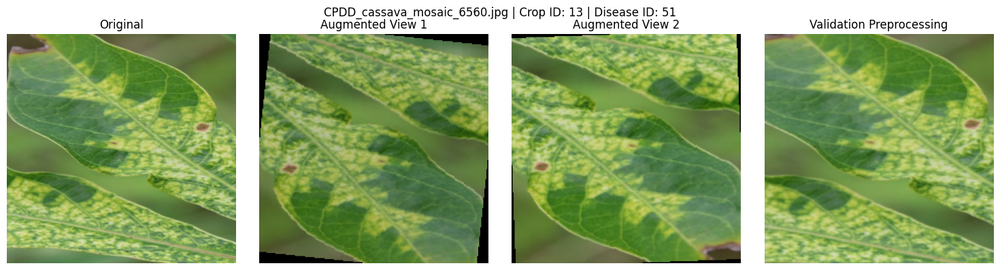

In [7]:
def unnormalize(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

# Select a random training image
row = train_df.sample(1).iloc[0]

with Image.open(image_lookup[str(row.filename)]) as image:
    original = image.convert('RGB')

# Generate image views
views = [
    original,
    unnormalize(train_transform(original)),
    unnormalize(train_transform(original)),
    unnormalize(validation_transform(original))
]

titles = [
    'Original',
    'Augmented View 1',
    'Augmented View 2',
    'Validation Preprocessing'
]

# Display images
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, image, title in zip(axes, views, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')

fig.suptitle(
    f'{row.filename} | Crop ID: {row.crop_id} | Disease ID: {row.disease_id}'
)

plt.tight_layout()
plt.show()


## 7 — Dataset and DataLoaders
The same image returns independent Crop and Disease targets. Class ID ordering is preserved.

In [8]:
class PlantDataset(Dataset):
    def __init__(self, table, transform):
        self.rows = table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]

        with Image.open(image_lookup[str(row.filename)]) as image:
            x = self.transform(image.convert('RGB'))

        crop_label = crop_index[int(row.crop_id)]
        disease_label = disease_index[int(row.disease_id)]

        return x, crop_label, disease_label


def make_loader(table, training=False, batch_size=BATCH_SIZE):
    dataset = PlantDataset(
        table,
        train_transform if training else validation_transform
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        persistent_workers=NUM_WORKERS > 0
    )


seen_loader = make_loader(val_seen_df, batch_size=32)
unseen_loader = make_loader(val_unseen_df, batch_size=32)

print(f'Seen Validation: {len(seen_loader)} batches')
print(f'Unseen Validation: {len(unseen_loader)} batches')


Seen Validation: 22 batches
Unseen Validation: 13 batches


## 8 — Selected Higher Weight Decay hyperparameters
Same configuration as the previously strongest ResNet-50 V2 development experiment. Both CNNs are trained **from ImageNet V2**, not loaded from previous Baseline weights.

In [9]:

EXPERIMENT = 'resnet50_full_best'

BASE_CFG = {
    'backbone': 'resnet50',
    'weights': 'IMAGENET1K_V2',
    'strategy': 'full',
    'backbone_lr': 1e-5,
    'head_lr': 1e-3,
    'weight_decay': 1e-3,
    'batch_size': BATCH_SIZE,
    'epochs': MAX_EPOCHS,
    'seed': SEED,
    'scheduler': 'CosineAnnealingLR(T_max=30)',
    'selection': 'best_hm / warmup_best_balanced_dev_loss',
    'validation': 'DEVELOPMENT ONLY',
    'candidate_policy': 9625
}

DROPOUT = {'crop': 0.3, 'disease': 0.2}

CONFIGS = {
    task: {**BASE_CFG, 'task': task, 'dropout': dropout}
    for task, dropout in DROPOUT.items()
}

for task, config in CONFIGS.items():
    output_dir = RESULTS_ROOT / task
    config_path = output_dir / 'config.json'

    output_dir.mkdir(parents=True, exist_ok=True)

    if config_path.exists():
        assert json.loads(config_path.read_text()) == config, \
            f'Configuration mismatch: {task}'

    config_path.write_text(json.dumps(config, indent=2))

    print(f'{task.upper()} Configuration:')
    display(pd.DataFrame(config.items(), columns=['Parameter', 'Value']))


CROP Configuration:


,Parameter,Value
0,backbone,resnet50
1,weights,IMAGENET1K_V2
2,strategy,full
3,backbone_lr,0.00001
4,head_lr,0.001
5,weight_decay,0.001
6,batch_size,16
7,epochs,30
8,seed,42
9,scheduler,CosineAnnealingLR(T_max=30)


DISEASE Configuration:


,Parameter,Value
0,backbone,resnet50
1,weights,IMAGENET1K_V2
2,strategy,full
3,backbone_lr,0.00001
4,head_lr,0.001
5,weight_decay,0.001
6,batch_size,16
7,epochs,30
8,seed,42
9,scheduler,CosineAnnealingLR(T_max=30)


## 9 — ResNet-50 architecture and optimizer
Full Fine-Tuning: all convolutional layers and the `fc` classifier are trainable. AdamW uses different backbone/head learning rates.

In [10]:

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def build_model(task, pretrained=True):
    weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = models.resnet50(weights=weights)

    num_classes = 55 if task == 'crop' else 175
    in_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(DROPOUT[task]),
        nn.Linear(in_features, num_classes)
    )

    assert all(p.requires_grad for p in model.parameters())
    return model.to(DEVICE)


def make_optimizer(model, config):
    backbone_params = [
        p for name, p in model.named_parameters()
        if not name.startswith('fc.')
    ]
    head_params = list(model.fc.parameters())

    return torch.optim.AdamW(
        [
            {'params': backbone_params, 'lr': config['backbone_lr']},
            {'params': head_params, 'lr': config['head_lr']}
        ],
        weight_decay=config['weight_decay']
    )


def harmonic(a, b):
    return 0.0 if a + b == 0 else 2 * a * b / (a + b)


def save_atomic(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp_path = path.with_name(path.name + '.tmp')

    try:
        torch.save(payload, temp_path)
        os.replace(temp_path, path)
    finally:
        if temp_path.exists():
            temp_path.unlink()


def snapshot(model, task, epoch, metric_name, score):
    return {
        'state_dict': {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        },
        'backbone': 'resnet50',
        'pretrained_weights': 'IMAGENET1K_V2',
        'task': task,
        'epoch': int(epoch),
        'config': CONFIGS[task],
        'crop_ids': crop_ids,
        'disease_ids': disease_ids,
        'selection_metric': metric_name,
        'selection_value': float(score)
    }


def archival_snapshot(model, task, epoch, score):
    checkpoint = snapshot(
        model, task, epoch,
        'epoch_archive_balanced_dev_loss', score
    )
    checkpoint['archive_precision'] = 'original_fp32'
    return checkpoint


def verify_checkpoint(path, task, expected_epoch=None):
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)

    assert checkpoint['task'] == task
    assert checkpoint['backbone'] == 'resnet50'

    if expected_epoch is not None:
        assert checkpoint['epoch'] == expected_epoch

    assert checkpoint['state_dict']
    assert all(
        tensor.dtype != torch.float16
        for tensor in checkpoint['state_dict'].values()
        if tensor.is_floating_point()
    )

    del checkpoint


def capture_rng():
    state = {
        'python': random.getstate(),
        'numpy': np.random.get_state(),
        'torch': torch.get_rng_state()
    }

    if AMP:
        state['cuda'] = torch.cuda.get_rng_state_all()

    return state


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())

    if AMP and 'cuda' in state:
        torch.cuda.set_rng_state_all(state['cuda'])


print('ResNet-50 Full Fine-Tuning ready.')


ResNet-50 Full Fine-Tuning ready.


## 10 — Training and development-validation functions
Training displays a `tqdm` batch progress bar and one persistent metrics line for every epoch. No output-clearing command is used.

In [11]:

def train_epoch(model, loader, task, optimizer, scaler, description):
    model.train()
    criterion = nn.CrossEntropyLoss()

    total = 0
    correct = 0
    loss_sum = 0.0

    for images, crop_labels, disease_labels in tqdm(
        loader, desc=description, leave=True
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = (
            crop_labels if task == 'crop' else disease_labels
        ).to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast('cuda', enabled=AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total += labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        loss_sum += loss.item() * labels.size(0)

    return {
        'loss': loss_sum / total,
        'acc': correct / total
    }


@torch.no_grad()
def evaluate_task(model, loader, task):
    model.eval()
    criterion = nn.CrossEntropyLoss()

    total = 0
    correct = 0
    loss_sum = 0.0

    for images, crop_labels, disease_labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = (
            crop_labels if task == 'crop' else disease_labels
        ).to(DEVICE, non_blocking=True)

        with torch.autocast('cuda', enabled=AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        total += labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        loss_sum += loss.item() * labels.size(0)

    return {
        'loss': loss_sum / total,
        'acc': correct / total
    }


@torch.no_grad()
def predict_log_probs(model, loader):
    model.eval()
    predictions = []

    for images, _, _ in loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast('cuda', enabled=AMP):
            outputs = model(images)

        log_probs = F.log_softmax(outputs.float(), dim=1)
        predictions.append(log_probs.cpu().numpy())

    return np.concatenate(predictions, axis=0)


def save_prediction_arrays(model, folder, prefix):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)

    path = folder / f'{prefix}_validation.npz'
    temp_path = folder / f'{prefix}_validation.npz.tmp'

    with open(temp_path, 'wb') as file:
        np.savez_compressed(
            file,
            seen=predict_log_probs(model, seen_loader),
            unseen=predict_log_probs(model, unseen_loader)
        )

    os.replace(temp_path, path)


print('Training and evaluation functions ready.')


Training and evaluation functions ready.


## 11 — Training curves and checkpoint interpretation
Plots show Training / Development Seen / Development Unseen losses and accuracies, plus HM and the epoch selected by loss. **The graph saved at the best-loss epoch** is the early section; the **full graph** is saved after all epochs. Both remain separate.

In [12]:
def plot_curves(history, task, path, title=None, early_epoch=None, show=True):
    df = pd.DataFrame(history)
    epochs = df['epoch'].to_numpy()

    fig, axes = plt.subplots(1, 3, figsize=(17, 4))

    # Loss
    for key, label in [
        ('train_loss', 'Train'),
        ('seen_loss', 'Dev Seen'),
        ('unseen_loss', 'Dev Unseen'),
        ('balanced_val_loss', 'Balanced Dev Loss')
    ]:
        axes[0].plot(epochs, df[key], marker='.', label=label)

    # Accuracy
    for key, label in [
        ('train_acc', 'Train'),
        ('seen_acc', 'Dev Seen'),
        ('unseen_acc', 'Dev Unseen')
    ]:
        axes[1].plot(epochs, df[key] * 100, marker='.', label=label)

    # Individual HM
    axes[2].plot(
        epochs, df['individual_h'] * 100,
        marker='.', label='Individual HM'
    )
    axes[2].plot(
        epochs, df['best_h'] * 100,
        linestyle='--', label='Best HM'
    )

    # Mark early transfer checkpoint
    if early_epoch is not None and early_epoch in epochs:
        for ax in axes:
            ax.axvline(
                early_epoch,
                linestyle=':',
                label=f'Early Checkpoint: Epoch {early_epoch}'
            )

    # Graph formatting
    titles = [
        'Cross-Entropy Loss',
        'Top-1 Accuracy',
        'Individual Development HM'
    ]
    ylabels = ['Loss', 'Accuracy (%)', 'HM (%)']

    for ax, graph_title, ylabel in zip(axes, titles, ylabels):
        ax.set_title(graph_title)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=7)

    fig.suptitle(
        title or f'{task.title()} | ResNet-50 V2 | Development Validation'
    )

    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches='tight')

    if show:
        display(fig)

    plt.close(fig)


print('Training curves ready.')


Training curves ready.


## 12 — Resumable training with **two separate checkpoint purposes**

**Baseline:** `best.pt` (and matching `best_hm.pt`) stores the epoch with the **highest individual Development Seen/Unseen HM**. This is the checkpoint subsequently loaded for **Stage 2 Full-Data Fine-Tuning**; it does **not** choose the highest training accuracy.

**Team handover:** `best_val_loss.pt` stores the **lowest balanced development validation loss** after the 3-epoch warm-up; `early_transfer.pt` is a separate copy to share with teammates. This is a **candidate before pronounced overfitting**, not a guarantee that no overfitting has occurred. Inspect the entire training/validation loss curves and the saved **every-epoch** snapshots (Epoch 1–30) before choosing it.

**Recovery:** `resume_state.pt` holds the newest model/optimizer/scheduler state for interrupt recovery. Every file remains separate; neither checkpoint policy overwrites the other. The run does not automatically stop at the earliest loss minimum.

**No missed epoch:** Save `epoch_01.pt` through `epoch_30.pt` for each CNN after validation, using FP32 archive copies to conserve Google Drive storage. This allows post-training choice of any exact epoch without retraining. The `best.pt` and `early_transfer.pt` models retain full-precision weights. FP32 archival copies are suitable as approximate transfer initializations but are not bitwise-identical to original FP32 weights.

**Interruption protection:** `early_transfer.pt` is updated immediately whenever the balanced validation loss improves, not only after the final epoch. Check available Google Drive storage first: the complete two-model archive can require several GB.


In [13]:

def run_training(task, target_epoch=MAX_EPOCHS):
    assert task in ('crop', 'disease')
    assert 1 <= target_epoch <= MAX_EPOCHS

    folder = RESULTS_ROOT / task
    cfg = CONFIGS[task]

    history_path = folder / 'history.csv'
    resume_path = folder / 'resume_state.pt'

    # Resume existing training
    state = None

    if resume_path.exists():
        state = torch.load(resume_path, map_location='cpu', weights_only=False)
        assert state['config'] == cfg
        assert state['task'] == task

        if state['epoch'] >= target_epoch:
            print(f'{task.upper()} already completed Epoch {state["epoch"]}.')
            return
    else:
        assert not history_path.exists(), \
            f'Existing history without resume checkpoint: {folder}'

    # Initialise model and optimizer
    seed_all()

    model = build_model(task, pretrained=state is None)
    optimizer = make_optimizer(model, cfg)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=MAX_EPOCHS
    )
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)

    history = []
    best_h = -1.0
    best_loss = float('inf')
    best_h_epoch = 0
    best_loss_epoch = 0
    start_epoch = 1

    # Restore previous training state
    if state is not None:
        model.load_state_dict(state['model_state'])
        optimizer.load_state_dict(state['optimizer_state'])
        scheduler.load_state_dict(state['scheduler_state'])
        scaler.load_state_dict(state['scaler_state'])

        history = state['history']
        best_h = state['best_h']
        best_loss = state['best_loss']
        best_h_epoch = state['best_h_epoch']
        best_loss_epoch = state['best_loss_epoch']
        start_epoch = state['epoch'] + 1

        restore_rng(state['rng'])

    train_loader = make_loader(train_df, training=True, batch_size=BATCH_SIZE)

    print(f'\nTraining {task.upper()} | Epoch {start_epoch}–{target_epoch}')

    try:
        for epoch in range(start_epoch, target_epoch + 1):
            start_time = time.time()

            # Training
            train_metrics = train_epoch(
                model, train_loader, task, optimizer, scaler,
                f'{task.upper()} Epoch {epoch}/{target_epoch}'
            )

            # Development validation
            seen = evaluate_task(model, seen_loader, task)
            unseen = evaluate_task(model, unseen_loader, task)

            hm = harmonic(seen['acc'], unseen['acc'])
            balanced_loss = (seen['loss'] + unseen['loss']) / 2

            # Save best HM checkpoint
            if hm > best_h + 1e-9:
                best_h = hm
                best_h_epoch = epoch

                save_atomic(
                    snapshot(model, task, epoch, 'individual_development_hm', hm),
                    folder / 'best.pt'
                )

                shutil.copy2(folder / 'best.pt', folder / 'best_hm.pt')
                save_prediction_arrays(model, folder, 'best_hm')

            # Save lowest validation loss checkpoint
            if (
                epoch >= EARLY_WARMUP_EPOCHS
                and balanced_loss < best_loss - 1e-9
            ):
                best_loss = balanced_loss
                best_loss_epoch = epoch

                save_atomic(
                    snapshot(
                        model, task, epoch,
                        'balanced_development_cross_entropy',
                        balanced_loss
                    ),
                    folder / 'best_val_loss.pt'
                )

                save_prediction_arrays(model, folder, 'best_val_loss')

                shutil.copy2(
                    folder / 'best_val_loss.pt',
                    folder / 'early_transfer.pt'
                )
                verify_checkpoint(folder / 'early_transfer.pt', task, epoch)

            # Save every epoch (FP32)
            if SAVE_EVERY_EPOCH:
                archive_path = folder / f'epoch_{epoch:02d}.pt'

                if archive_path.exists():
                    verify_checkpoint(archive_path, task, epoch)

                    archived = torch.load(
                        archive_path, map_location='cpu', weights_only=False
                    )

                    assert all(
                        torch.equal(
                            value.detach().cpu(),
                            archived['state_dict'][key]
                        )
                        for key, value in model.state_dict().items()
                    ), f'Checkpoint mismatch at Epoch {epoch}'

                    del archived

                else:
                    save_atomic(
                        archival_snapshot(model, task, epoch, balanced_loss),
                        archive_path
                    )
                    verify_checkpoint(archive_path, task, epoch)

            # Record history
            history.append({
                'epoch': epoch,
                'train_loss': train_metrics['loss'],
                'train_acc': train_metrics['acc'],
                'seen_loss': seen['loss'],
                'seen_acc': seen['acc'],
                'unseen_loss': unseen['loss'],
                'unseen_acc': unseen['acc'],
                'balanced_val_loss': balanced_loss,
                'individual_h': hm,
                'best_h': best_h,
                'seconds': time.time() - start_time
            })

            scheduler.step()

            # Save resume state
            resume_state = {
                'task': task,
                'config': cfg,
                'epoch': epoch,
                'history': copy.deepcopy(history),
                'best_h': best_h,
                'best_loss': best_loss,
                'best_h_epoch': best_h_epoch,
                'best_loss_epoch': best_loss_epoch,
                'model_state': {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                },
                'optimizer_state': optimizer.state_dict(),
                'scheduler_state': scheduler.state_dict(),
                'scaler_state': scaler.state_dict(),
                'rng': capture_rng()
            }

            save_atomic(resume_state, resume_path)

            pd.DataFrame(history).to_csv(history_path, index=False)

            # Save epoch log
            with open(folder / 'epoch_log.txt', 'a') as file:
                file.write(
                    f'Epoch {epoch}/{target_epoch} | '
                    f'Train: {train_metrics["acc"]:.2%} | '
                    f'Seen: {seen["acc"]:.2%} | '
                    f'Unseen: {unseen["acc"]:.2%} | '
                    f'HM: {hm:.2%} | '
                    f'Balanced Loss: {balanced_loss:.4f} | '
                    f'Best HM Epoch: {best_h_epoch} | '
                    f'Best Loss Epoch: {best_loss_epoch}\n'
                )

            # Display epoch results
            print(
                f'{task.upper()} | Epoch {epoch:02d}/{target_epoch} | '
                f'Train: {train_metrics["acc"]:.2%} ({train_metrics["loss"]:.4f}) | '
                f'Seen: {seen["acc"]:.2%} ({seen["loss"]:.4f}) | '
                f'Unseen: {unseen["acc"]:.2%} ({unseen["loss"]:.4f}) | '
                f'HM: {hm:.2%} | '
                f'Balanced Loss: {balanced_loss:.4f} | '
                f'Best HM: E{best_h_epoch} | '
                f'Best Loss: E{best_loss_epoch}',
                flush=True
            )

            # Plot progress
            if epoch % PLOT_EVERY == 0 or epoch == target_epoch:
                plot_curves(
                    history,
                    task,
                    folder / f'progress_epoch_{epoch:02d}.png',
                    title=f'{task.title()} | Progress through Epoch {epoch}',
                    early_epoch=best_loss_epoch or None
                )

        # Save final graphs
        plot_curves(
            history,
            task,
            folder / 'full_training_curves.png',
            early_epoch=best_loss_epoch or None
        )

        if best_loss_epoch:
            early_history = [
                record for record in history
                if record['epoch'] <= best_loss_epoch
            ]

            plot_curves(
                early_history,
                task,
                folder / 'before_overfitting_candidate_curves.png',
                title=f'{task.title()} | Early Transfer Candidate',
                early_epoch=best_loss_epoch
            )

        # Save checkpoint summary
        summary = pd.DataFrame([{
            'task': task,
            'best_hm_epoch': best_h_epoch,
            'best_hm': best_h,
            'best_balanced_loss_epoch': best_loss_epoch,
            'best_balanced_val_loss': best_loss,
            'completed_epoch': target_epoch
        }])

        summary.to_csv(
            folder / 'checkpoint_selection.csv',
            index=False
        )

        print(
            f'\nCompleted {task.upper()} | '
            f'Best HM: Epoch {best_h_epoch} | '
            f'Best Loss: Epoch {best_loss_epoch}'
        )

    finally:
        del model, optimizer, scheduler, scaler, train_loader
        gc.collect()
        torch.cuda.empty_cache()


print('Training function ready.')


Training function ready.


### Preflight — Checkpoint protection and FP32 archive policy

Run this **before** the Crop/Disease training cells. Confirms dataset counts, checkpoint paths, 30-epoch FP32 archiving, and the distinction between the two checkpoint policies. This does not train anything. Existing output directories are only read; no previous experiments are deleted.


In [14]:
# Verify training configuration
assert SAVE_EVERY_EPOCH and ARCHIVE_DTYPE == 'float32'
assert (len(train_df), len(val_seen_df), len(val_unseen_df)) == (6905, 695, 400)
assert MAX_EPOCHS == 30
assert NUM_WORKERS == 2
assert BATCH_SIZE == 16

# Verify checkpoint directories
for task in ('crop', 'disease'):
    directory = RESULTS_ROOT / task
    directory.mkdir(parents=True, exist_ok=True)

    existing = sorted(directory.glob('epoch_*.pt'))

    print(f'{task.upper()}:')
    print(f'  Checkpoint Directory: {directory}')
    print(f'  Saved Epoch Checkpoints: {len(existing)}')

print('\nPre-training checks passed.')


CROP:
  Checkpoint Directory: /content/drive/MyDrive/AML_B1_ResNet50/crop
  Saved Epoch Checkpoints: 30
DISEASE:
  Checkpoint Directory: /content/drive/MyDrive/AML_B1_ResNet50/disease
  Saved Epoch Checkpoints: 30

Pre-training checks passed.


## 13 — Train Crop CNN (30 epochs)
Executes the actual new ImageNet-V2 initialization and full fine-tuning. Progress and intermediate graphs remain visible; every epoch is saved.

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 201MB/s]



Training CROP | Epoch 1–30


CROP Epoch 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 01/30 | Train: 68.56% (1.3015) | Seen: 77.99% (0.9262) | Unseen: 54.00% (2.3525) | HM: 63.81% | Balanced Loss: 1.6393 | Best HM: E1 | Best Loss: E0


CROP Epoch 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

... (3 outputs left out)

CROP Epoch 4/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 04/30 | Train: 92.93% (0.2516) | Seen: 87.48% (0.5570) | Unseen: 63.25% (2.7155) | HM: 73.42% | Balanced Loss: 1.6363 | Best HM: E3 | Best Loss: E3


CROP Epoch 5/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 05/30 | Train: 94.93% (0.1828) | Seen: 88.06% (0.5117) | Unseen: 69.75% (2.5770) | HM: 77.84% | Balanced Loss: 1.5443 | Best HM: E5 | Best Loss: E3


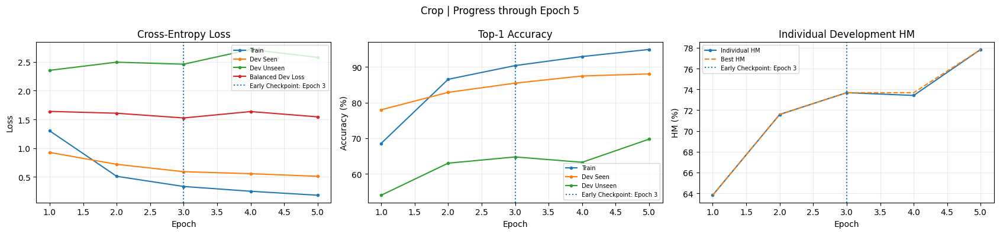

CROP Epoch 6/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 06/30 | Train: 95.74% (0.1520) | Seen: 86.91% (0.5410) | Unseen: 65.50% (2.9904) | HM: 74.70% | Balanced Loss: 1.7657 | Best HM: E5 | Best Loss: E3


CROP Epoch 7/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 07/30 | Train: 96.41% (0.1209) | Seen: 87.77% (0.5208) | Unseen: 67.75% (2.8486) | HM: 76.47% | Balanced Loss: 1.6847 | Best HM: E5 | Best Loss: E3


CROP Epoch 8/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 08/30 | Train: 97.09% (0.1017) | Seen: 88.78% (0.5279) | Unseen: 68.50% (3.1658) | HM: 77.33% | Balanced Loss: 1.8469 | Best HM: E5 | Best Loss: E3


CROP Epoch 9/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 09/30 | Train: 97.58% (0.0808) | Seen: 88.92% (0.5004) | Unseen: 71.25% (2.9356) | HM: 79.11% | Balanced Loss: 1.7180 | Best HM: E9 | Best Loss: E3


CROP Epoch 10/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 10/30 | Train: 97.86% (0.0792) | Seen: 87.34% (0.5656) | Unseen: 68.25% (3.2060) | HM: 76.62% | Balanced Loss: 1.8858 | Best HM: E9 | Best Loss: E3


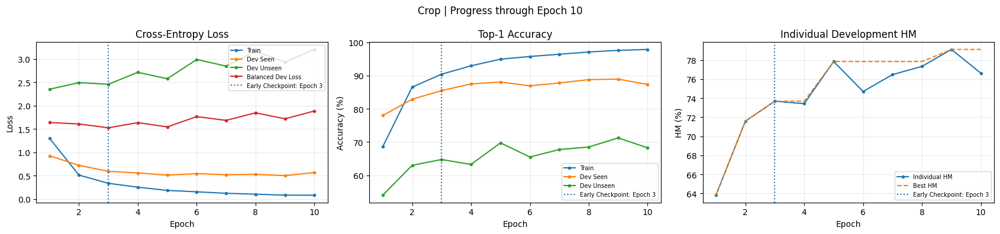

CROP Epoch 11/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 11/30 | Train: 98.06% (0.0643) | Seen: 87.63% (0.5410) | Unseen: 70.75% (3.0583) | HM: 78.29% | Balanced Loss: 1.7997 | Best HM: E9 | Best Loss: E3


CROP Epoch 12/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 12/30 | Train: 98.52% (0.0542) | Seen: 87.63% (0.5494) | Unseen: 68.25% (3.2434) | HM: 76.73% | Balanced Loss: 1.8964 | Best HM: E9 | Best Loss: E3


CROP Epoch 13/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 13/30 | Train: 98.33% (0.0538) | Seen: 88.49% (0.5649) | Unseen: 70.75% (3.3982) | HM: 78.63% | Balanced Loss: 1.9816 | Best HM: E9 | Best Loss: E3


CROP Epoch 14/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 14/30 | Train: 98.80% (0.0448) | Seen: 88.20% (0.5792) | Unseen: 69.25% (3.4358) | HM: 77.59% | Balanced Loss: 2.0075 | Best HM: E9 | Best Loss: E3


CROP Epoch 15/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 15/30 | Train: 98.90% (0.0380) | Seen: 89.50% (0.5699) | Unseen: 72.75% (3.3545) | HM: 80.26% | Balanced Loss: 1.9622 | Best HM: E15 | Best Loss: E3


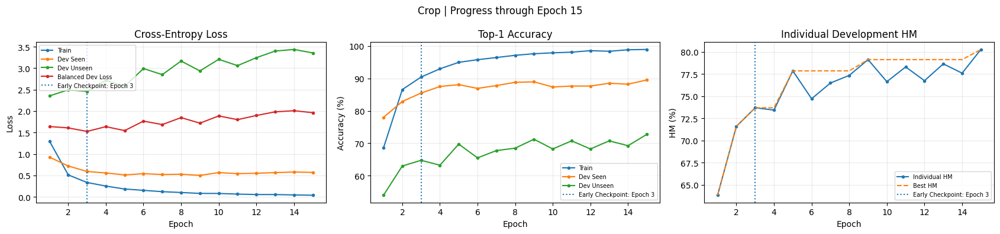

CROP Epoch 16/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 16/30 | Train: 98.78% (0.0418) | Seen: 88.63% (0.5548) | Unseen: 69.75% (3.2040) | HM: 78.07% | Balanced Loss: 1.8794 | Best HM: E15 | Best Loss: E3


CROP Epoch 17/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 17/30 | Train: 99.03% (0.0357) | Seen: 88.49% (0.6045) | Unseen: 70.25% (3.2458) | HM: 78.32% | Balanced Loss: 1.9252 | Best HM: E15 | Best Loss: E3


CROP Epoch 18/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 18/30 | Train: 98.80% (0.0354) | Seen: 89.35% (0.5672) | Unseen: 70.50% (3.4457) | HM: 78.81% | Balanced Loss: 2.0065 | Best HM: E15 | Best Loss: E3


CROP Epoch 19/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 19/30 | Train: 99.25% (0.0274) | Seen: 89.21% (0.6110) | Unseen: 71.00% (3.5829) | HM: 79.07% | Balanced Loss: 2.0970 | Best HM: E15 | Best Loss: E3


CROP Epoch 20/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 20/30 | Train: 99.10% (0.0307) | Seen: 89.21% (0.6010) | Unseen: 71.75% (3.4928) | HM: 79.53% | Balanced Loss: 2.0469 | Best HM: E15 | Best Loss: E3


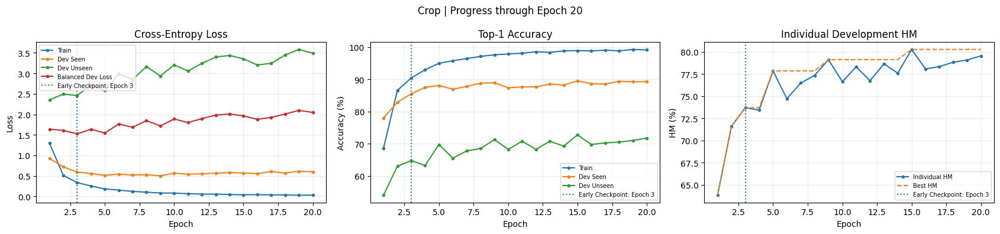

CROP Epoch 21/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 21/30 | Train: 99.25% (0.0293) | Seen: 89.78% (0.5996) | Unseen: 73.00% (3.4245) | HM: 80.53% | Balanced Loss: 2.0120 | Best HM: E21 | Best Loss: E3


CROP Epoch 22/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 22/30 | Train: 99.36% (0.0230) | Seen: 89.35% (0.6007) | Unseen: 71.25% (3.5508) | HM: 79.28% | Balanced Loss: 2.0757 | Best HM: E21 | Best Loss: E3


CROP Epoch 23/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 23/30 | Train: 99.45% (0.0226) | Seen: 88.78% (0.5946) | Unseen: 72.00% (3.4499) | HM: 79.51% | Balanced Loss: 2.0222 | Best HM: E21 | Best Loss: E3


CROP Epoch 24/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 24/30 | Train: 99.23% (0.0244) | Seen: 90.07% (0.5733) | Unseen: 71.25% (3.4223) | HM: 79.56% | Balanced Loss: 1.9978 | Best HM: E21 | Best Loss: E3


CROP Epoch 25/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 25/30 | Train: 99.36% (0.0234) | Seen: 89.78% (0.5996) | Unseen: 71.75% (3.5476) | HM: 79.76% | Balanced Loss: 2.0736 | Best HM: E21 | Best Loss: E3


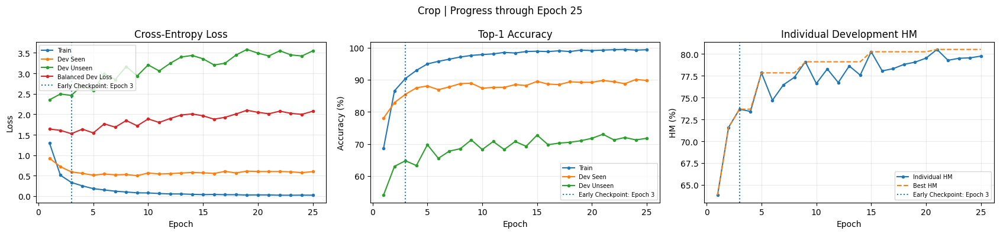

CROP Epoch 26/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 26/30 | Train: 99.41% (0.0224) | Seen: 89.64% (0.6050) | Unseen: 70.25% (3.5401) | HM: 78.77% | Balanced Loss: 2.0725 | Best HM: E21 | Best Loss: E3


CROP Epoch 27/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 27/30 | Train: 99.48% (0.0213) | Seen: 90.22% (0.5960) | Unseen: 72.00% (3.4950) | HM: 80.09% | Balanced Loss: 2.0455 | Best HM: E21 | Best Loss: E3


CROP Epoch 28/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 28/30 | Train: 99.35% (0.0231) | Seen: 89.35% (0.5875) | Unseen: 70.00% (3.4229) | HM: 78.50% | Balanced Loss: 2.0052 | Best HM: E21 | Best Loss: E3


CROP Epoch 29/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 29/30 | Train: 99.52% (0.0187) | Seen: 89.50% (0.5967) | Unseen: 71.50% (3.4664) | HM: 79.49% | Balanced Loss: 2.0315 | Best HM: E21 | Best Loss: E3


CROP Epoch 30/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP | Epoch 30/30 | Train: 99.48% (0.0192) | Seen: 90.07% (0.5927) | Unseen: 71.75% (3.4926) | HM: 79.87% | Balanced Loss: 2.0426 | Best HM: E21 | Best Loss: E3


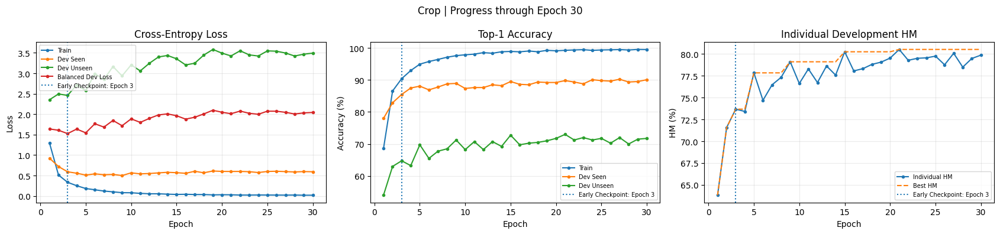

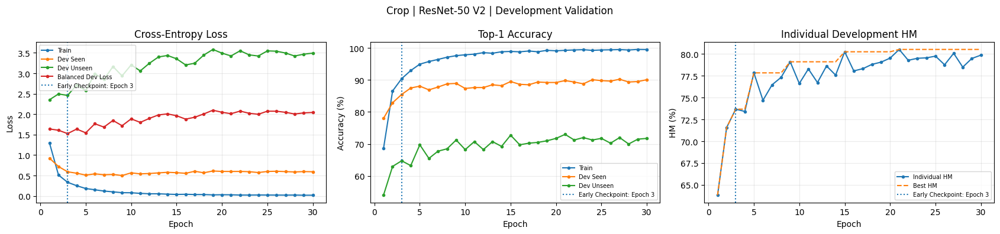

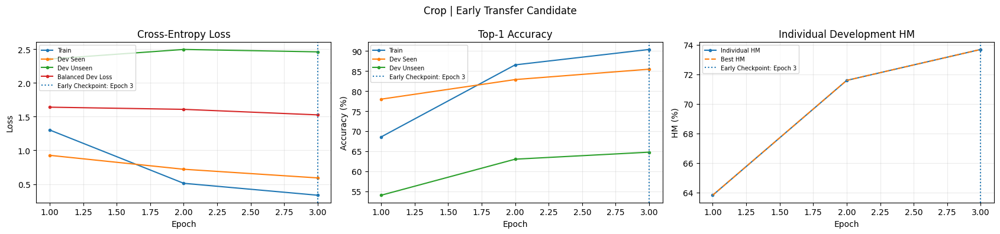


Completed CROP | Best HM: Epoch 21 | Best Loss: Epoch 3


In [ ]:
run_training('crop', target_epoch=MAX_EPOCHS)

## 14 — Train Disease CNN (30 epochs)
Independent ImageNet-V2 initialization; the same backbone LR, head LR, weight decay, scheduler and augmentation, with Disease dropout `0.2`.


Training DISEASE | Epoch 1–30


DISEASE Epoch 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 01/30 | Train: 44.87% (2.4233) | Seen: 56.69% (1.9755) | Unseen: 14.50% (5.8865) | HM: 23.09% | Balanced Loss: 3.9310 | Best HM: E1 | Best Loss: E0


DISEASE Epoch 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 02/30 | Train: 66.46% (1.2320) | Seen: 64.17% (1.5100) | Unseen: 14.50% (6.5955) | HM: 23.66% | Balanced Loss: 4.0527 | Best HM: E2 | Best Loss: E0


DISEASE Epoch 3/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 03/30 | Train: 74.28% (0.8810) | Seen: 68.06% (1.3479) | Unseen: 16.75% (6.5404) | HM: 26.88% | Balanced Loss: 3.9441 | Best HM: E3 | Best Loss: E3


DISEASE Epoch 4/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 04/30 | Train: 79.10% (0.6900) | Seen: 71.51% (1.2423) | Unseen: 19.50% (7.0308) | HM: 30.64% | Balanced Loss: 4.1365 | Best HM: E4 | Best Loss: E3


DISEASE Epoch 5/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 05/30 | Train: 81.78% (0.5734) | Seen: 72.66% (1.2247) | Unseen: 20.75% (7.3190) | HM: 32.28% | Balanced Loss: 4.2718 | Best HM: E5 | Best Loss: E3


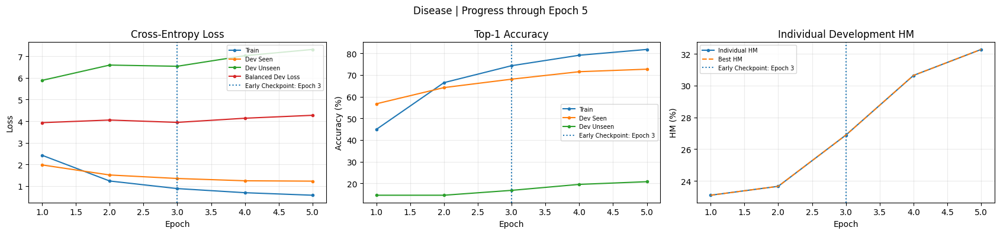

DISEASE Epoch 6/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 06/30 | Train: 85.16% (0.4717) | Seen: 70.94% (1.2128) | Unseen: 21.25% (7.3636) | HM: 32.70% | Balanced Loss: 4.2882 | Best HM: E6 | Best Loss: E3


DISEASE Epoch 7/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 07/30 | Train: 86.73% (0.4136) | Seen: 72.95% (1.2333) | Unseen: 20.75% (7.9716) | HM: 32.31% | Balanced Loss: 4.6025 | Best HM: E6 | Best Loss: E3


DISEASE Epoch 8/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 08/30 | Train: 89.08% (0.3560) | Seen: 73.96% (1.2355) | Unseen: 20.25% (8.0970) | HM: 31.79% | Balanced Loss: 4.6662 | Best HM: E6 | Best Loss: E3


DISEASE Epoch 9/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 09/30 | Train: 89.56% (0.3242) | Seen: 74.24% (1.2540) | Unseen: 22.25% (8.3947) | HM: 34.24% | Balanced Loss: 4.8243 | Best HM: E9 | Best Loss: E3


DISEASE Epoch 10/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 10/30 | Train: 90.53% (0.2916) | Seen: 73.53% (1.2604) | Unseen: 22.00% (7.7448) | HM: 33.87% | Balanced Loss: 4.5026 | Best HM: E9 | Best Loss: E3


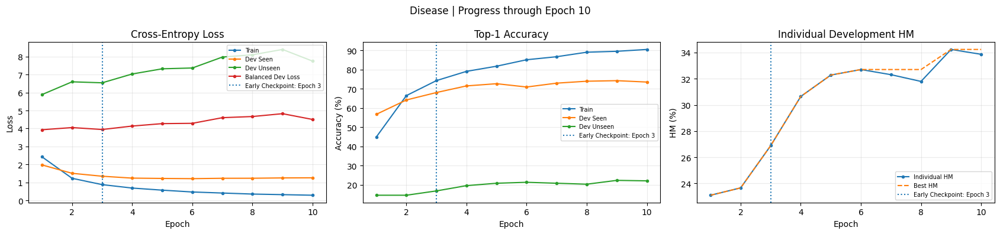

DISEASE Epoch 11/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 11/30 | Train: 91.80% (0.2589) | Seen: 74.24% (1.2664) | Unseen: 22.50% (7.9827) | HM: 34.53% | Balanced Loss: 4.6246 | Best HM: E11 | Best Loss: E3


DISEASE Epoch 12/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 12/30 | Train: 92.25% (0.2290) | Seen: 74.82% (1.3310) | Unseen: 23.25% (8.8511) | HM: 35.48% | Balanced Loss: 5.0910 | Best HM: E12 | Best Loss: E3


DISEASE Epoch 13/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 13/30 | Train: 93.35% (0.2093) | Seen: 75.11% (1.3181) | Unseen: 25.00% (8.7425) | HM: 37.51% | Balanced Loss: 5.0303 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 14/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 14/30 | Train: 93.67% (0.1936) | Seen: 76.12% (1.3459) | Unseen: 20.00% (8.9504) | HM: 31.68% | Balanced Loss: 5.1481 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 15/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 15/30 | Train: 93.85% (0.1790) | Seen: 75.11% (1.3476) | Unseen: 23.00% (9.0969) | HM: 35.22% | Balanced Loss: 5.2223 | Best HM: E13 | Best Loss: E3


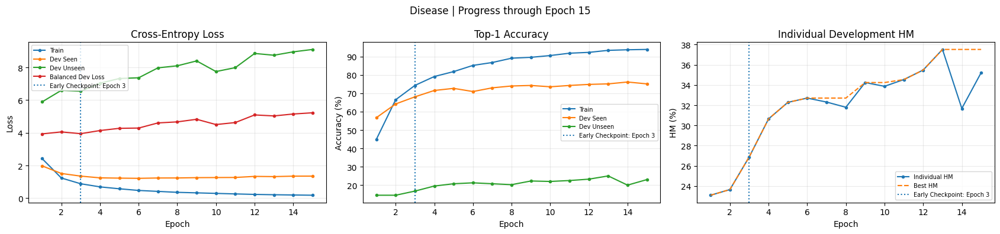

DISEASE Epoch 16/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 16/30 | Train: 94.58% (0.1675) | Seen: 75.25% (1.3394) | Unseen: 21.75% (9.1708) | HM: 33.75% | Balanced Loss: 5.2551 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 17/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 17/30 | Train: 95.09% (0.1520) | Seen: 76.40% (1.3342) | Unseen: 23.25% (9.5618) | HM: 35.65% | Balanced Loss: 5.4480 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 18/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 18/30 | Train: 95.51% (0.1469) | Seen: 76.12% (1.3567) | Unseen: 21.75% (9.6449) | HM: 33.83% | Balanced Loss: 5.5008 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 19/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 19/30 | Train: 95.67% (0.1370) | Seen: 75.83% (1.3548) | Unseen: 22.25% (9.7739) | HM: 34.40% | Balanced Loss: 5.5643 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 20/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 20/30 | Train: 96.06% (0.1294) | Seen: 76.40% (1.3865) | Unseen: 22.50% (9.6437) | HM: 34.76% | Balanced Loss: 5.5151 | Best HM: E13 | Best Loss: E3


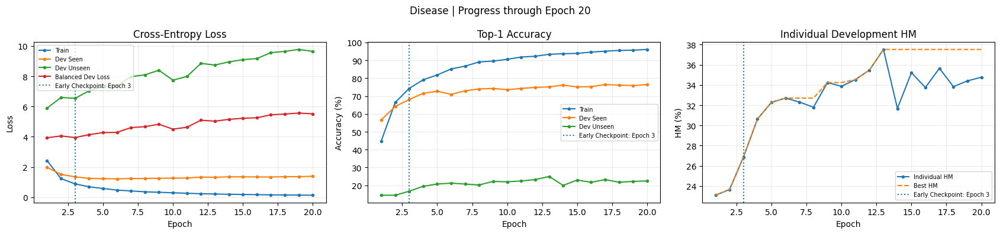

DISEASE Epoch 21/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 21/30 | Train: 95.77% (0.1292) | Seen: 76.40% (1.3567) | Unseen: 23.50% (9.8144) | HM: 35.94% | Balanced Loss: 5.5856 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 22/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 22/30 | Train: 96.67% (0.1157) | Seen: 76.40% (1.3982) | Unseen: 24.25% (9.2973) | HM: 36.82% | Balanced Loss: 5.3478 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 23/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 23/30 | Train: 96.44% (0.1139) | Seen: 75.97% (1.3995) | Unseen: 24.00% (9.7504) | HM: 36.48% | Balanced Loss: 5.5750 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 24/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 24/30 | Train: 97.00% (0.1076) | Seen: 76.69% (1.3720) | Unseen: 23.75% (9.5791) | HM: 36.27% | Balanced Loss: 5.4755 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 25/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 25/30 | Train: 96.34% (0.1133) | Seen: 76.55% (1.3893) | Unseen: 23.00% (9.7890) | HM: 35.37% | Balanced Loss: 5.5892 | Best HM: E13 | Best Loss: E3


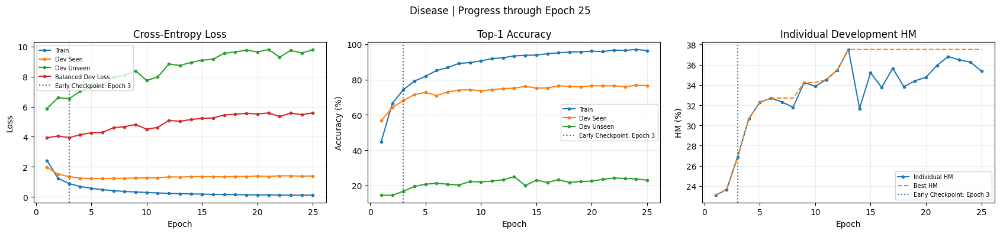

DISEASE Epoch 26/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 26/30 | Train: 96.83% (0.1050) | Seen: 76.12% (1.4344) | Unseen: 24.25% (9.9186) | HM: 36.78% | Balanced Loss: 5.6765 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 27/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 27/30 | Train: 96.89% (0.0994) | Seen: 75.68% (1.4117) | Unseen: 23.75% (9.6282) | HM: 36.15% | Balanced Loss: 5.5199 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 28/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 28/30 | Train: 96.90% (0.1011) | Seen: 76.12% (1.4044) | Unseen: 23.25% (9.8848) | HM: 35.62% | Balanced Loss: 5.6446 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 29/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 29/30 | Train: 97.22% (0.0951) | Seen: 76.69% (1.3877) | Unseen: 23.00% (9.6400) | HM: 35.39% | Balanced Loss: 5.5139 | Best HM: E13 | Best Loss: E3


DISEASE Epoch 30/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE | Epoch 30/30 | Train: 96.90% (0.1032) | Seen: 75.83% (1.4081) | Unseen: 22.50% (9.7464) | HM: 34.70% | Balanced Loss: 5.5773 | Best HM: E13 | Best Loss: E3


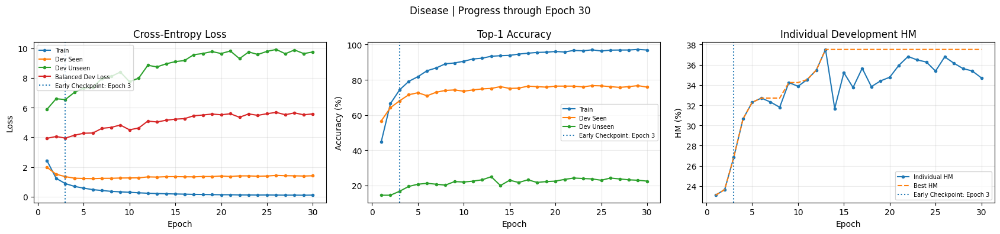

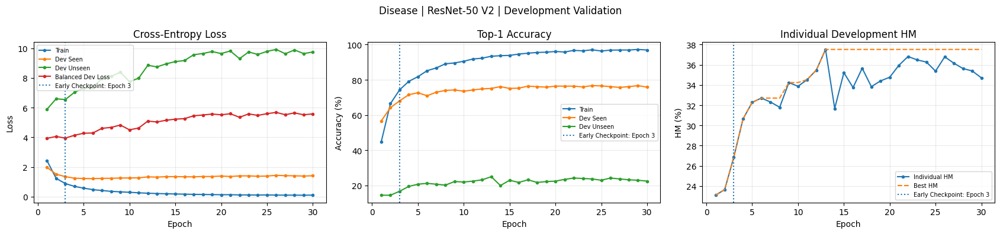

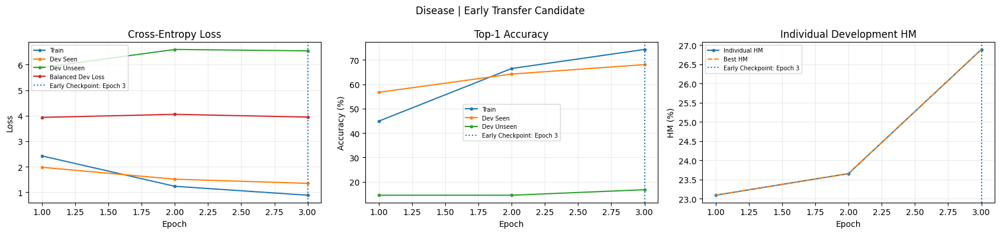


Completed DISEASE | Best HM: Epoch 13 | Best Loss: Epoch 3


In [ ]:
run_training('disease', target_epoch=MAX_EPOCHS)

## 15 — Inspect baseline and early-transfer checkpoint policies

Confirm `best.pt` / `best_hm.pt` refer to the best **Individual Development HM**, while `early_transfer.pt` / `best_val_loss.pt` refer to the lowest **balanced Development Validation Loss** after warm-up. Plot both before choosing the team handover checkpoint. A low validation loss alone cannot certify that a model has not overfit.

In [15]:

for task in ('crop', 'disease'):
    folder = RESULTS_ROOT / task
    history_path = folder / 'history.csv'

    if not history_path.exists():
        print(f'{task.upper()}: Not yet trained.')
        continue

    # Training history
    history = pd.read_csv(history_path)

    print(f'\n{task.upper()} Training Results')

    columns = [
        'epoch',
        'train_loss', 'seen_loss', 'unseen_loss',
        'balanced_val_loss',
        'train_acc', 'seen_acc', 'unseen_acc',
        'individual_h'
    ]

    display(history[columns].tail(10).round(4))

    # Checkpoint selection
    selection_path = folder / 'checkpoint_selection.csv'

    if selection_path.exists():
        display(pd.read_csv(selection_path))

    # Verify saved outputs
    files = [
        'best.pt',
        'best_hm.pt',
        'best_val_loss.pt',
        'early_transfer.pt',
        'full_training_curves.png',
        'before_overfitting_candidate_curves.png'
    ]

    print('\nSaved Outputs:')

    for filename in files:
        path = folder / filename

        if path.exists():
            size_mb = path.stat().st_size / (1024 ** 2)
            print(f'{filename}: Saved ({size_mb:.1f} MB)')
        else:
            print(f'{filename}: Missing')



CROP Training Results


,epoch,train_loss,seen_loss,unseen_loss,balanced_val_loss,train_acc,seen_acc,unseen_acc,individual_h
20,21,0.0293,0.5996,3.4245,2.0120,0.9925,0.8978,0.7300,0.8053
21,22,0.0230,0.6007,3.5508,2.0757,0.9936,0.8935,0.7125,0.7928
22,23,0.0226,0.5946,3.4499,2.0222,0.9945,0.8878,0.7200,0.7951
23,24,0.0244,0.5733,3.4223,1.9978,0.9923,0.9007,0.7125,0.7956
24,25,0.0234,0.5996,3.5476,2.0736,0.9936,0.8978,0.7175,0.7976
25,26,0.0224,0.6050,3.5401,2.0725,0.9941,0.8964,0.7025,0.7877
26,27,0.0213,0.5960,3.4950,2.0455,0.9948,0.9022,0.7200,0.8009
27,28,0.0231,0.5875,3.4229,2.0052,0.9935,0.8935,0.7000,0.7850
28,29,0.0187,0.5967,3.4664,2.0315,0.9952,0.8950,0.7150,0.7949
29,30,0.0192,0.5927,3.4926,2.0426,0.9948,0.9007,0.7175,0.7987


,task,best_hm_epoch,best_hm,best_balanced_loss_epoch,best_balanced_val_loss,completed_epoch
0,crop,21,0.805268,3,1.525188,30



Saved Outputs:
best.pt: Saved (90.4 MB)
best_hm.pt: Saved (90.4 MB)
best_val_loss.pt: Saved (90.4 MB)
early_transfer.pt: Saved (90.4 MB)
full_training_curves.png: Saved (0.2 MB)
before_overfitting_candidate_curves.png: Saved (0.1 MB)

DISEASE Training Results


,epoch,train_loss,seen_loss,unseen_loss,balanced_val_loss,train_acc,seen_acc,unseen_acc,individual_h
20,21,0.1292,1.3567,9.8144,5.5856,0.9577,0.7640,0.2350,0.3594
21,22,0.1157,1.3982,9.2973,5.3478,0.9667,0.7640,0.2425,0.3682
22,23,0.1139,1.3995,9.7504,5.5750,0.9644,0.7597,0.2400,0.3648
23,24,0.1076,1.3720,9.5791,5.4755,0.9700,0.7669,0.2375,0.3627
24,25,0.1133,1.3893,9.7890,5.5892,0.9634,0.7655,0.2300,0.3537
25,26,0.1050,1.4344,9.9186,5.6765,0.9683,0.7612,0.2425,0.3678
26,27,0.0994,1.4117,9.6282,5.5199,0.9689,0.7568,0.2375,0.3615
27,28,0.1011,1.4044,9.8848,5.6446,0.9690,0.7612,0.2325,0.3562
28,29,0.0951,1.3877,9.6400,5.5139,0.9722,0.7669,0.2300,0.3539
29,30,0.1032,1.4081,9.7464,5.5773,0.9690,0.7583,0.2250,0.3470


,task,best_hm_epoch,best_hm,best_balanced_loss_epoch,best_balanced_val_loss,completed_epoch
0,disease,13,0.375135,3,3.944133,30



Saved Outputs:
best.pt: Saved (91.3 MB)
best_hm.pt: Saved (91.3 MB)
best_val_loss.pt: Saved (91.3 MB)
early_transfer.pt: Saved (91.3 MB)
full_training_curves.png: Saved (0.2 MB)
before_overfitting_candidate_curves.png: Saved (0.1 MB)


## 16 — Development composition evaluation (both checkpoint policies)
Log-probabilities are combined across all **55 × 175 = 9,625 candidate pairs**, without using Official Test. This compares which policy is best as a *Baseline*; it does not assert that the loss-selected candidate is always better for transfer.

In [16]:
# 16. DEVELOPMENT VALIDATION — MODEL ACCURACY & COMPOSITION
def development_validation_composition(
    crop_policy='best_hm',
    disease_policy='best_hm'
):
    results = {}

    crop_path = RESULTS_ROOT / 'crop' / f'{crop_policy}_validation.npz'
    disease_path = RESULTS_ROOT / 'disease' / f'{disease_policy}_validation.npz'

    assert crop_path.exists(), f'Missing Crop predictions: {crop_path}'
    assert disease_path.exists(), f'Missing Disease predictions: {disease_path}'

    with np.load(crop_path) as crop_data, np.load(disease_path) as disease_data:

        for split, table in [
            ('seen', val_seen_df),
            ('unseen', val_unseen_df)
        ]:
            crop_log_probs = crop_data[split]
            disease_log_probs = disease_data[split]

            assert crop_log_probs.shape == (len(table), 55)
            assert disease_log_probs.shape == (len(table), 175)

            # Combine independent Crop and Disease predictions
            scores = (
                crop_log_probs[:, :, None]
                + disease_log_probs[:, None, :]
            ).reshape(len(table), 9625)

            top5_indices = np.argsort(-scores, axis=1)[:, :5]

            predictions = table.copy().reset_index(drop=True)

            # Individual model predictions
            predictions['pred_crop'] = np.asarray(crop_ids)[
                top5_indices[:, 0] // 175
            ]

            predictions['pred_disease'] = np.asarray(disease_ids)[
                top5_indices[:, 0] % 175
            ]

            # Individual model accuracy
            predictions['crop_correct'] = (
                predictions['pred_crop'] == predictions['crop_id']
            )

            predictions['disease_correct'] = (
                predictions['pred_disease'] == predictions['disease_id']
            )

            # Composition Top-1 accuracy
            predictions['composition_correct'] = (
                predictions['crop_correct']
                & predictions['disease_correct']
            )

            # Composition Top-5 accuracy
            true_pairs = list(zip(
                predictions['crop_id'].astype(int),
                predictions['disease_id'].astype(int)
            ))

            top5_pairs = [
                [
                    (
                        int(crop_ids[index // 175]),
                        int(disease_ids[index % 175])
                    )
                    for index in indices
                ]
                for indices in top5_indices
            ]

            predictions['composition_top5_correct'] = [
                true_pair in predicted_pairs
                for true_pair, predicted_pairs in zip(
                    true_pairs, top5_pairs
                )
            ]

            results[split] = predictions

    return results


# Compare Development Validation checkpoint combinations
checkpoint_pairs = [
    ('best_hm', 'best_hm'),
    ('best_val_loss', 'best_val_loss'),
    ('best_hm', 'best_val_loss'),
    ('best_val_loss', 'best_hm')
]

comparison = []

for crop_policy, disease_policy in checkpoint_pairs:

    predictions = development_validation_composition(
        crop_policy,
        disease_policy
    )

    seen = predictions['seen']
    unseen = predictions['unseen']

    # Crop CNN accuracy
    crop_seen = seen['crop_correct'].mean()
    crop_unseen = unseen['crop_correct'].mean()

    # Disease CNN accuracy
    disease_seen = seen['disease_correct'].mean()
    disease_unseen = unseen['disease_correct'].mean()

    # Combined composition accuracy
    comp_seen = seen['composition_correct'].mean()
    comp_unseen = unseen['composition_correct'].mean()

    comparison.append({
        'Crop Checkpoint': crop_policy,
        'Disease Checkpoint': disease_policy,

        # Crop CNN
        'Crop Seen (%)': crop_seen * 100,
        'Crop Unseen (%)': crop_unseen * 100,
        'Crop HM (%)': harmonic(crop_seen, crop_unseen) * 100,

        # Disease CNN
        'Disease Seen (%)': disease_seen * 100,
        'Disease Unseen (%)': disease_unseen * 100,
        'Disease HM (%)': harmonic(disease_seen, disease_unseen) * 100,

        # Combined composition
        'Composition Seen Top-1 (%)': comp_seen * 100,
        'Composition Unseen Top-1 (%)': comp_unseen * 100,
        'Composition HM (%)': harmonic(comp_seen, comp_unseen) * 100,

        # Composition Top-5
        'Composition Seen Top-5 (%)': (
            seen['composition_top5_correct'].mean() * 100
        ),
        'Composition Unseen Top-5 (%)': (
            unseen['composition_top5_correct'].mean() * 100
        )
    })


# ------------------------------------------------------------
# Display and save Development Validation results
# ------------------------------------------------------------

development_validation_summary = (
    pd.DataFrame(comparison)
    .sort_values('Composition HM (%)', ascending=False)
    .reset_index(drop=True)
)

print('=' * 65)
print('STAGE 1 — DEVELOPMENT VALIDATION RESULTS')
print('=' * 65)

print('Development Seen:   695 images')
print('Development Unseen: 400 images')
print('Official Test: NOT USED')

print('\nCROP, DISEASE & COMPOSITION ACCURACY')
display(development_validation_summary.round(2))

output_path = (
    RESULTS_ROOT / 'development_validation_model_comparison.csv'
)

development_validation_summary.to_csv(
    output_path,
    index=False
)

print('\nResults saved:', output_path)


STAGE 1 — DEVELOPMENT VALIDATION RESULTS
Development Seen:   695 images
Development Unseen: 400 images
Official Test: NOT USED

CROP, DISEASE & COMPOSITION ACCURACY


,Crop Checkpoint,Disease Checkpoint,Crop Seen (%),Crop Unseen (%),Crop HM (%),Disease Seen (%),Disease Unseen (%),Disease HM (%),Composition Seen Top-1 (%),Composition Unseen Top-1 (%),Composition HM (%),Composition Seen Top-5 (%),Composition Unseen Top-5 (%)
0,best_hm,best_hm,89.78,72.75,80.37,75.11,25.00,37.51,72.52,3.75,7.13,86.91,13.50
1,best_val_loss,best_hm,85.47,64.75,73.68,74.96,25.00,37.50,70.22,2.50,4.83,84.03,10.00
2,best_hm,best_val_loss,89.78,72.75,80.37,67.91,16.75,26.87,66.19,1.25,2.45,83.02,8.25
3,best_val_loss,best_val_loss,85.47,64.75,73.68,67.91,16.75,26.87,64.60,0.50,0.99,81.73,5.75



Results saved: /content/drive/MyDrive/AML_B1_ResNet50/development_validation_model_comparison.csv


## 17 — Development confusion matrices: Crop / Disease / Composition
Produces full count matrices and PNG images on the **Development Seen and Development Unseen** splits, plus readable top-class view. The 9,625-pair catalogue is used for composition scoring, while the matrix uses only observed true/predicted pairs.

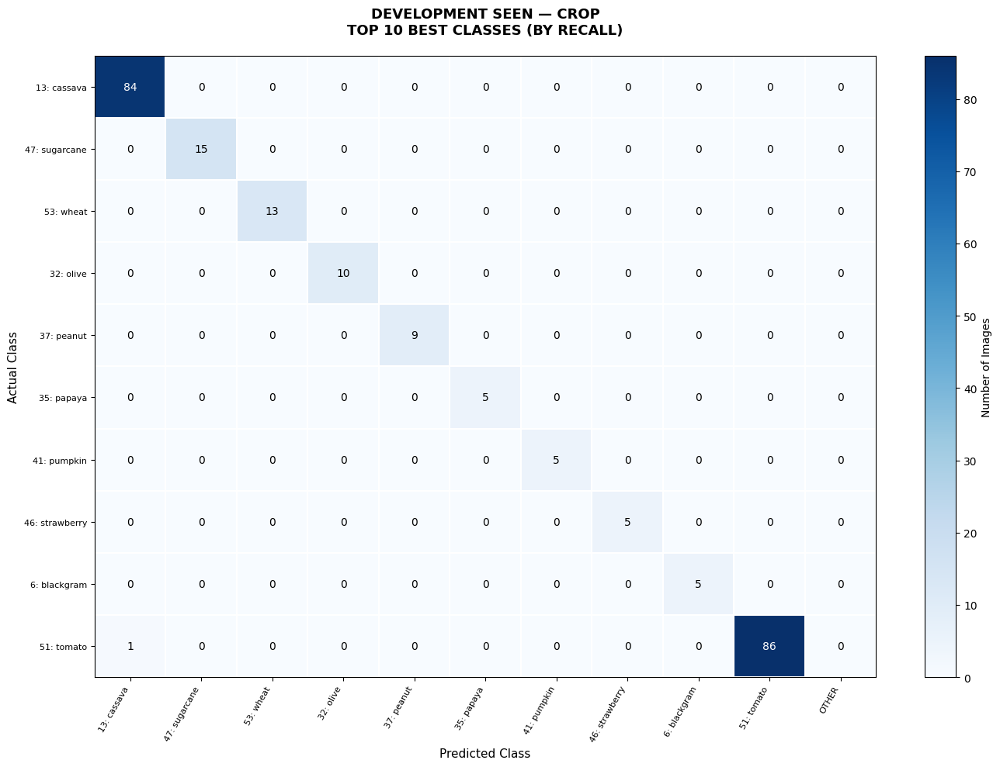


SEEN | CROP | BEST


,class_name,support,TP,FN,recall
actual_key,,,,,
13,13: cassava,84,84,0,1.000
47,47: sugarcane,15,15,0,1.000
53,53: wheat,13,13,0,1.000
32,32: olive,10,10,0,1.000
37,37: peanut,9,9,0,1.000
35,35: papaya,5,5,0,1.000
41,41: pumpkin,5,5,0,1.000
46,46: strawberry,5,5,0,1.000
6,6: blackgram,5,5,0,1.000


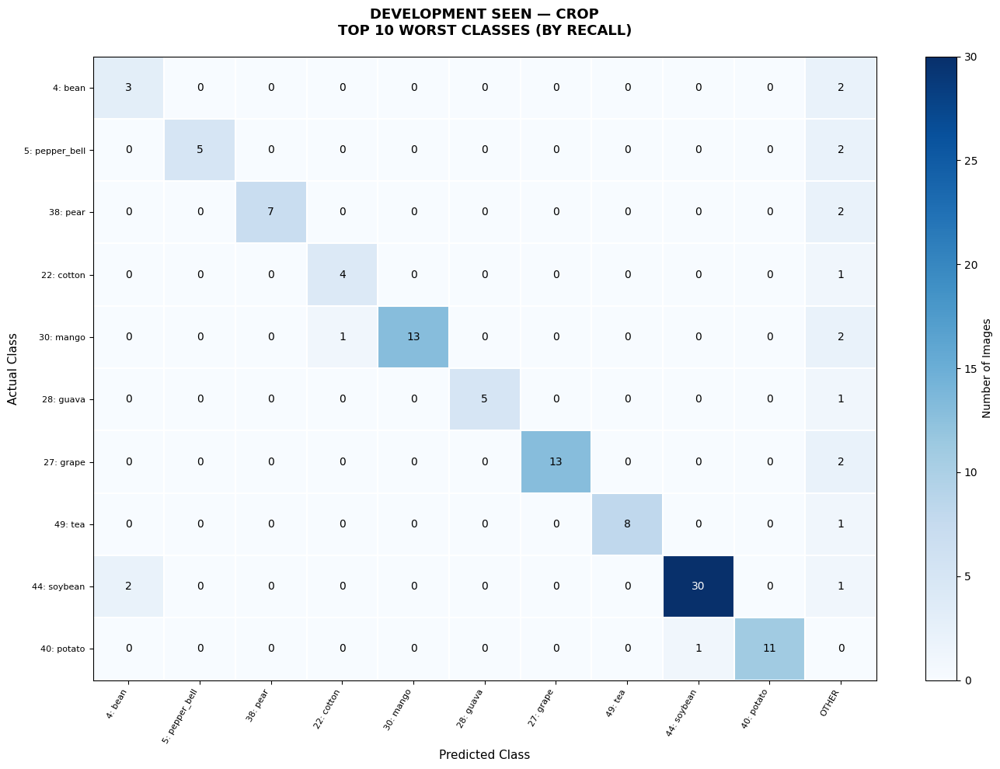


SEEN | CROP | WORST


,class_name,support,TP,FN,recall
actual_key,,,,,
4,4: bean,5,3,2,0.600
5,5: pepper_bell,7,5,2,0.714
38,38: pear,9,7,2,0.778
22,22: cotton,5,4,1,0.800
30,30: mango,16,13,3,0.812
28,28: guava,6,5,1,0.833
27,27: grape,15,13,2,0.867
49,49: tea,9,8,1,0.889
44,44: soybean,33,30,3,0.909


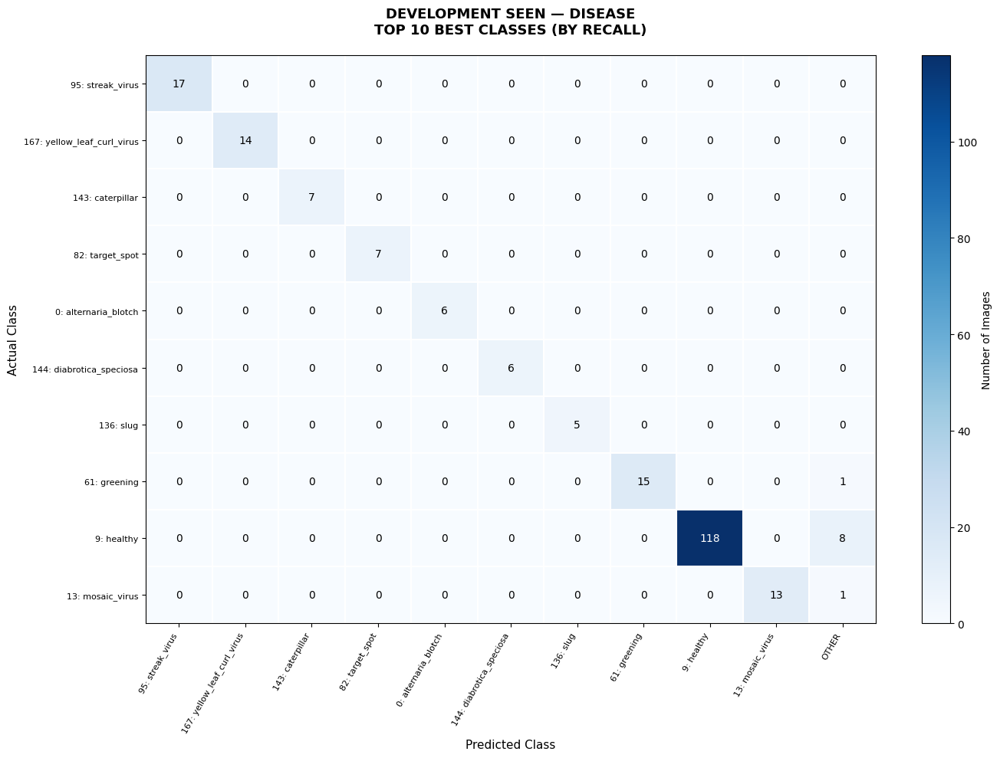


SEEN | DISEASE | BEST


,class_name,support,TP,FN,recall
actual_key,,,,,
95,95: streak_virus,17,17,0,1.000
167,167: yellow_leaf_curl_virus,14,14,0,1.000
143,143: caterpillar,7,7,0,1.000
82,82: target_spot,7,7,0,1.000
0,0: alternaria_blotch,6,6,0,1.000
144,144: diabrotica_speciosa,6,6,0,1.000
136,136: slug,5,5,0,1.000
61,61: greening,16,15,1,0.938
9,9: healthy,126,118,8,0.937


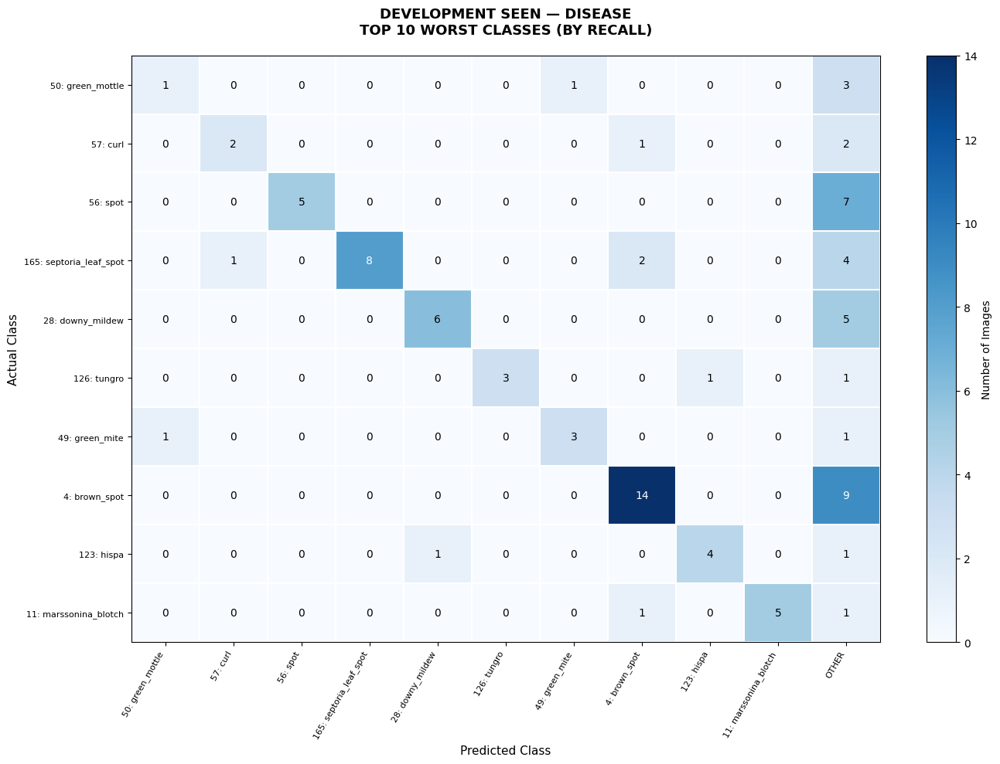


SEEN | DISEASE | WORST


,class_name,support,TP,FN,recall
actual_key,,,,,
50,50: green_mottle,5,1,4,0.200
57,57: curl,5,2,3,0.400
56,56: spot,12,5,7,0.417
165,165: septoria_leaf_spot,15,8,7,0.533
28,28: downy_mildew,11,6,5,0.545
126,126: tungro,5,3,2,0.600
49,49: green_mite,5,3,2,0.600
4,4: brown_spot,23,14,9,0.609
123,123: hispa,6,4,2,0.667


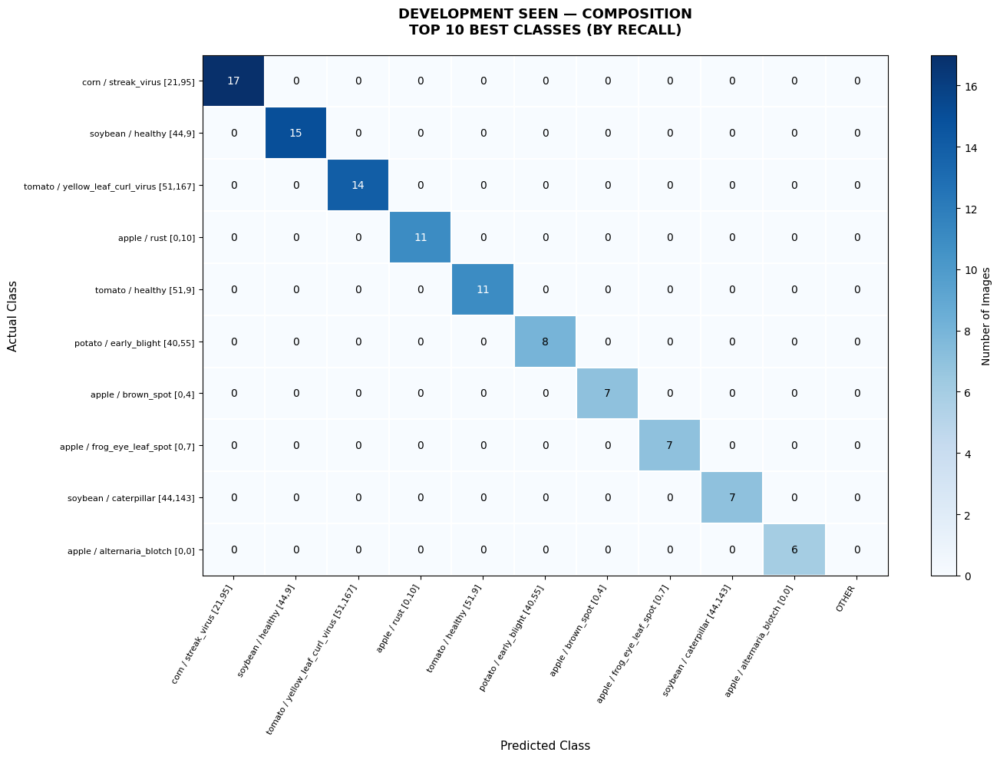


SEEN | COMPOSITION | BEST


,class_name,support,TP,FN,recall
actual_key,,,,,
21|95,"corn / streak_virus [21,95]",17,17,0,1.0
44|9,"soybean / healthy [44,9]",15,15,0,1.0
51|167,"tomato / yellow_leaf_curl_virus [51,167]",14,14,0,1.0
0|10,"apple / rust [0,10]",11,11,0,1.0
51|9,"tomato / healthy [51,9]",11,11,0,1.0
40|55,"potato / early_blight [40,55]",8,8,0,1.0
0|4,"apple / brown_spot [0,4]",7,7,0,1.0
0|7,"apple / frog_eye_leaf_spot [0,7]",7,7,0,1.0
44|143,"soybean / caterpillar [44,143]",7,7,0,1.0


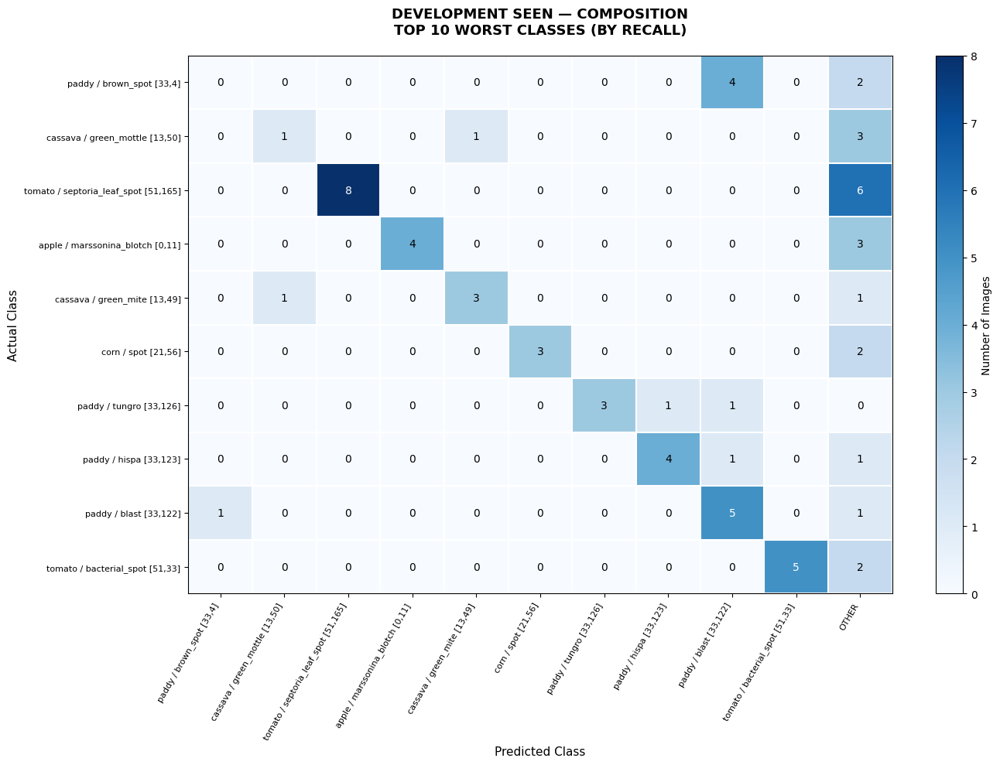


SEEN | COMPOSITION | WORST


,class_name,support,TP,FN,recall
actual_key,,,,,
33|4,"paddy / brown_spot [33,4]",6,0,6,0.000
13|50,"cassava / green_mottle [13,50]",5,1,4,0.200
51|165,"tomato / septoria_leaf_spot [51,165]",14,8,6,0.571
0|11,"apple / marssonina_blotch [0,11]",7,4,3,0.571
13|49,"cassava / green_mite [13,49]",5,3,2,0.600
21|56,"corn / spot [21,56]",5,3,2,0.600
33|126,"paddy / tungro [33,126]",5,3,2,0.600
33|123,"paddy / hispa [33,123]",6,4,2,0.667
33|122,"paddy / blast [33,122]",7,5,2,0.714


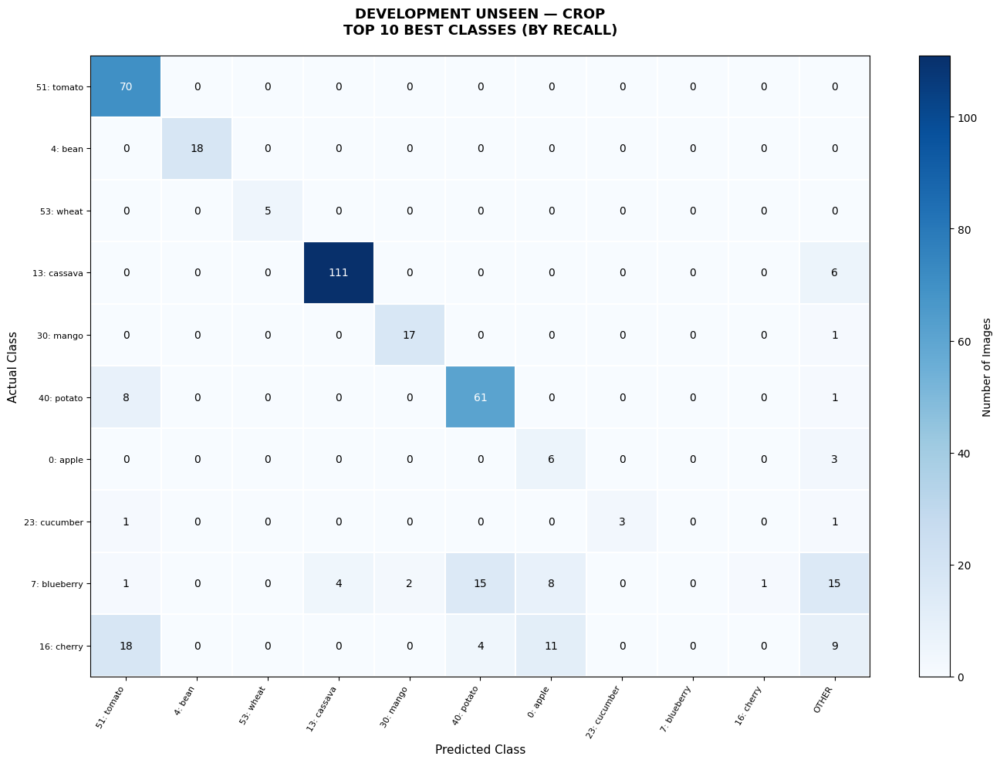


UNSEEN | CROP | BEST


,class_name,support,TP,FN,recall
actual_key,,,,,
51,51: tomato,70,70,0,1.000
4,4: bean,18,18,0,1.000
53,53: wheat,5,5,0,1.000
13,13: cassava,117,111,6,0.949
30,30: mango,18,17,1,0.944
40,40: potato,70,61,9,0.871
0,0: apple,9,6,3,0.667
23,23: cucumber,5,3,2,0.600
7,7: blueberry,46,0,46,0.000


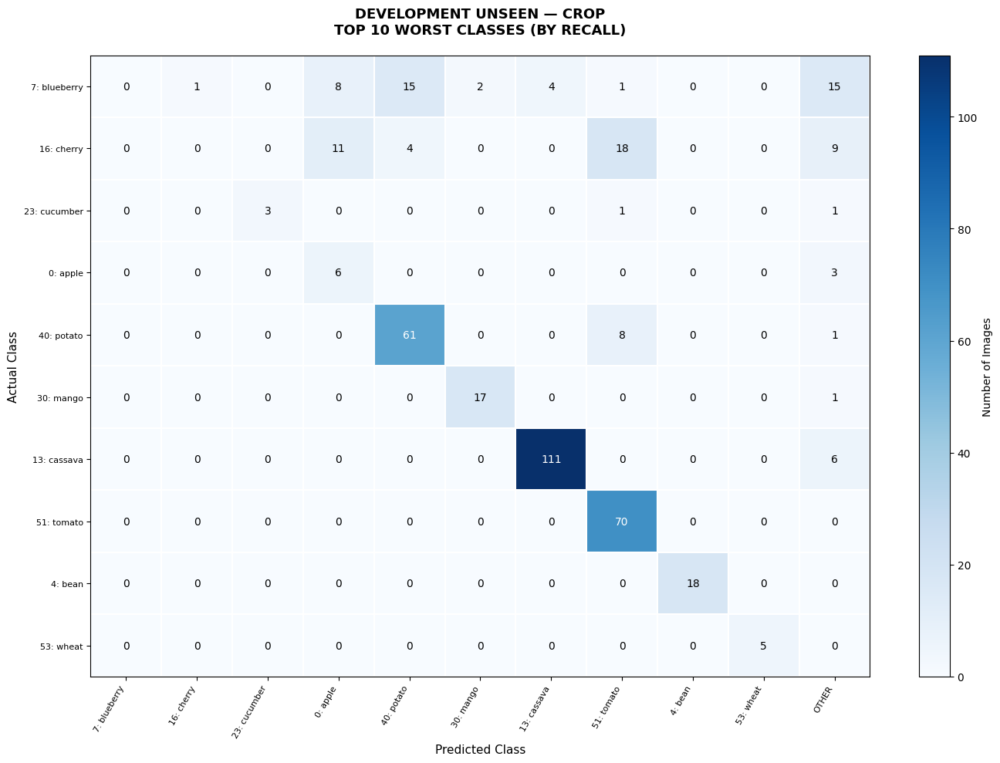


UNSEEN | CROP | WORST


,class_name,support,TP,FN,recall
actual_key,,,,,
7,7: blueberry,46,0,46,0.000
16,16: cherry,42,0,42,0.000
23,23: cucumber,5,3,2,0.600
0,0: apple,9,6,3,0.667
40,40: potato,70,61,9,0.871
30,30: mango,18,17,1,0.944
13,13: cassava,117,111,6,0.949
51,51: tomato,70,70,0,1.000
4,4: bean,18,18,0,1.000


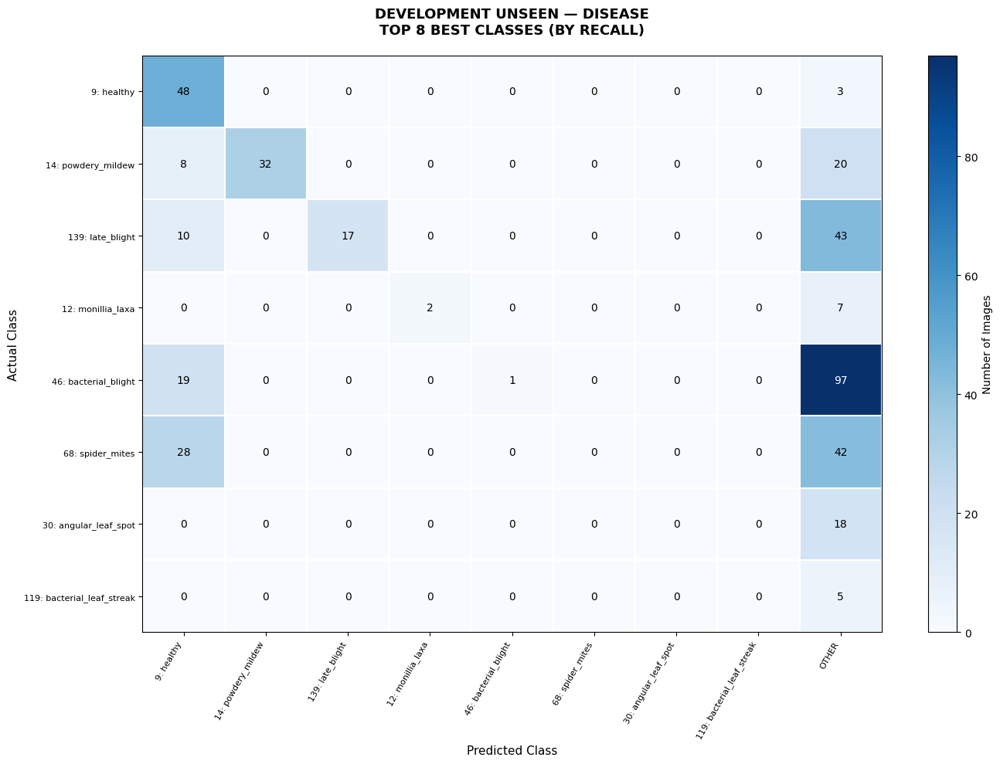


UNSEEN | DISEASE | BEST


,class_name,support,TP,FN,recall
actual_key,,,,,
9,9: healthy,51,48,3,0.941
14,14: powdery_mildew,60,32,28,0.533
139,139: late_blight,70,17,53,0.243
12,12: monillia_laxa,9,2,7,0.222
46,46: bacterial_blight,117,1,116,0.009
68,68: spider_mites,70,0,70,0.000
30,30: angular_leaf_spot,18,0,18,0.000
119,119: bacterial_leaf_streak,5,0,5,0.000


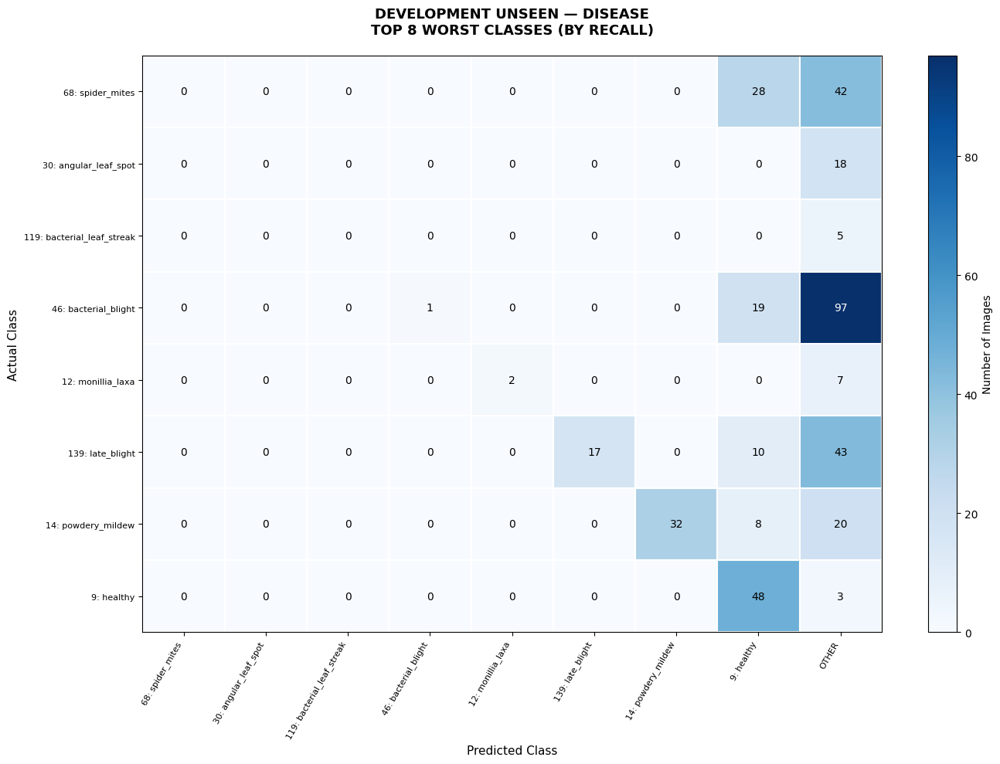


UNSEEN | DISEASE | WORST


,class_name,support,TP,FN,recall
actual_key,,,,,
68,68: spider_mites,70,0,70,0.000
30,30: angular_leaf_spot,18,0,18,0.000
119,119: bacterial_leaf_streak,5,0,5,0.000
46,46: bacterial_blight,117,1,116,0.009
12,12: monillia_laxa,9,2,7,0.222
139,139: late_blight,70,17,53,0.243
14,14: powdery_mildew,60,32,28,0.533
9,9: healthy,51,48,3,0.941


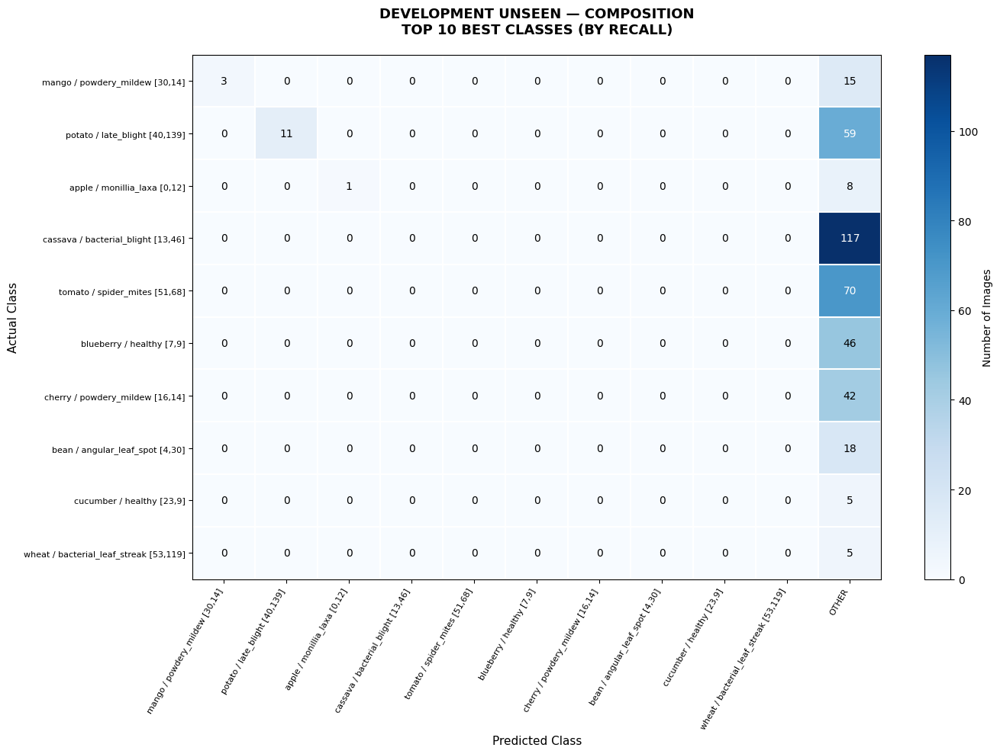


UNSEEN | COMPOSITION | BEST


,class_name,support,TP,FN,recall
actual_key,,,,,
30|14,"mango / powdery_mildew [30,14]",18,3,15,0.167
40|139,"potato / late_blight [40,139]",70,11,59,0.157
0|12,"apple / monillia_laxa [0,12]",9,1,8,0.111
13|46,"cassava / bacterial_blight [13,46]",117,0,117,0.000
51|68,"tomato / spider_mites [51,68]",70,0,70,0.000
7|9,"blueberry / healthy [7,9]",46,0,46,0.000
16|14,"cherry / powdery_mildew [16,14]",42,0,42,0.000
4|30,"bean / angular_leaf_spot [4,30]",18,0,18,0.000
23|9,"cucumber / healthy [23,9]",5,0,5,0.000


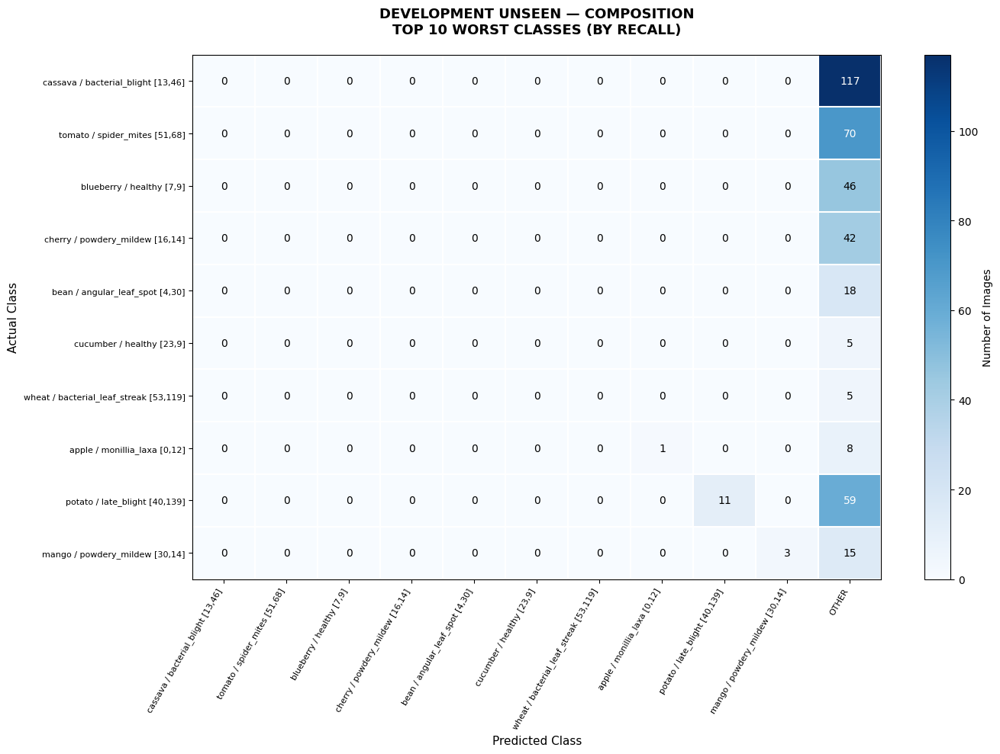


UNSEEN | COMPOSITION | WORST


,class_name,support,TP,FN,recall
actual_key,,,,,
13|46,"cassava / bacterial_blight [13,46]",117,0,117,0.000
51|68,"tomato / spider_mites [51,68]",70,0,70,0.000
7|9,"blueberry / healthy [7,9]",46,0,46,0.000
16|14,"cherry / powdery_mildew [16,14]",42,0,42,0.000
4|30,"bean / angular_leaf_spot [4,30]",18,0,18,0.000
23|9,"cucumber / healthy [23,9]",5,0,5,0.000
53|119,"wheat / bacterial_leaf_streak [53,119]",5,0,5,0.000
0|12,"apple / monillia_laxa [0,12]",9,1,8,0.111
40|139,"potato / late_blight [40,139]",70,11,59,0.157



ALL STAGE 1 DEVELOPMENT CONFUSION MATRICES SAVED
Folder: /content/drive/MyDrive/AML_B1_ResNet50/development_validation/confusion_matrices/best_worst


In [17]:

# ============================================================
# STAGE 1 DEVELOPMENT VALIDATION
# TOP 10 BEST / WORST CONFUSION MATRICES
# Original Best-HM Crop + Disease Checkpoints
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import confusion_matrix
from IPython.display import display

TOP_N = 10
MIN_SUPPORT = 5

CM_ROOT = (
    RESULTS_ROOT
    / "development_validation"
    / "confusion_matrices"
    / "best_worst"
)
CM_ROOT.mkdir(parents=True, exist_ok=True)

# Reuse the saved Stage 1 development predictions.
# No training or checkpoint modification.
predictions = development_validation_composition(
    "best_hm", "best_hm"
)

# Class-name lookup from the original validation tables
name_tables = pd.concat(
    [val_seen_df, val_unseen_df],
    ignore_index=True
)

crop_names = (
    name_tables[["crop_id", "crop_name"]]
    .drop_duplicates("crop_id")
    .set_index("crop_id")["crop_name"]
    .to_dict()
)

disease_names = (
    name_tables[["disease_id", "disease_name"]]
    .drop_duplicates("disease_id")
    .set_index("disease_id")["disease_name"]
    .to_dict()
)


def prepare_data(df, task):

    data = df.copy()

    if task == "crop":
        data["actual_key"] = data["crop_id"].astype(int).astype(str)
        data["pred_key"] = data["pred_crop"].astype(int).astype(str)

    elif task == "disease":
        data["actual_key"] = data["disease_id"].astype(int).astype(str)
        data["pred_key"] = data["pred_disease"].astype(int).astype(str)

    elif task == "composition":
        data["actual_key"] = (
            data["crop_id"].astype(int).astype(str)
            + "|"
            + data["disease_id"].astype(int).astype(str)
        )

        data["pred_key"] = (
            data["pred_crop"].astype(int).astype(str)
            + "|"
            + data["pred_disease"].astype(int).astype(str)
        )

    else:
        raise ValueError(task)

    return data


def class_label(key, task):

    if task == "crop":
        c = int(key)
        return f"{c}: {crop_names.get(c, c)}"

    if task == "disease":
        d = int(key)
        return f"{d}: {disease_names.get(d, d)}"

    c, d = map(int, key.split("|"))

    return (
        f"{crop_names.get(c, c)} / "
        f"{disease_names.get(d, d)} [{c},{d}]"
    )


def plot_best_worst(df, split, task, ranking):

    data = prepare_data(df, task)

    # ------------------------------------------
    # Calculate per-class recall
    # ------------------------------------------

    support = data["actual_key"].value_counts()

    correct = data[
        data["actual_key"] == data["pred_key"]
    ]["actual_key"].value_counts()

    report = pd.DataFrame({
        "support": support
    })

    report["TP"] = correct.reindex(
        report.index, fill_value=0
    )

    report["FN"] = report["support"] - report["TP"]

    report["recall"] = (
        report["TP"] / report["support"]
    )

    report["class_name"] = [
        class_label(k, task)
        for k in report.index
    ]

    report.to_csv(
        CM_ROOT / f"{split}_{task}_per_class_recall.csv",
        index_label="class_key"
    )

    eligible = report[
        report["support"] >= MIN_SUPPORT
    ].copy()

    if eligible.empty:
        print(f"Skipped {split} {task}: insufficient support")
        return

    # ------------------------------------------
    # Select best or worst classes
    # ------------------------------------------

    if ranking == "best":

        selected_report = eligible.sort_values(
            ["recall", "support", "class_name"],
            ascending=[False, False, True]
        ).head(TOP_N)

    else:

        selected_report = eligible.sort_values(
            ["recall", "support", "class_name"],
            ascending=[True, False, True]
        ).head(TOP_N)

    selected = selected_report.index.tolist()

    subset = data[
        data["actual_key"].isin(selected)
    ]

    # ------------------------------------------
    # Confusion Matrix with OTHER column
    # ------------------------------------------

    matrix = pd.crosstab(
        subset["actual_key"],
        subset["pred_key"]
    )

    compact = matrix.reindex(
        index=selected,
        columns=selected,
        fill_value=0
    )

    # Predictions outside selected Top 10 classes
    other = (
        subset.groupby("actual_key").size()
        .reindex(selected, fill_value=0)
        - compact.sum(axis=1)
    )

    compact["OTHER"] = other

    assert compact.to_numpy().sum() == len(subset)

    x_labels = [
        class_label(k, task)
        for k in selected
    ] + ["OTHER"]

    y_labels = [
        class_label(k, task)
        for k in selected
    ]

    compact.index = y_labels
    compact.columns = x_labels

    compact.to_csv(
        CM_ROOT /
        f"{split}_{task}_{ranking}_top10_matrix.csv"
    )

    selected_report.to_csv(
        CM_ROOT /
        f"{split}_{task}_{ranking}_top10_ranking.csv",
        index_label="class_key"
    )

    # ------------------------------------------
    # Plot blue confusion matrix with counts
    # ------------------------------------------

    values = compact.to_numpy()

    fig, ax = plt.subplots(figsize=(14, 10))

    image = ax.imshow(
        values,
        cmap="Blues",
        interpolation="nearest",
        aspect="auto",
        vmin=0
    )

    fig.colorbar(
        image, ax=ax,
        label="Number of Images"
    )

    ax.set_xticks(np.arange(len(x_labels)))
    ax.set_yticks(np.arange(len(y_labels)))

    ax.set_xticklabels(
        x_labels,
        rotation=60,
        ha="right",
        fontsize=8
    )

    ax.set_yticklabels(
        y_labels,
        fontsize=8
    )

    # White grid lines
    ax.set_xticks(
        np.arange(-0.5, len(x_labels), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(y_labels), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linewidth=1.5
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    # Display numerical counts
    maximum = values.max()

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):

            count = int(values[i, j])

            color = (
                "white"
                if maximum > 0 and count > maximum / 2
                else "black"
            )

            ax.text(
                j, i, str(count),
                ha="center",
                va="center",
                fontsize=10,
                color=color
            )

    ax.set_title(
        f"DEVELOPMENT {split.upper()} — {task.upper()}\n"
        f"TOP {len(selected)} {ranking.upper()} "
        f"CLASSES (BY RECALL)",
        fontsize=13,
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel("Predicted Class", fontsize=11)
    ax.set_ylabel("Actual Class", fontsize=11)

    fig.tight_layout()

    output = (
        CM_ROOT /
        f"{split}_{task}_{ranking}_top10.png"
    )

    fig.savefig(
        output,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"\n{split.upper()} | {task.upper()} | {ranking.upper()}")

    display(
        selected_report[
            ["class_name", "support", "TP", "FN", "recall"]
        ].round(3)
    )


# ============================================================
# GENERATE ALL CONFUSION MATRICES
# ============================================================

for split in ["seen", "unseen"]:

    df = predictions[split].copy()

    for task in ["crop", "disease", "composition"]:

        for ranking in ["best", "worst"]:

            plot_best_worst(
                df, split, task, ranking
            )

print("\nALL STAGE 1 DEVELOPMENT CONFUSION MATRICES SAVED")
print("Folder:", CM_ROOT)


## 18 — Development misclassification tables and sample image gallery
Displays genuine examples, their true Crop/Disease IDs and predicted IDs. Outputs remain visible and are saved to Drive. Uses only the Development Seen and Unseen validation sets.


DEVELOPMENT SEEN VALIDATION
Composition Errors: 191/695


,filename,crop_id,pred_crop,disease_id,pred_disease,crop_correct,disease_correct
0,CDDM_apple_cedar_apple_rust_11791.jpg,0,0,5,0,True,False
5,PWV2_squash_powdery_mildew_7935.jpg,45,51,14,14,False,True
13,PDN_pear_erwinia_amylovora_2389.jpg,38,36,135,12,False,False
16,CPDD_tomato_septoria_leaf_spot_3312.jpg,51,51,165,166,True,False
29,CPDD_cassava_mosaic_6522.jpg,13,13,51,13,True,False
35,CUPD_cassava_green_mottle_7153.jpg,13,13,50,51,True,False
36,PWV2_cherry_leaf_spot_2594.jpg,16,19,56,10,False,False
39,PD_paddy_downy_mildew_5796.jpg,33,33,28,122,True,False
43,CDDM_wheat_leaf_rust_132613.jpg,53,53,10,9,True,False
44,SCLD_sugarcane_brown_spot_1094.jpg,47,47,4,122,True,False


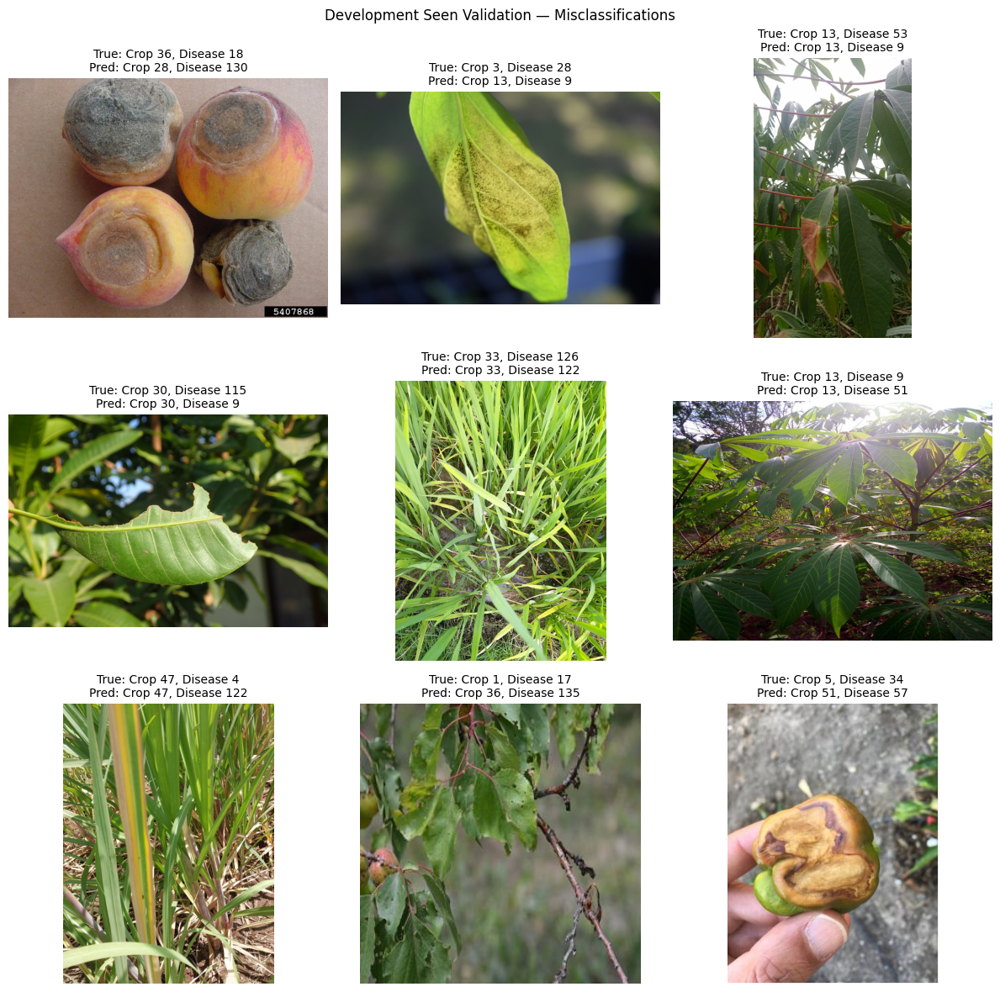


DEVELOPMENT UNSEEN VALIDATION
Composition Errors: 385/400


,filename,crop_id,pred_crop,disease_id,pred_disease,crop_correct,disease_correct
0,CDDM_blueberry_healthy_43279.jpg,7,36,9,9,False,True
1,CPDD_cassava_bacterial_blight_leaf_43.jpg,13,13,46,4,True,False
2,CDDM_potato_late_blight_63912.jpg,40,40,139,55,True,False
4,CPDD_cassava_bacterial_blight_leaf_1191.jpg,13,13,46,4,True,False
5,CPDD_cassava_bacterial_blight_leaf_932.jpg,13,36,46,4,False,False
6,CDC_cassava_bacterial_blight_343.jpg,13,13,46,48,True,False
7,CPDD_cassava_bacterial_blight_leaf_1801.jpg,13,13,46,4,True,False
8,CPDD_cassava_bacterial_blight_leaf_425.jpg,13,13,46,4,True,False
9,PDL2_potato_late_blight_2584.jpg,40,51,139,72,False,False
10,CDDM_cherry_powdery_mildew_45643.jpg,16,40,14,14,False,True


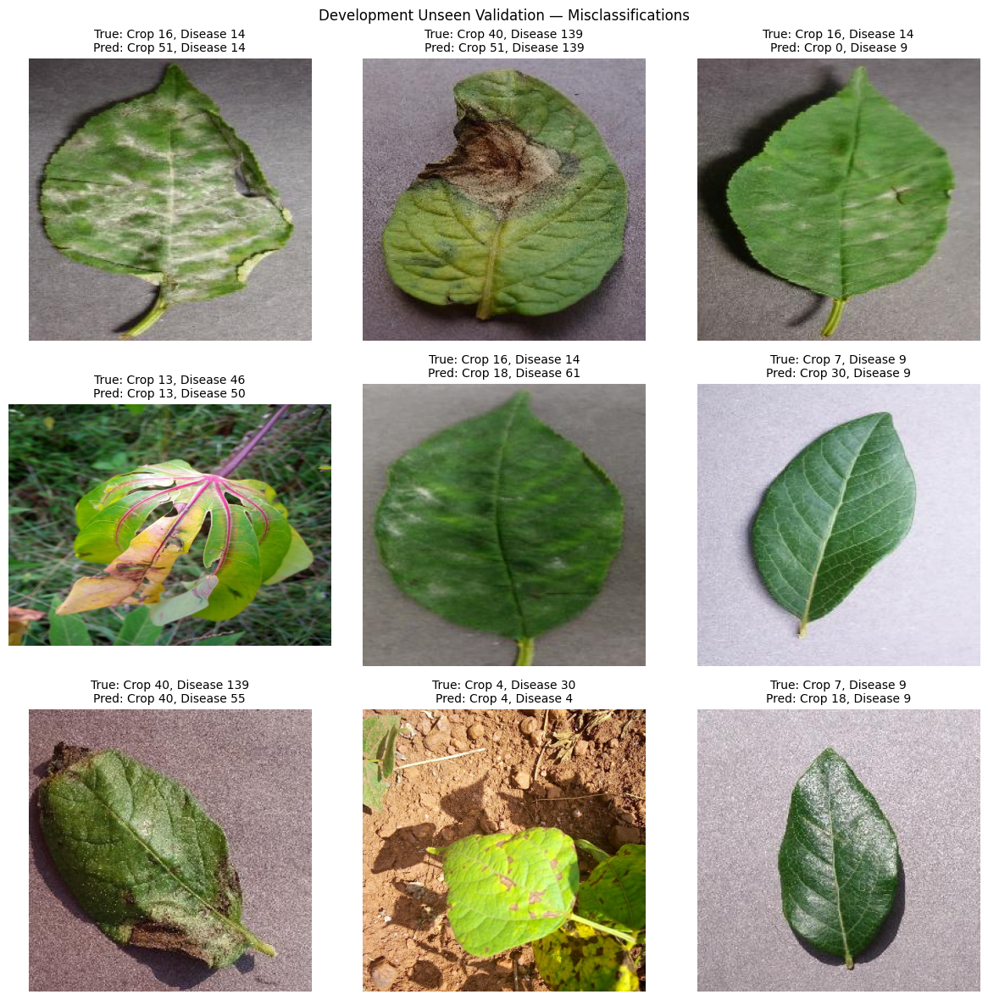


Misclassification analysis saved: /content/drive/MyDrive/AML_B1_ResNet50/development_validation/misclassifications


In [18]:
from PIL import Image as PILImage

# Load development validation predictions
predictions = development_validation_composition('best_hm', 'best_hm')

output_dir = RESULTS_ROOT / 'development_validation' / 'misclassifications'
output_dir.mkdir(parents=True, exist_ok=True)

for split, df in predictions.items():
    # Select incorrect composition predictions
    mistakes = df.loc[~df['composition_correct']].copy()

    # Save all misclassification records
    mistakes.to_csv(
        output_dir / f'dev_{split}_misclassifications.csv',
        index=False
    )

    print(f'\nDEVELOPMENT {split.upper()} VALIDATION')
    print(f'Composition Errors: {len(mistakes)}/{len(df)}')

    display(
        mistakes[
            [
                'filename',
                'crop_id', 'pred_crop',
                'disease_id', 'pred_disease',
                'crop_correct', 'disease_correct'
            ]
        ].head(10)
    )

    # Randomly select 9 misclassified images
    sample = mistakes.sample(
        n=min(9, len(mistakes)),
        random_state=SEED
    )

    if sample.empty:
        continue

    # Display misclassified images
    columns = 3
    rows = int(np.ceil(len(sample) / columns))

    fig, axes = plt.subplots(
        rows, columns,
        figsize=(12, 4 * rows)
    )

    axes = np.atleast_1d(axes).ravel()

    for ax, (_, row) in zip(axes, sample.iterrows()):
        with PILImage.open(image_lookup[str(row.filename)]) as image:
            ax.imshow(image.convert('RGB'))

        ax.set_title(
            f'True: Crop {row.crop_id}, Disease {row.disease_id}\n'
            f'Pred: Crop {row.pred_crop}, Disease {row.pred_disease}',
            fontsize=10
        )
        ax.axis('off')

    for ax in axes[len(sample):]:
        ax.axis('off')

    fig.suptitle(
        f'Development {split.title()} Validation — Misclassifications'
    )

    fig.tight_layout()

    fig.savefig(
        output_dir / f'dev_{split}_misclassification_gallery.png',
        dpi=160,
        bbox_inches='tight'
    )

    display(fig)
    plt.close(fig)

print('\nMisclassification analysis saved:', output_dir)


In [19]:
# Development Validation — Composition Generalisation Analysis

predictions = development_validation_composition('best_hm', 'best_hm')

output_dir = RESULTS_ROOT / 'development_validation' / 'composition_analysis'
output_dir.mkdir(parents=True, exist_ok=True)

# Compositions appearing in development training
train_pairs = set(zip(
    train_df['crop_id'].astype(int),
    train_df['disease_id'].astype(int)
))

train_counts = (
    train_df.groupby(['crop_id', 'disease_id'])
    .size()
    .rename('train_images')
)

all_results = []

for split, df in predictions.items():
    data = df.copy()

    true_pairs = list(zip(
        data['crop_id'].astype(int),
        data['disease_id'].astype(int)
    ))

    predicted_pairs = list(zip(
        data['pred_crop'].astype(int),
        data['pred_disease'].astype(int)
    ))

    data['true_composition'] = [f'{c}_{d}' for c, d in true_pairs]
    data['predicted_composition'] = [
        f'{c}_{d}' for c, d in predicted_pairs
    ]

    data['predicted_seen_pair'] = [
        pair in train_pairs for pair in predicted_pairs
    ]

    data['error_type'] = np.select(
        [
            data['crop_correct'] & data['disease_correct'],
            data['crop_correct'] & ~data['disease_correct'],
            ~data['crop_correct'] & data['disease_correct']
        ],
        [
            'Both Correct',
            'Disease Wrong',
            'Crop Wrong'
        ],
        default='Both Wrong'
    )

    # Per-composition accuracy
    composition_results = (
        data.groupby(['crop_id', 'disease_id'])
        .agg(
            validation_images=('composition_correct', 'size'),
            correct=('composition_correct', 'sum'),
            accuracy=('composition_correct', 'mean'),
            predicted_seen_rate=('predicted_seen_pair', 'mean')
        )
        .reset_index()
    )

    composition_results['train_images'] = [
        train_counts.get((c, d), 0)
        for c, d in zip(
            composition_results['crop_id'],
            composition_results['disease_id']
        )
    ]

    composition_results['accuracy'] *= 100
    composition_results['predicted_seen_rate'] *= 100

    composition_results = composition_results.sort_values(
        ['accuracy', 'validation_images'],
        ascending=[True, False]
    )

    # Save detailed predictions and per-composition results
    data.to_csv(
        output_dir / f'dev_{split}_prediction_analysis.csv',
        index=False
    )

    composition_results.to_csv(
        output_dir / f'dev_{split}_composition_accuracy.csv',
        index=False
    )

    print(f'\nDEVELOPMENT {split.upper()} VALIDATION')
    print(f'Images: {len(data)}')
    print(f'Composition Accuracy: {data.composition_correct.mean():.2%}')
    print(f'Predicted Seen-Pair Rate: {data.predicted_seen_pair.mean():.2%}')

    print('\nError Types:')
    display(
        data['error_type']
        .value_counts()
        .rename_axis('Error Type')
        .reset_index(name='Images')
    )

    print('\nLowest-Accuracy Compositions:')
    display(composition_results.head(15).round(2))

    all_results.append(data)

print('\nDevelopment composition analysis saved:', output_dir)



DEVELOPMENT SEEN VALIDATION
Images: 695
Composition Accuracy: 72.52%
Predicted Seen-Pair Rate: 91.22%

Error Types:


,Error Type,Images
0,Both Correct,504
1,Disease Wrong,120
2,Both Wrong,53
3,Crop Wrong,18



Lowest-Accuracy Compositions:


,crop_id,disease_id,validation_images,correct,accuracy,predicted_seen_rate,train_images
149,33,4,6,0,0.0,100.0,65
1,0,1,2,0,0.0,50.0,19
165,33,128,2,0,0.0,100.0,19
216,47,4,2,0,0.0,0.0,21
219,47,58,2,0,0.0,100.0,19
2,0,2,1,0,0.0,100.0,3
5,0,5,1,0,0.0,100.0,7
6,0,6,1,0,0.0,0.0,16
16,1,12,1,0,0.0,100.0,1
17,1,17,1,0,0.0,0.0,1



DEVELOPMENT UNSEEN VALIDATION
Images: 400
Composition Accuracy: 3.75%
Predicted Seen-Pair Rate: 83.25%

Error Types:


,Error Type,Images
0,Disease Wrong,276
1,Crop Wrong,85
2,Both Wrong,24
3,Both Correct,15



Lowest-Accuracy Compositions:


,crop_id,disease_id,validation_images,correct,accuracy,predicted_seen_rate,train_images
3,13,46,117,0,0.00,83.76,0
8,51,68,70,0,0.00,100.00,0
2,7,9,46,0,0.00,100.00,0
4,16,14,42,0,0.00,73.81,0
1,4,30,18,0,0.00,66.67,0
5,23,9,5,0,0.00,60.00,0
9,53,119,5,0,0.00,80.00,0
0,0,12,9,1,11.11,66.67,0
7,40,139,70,11,15.71,74.29,0
6,30,14,18,3,16.67,61.11,0



Development composition analysis saved: /content/drive/MyDrive/AML_B1_ResNet50/development_validation/composition_analysis


## 19 — Model handover manifest

Share `best.pt` (Baseline; used by Stage 2) and `early_transfer.pt` (earlier loss-selected transfer candidate) as **separate files**, with their recorded source epochs, configuration, class mapping and preprocessing code. Verify the loss curve and the complete `epoch_01.pt`–`epoch_30.pt` archive before asserting a checkpoint is before pronounced overfitting. ResNet-50 weights require a compatible ResNet-50 architecture; different proposed architectures cannot automatically load them.

**Review before handover:** The earliest onset of overfitting cannot be certified by one scalar minimum. After training, use all epoch checkpoints and full losses to choose the epoch you and your teammate agree on. `early_transfer.pt` is an automatic *candidate*; if another epoch is better, load its `epoch_XX.pt` archive and export a separately named full-precision checkpoint without retraining.


In [20]:
manifest=[]
for task in ('crop','disease'):
    folder=RESULTS_ROOT/task
    for filename in ['best.pt','best_hm.pt','best_val_loss.pt','early_transfer.pt'] + [f'epoch_{e:02d}.pt' for e in range(1,MAX_EPOCHS+1)]:
        path=folder/filename
        if not path.exists():continue
        checkpoint=torch.load(path,map_location='cpu',weights_only=False)
        manifest.append({'task':task,'checkpoint':filename,
                         'epoch':checkpoint['epoch'],
                         'selection_metric':checkpoint['selection_metric'],
                         'selection_value':checkpoint['selection_value'],
                         'size_mb':round(path.stat().st_size/1024**2,1),
                         'path':str(path)})
manifest_df=pd.DataFrame(manifest)
display(manifest_df)
manifest_df.to_csv(RESULTS_ROOT/'transfer_checkpoint_manifest.csv',index=False)
print('Share model architecture, transforms and class_mapping.json with checkpoint files.')

,task,checkpoint,epoch,selection_metric,selection_value,size_mb,path
0,crop,best.pt,21,individual_development_hm,0.805268,90.4,/content/drive/MyDrive/AML_B1_ResNet50/crop/be...
1,crop,best_hm.pt,21,individual_development_hm,0.805268,90.4,/content/drive/MyDrive/AML_B1_ResNet50/crop/be...
2,crop,best_val_loss.pt,3,balanced_development_cross_entropy,1.525188,90.4,/content/drive/MyDrive/AML_B1_ResNet50/crop/be...
3,crop,early_transfer.pt,3,balanced_development_cross_entropy,1.525188,90.4,/content/drive/MyDrive/AML_B1_ResNet50/crop/ea...
4,crop,epoch_01.pt,1,epoch_archive_balanced_dev_loss,1.639341,90.4,/content/drive/MyDrive/AML_B1_ResNet50/crop/ep...
...,...,...,...,...,...,...,...
63,disease,epoch_26.pt,26,epoch_archive_balanced_dev_loss,5.676506,91.3,/content/drive/MyDrive/AML_B1_ResNet50/disease...
64,disease,epoch_27.pt,27,epoch_archive_balanced_dev_loss,5.519947,91.3,/content/drive/MyDrive/AML_B1_ResNet50/disease...
65,disease,epoch_28.pt,28,epoch_archive_balanced_dev_loss,5.644568,91.3,/content/drive/MyDrive/AML_B1_ResNet50/disease...
66,disease,epoch_29.pt,29,epoch_archive_balanced_dev_loss,5.513888,91.3,/content/drive/MyDrive/AML_B1_ResNet50/disease...


Share model architecture, transforms and class_mapping.json with checkpoint files.


### Optional — Export a chosen earlier epoch for teammate handover
After inspecting the completed graphs, change `CHOSEN_TRANSFER_EPOCH` independently for Crop and Disease. This does not train a model or overwrite `best.pt` or the automatic `early_transfer.pt`.



RUN B — STAGE 1 CROP


,Task,Lowest Seen Loss Epoch,Lowest Unseen Loss Epoch,Lowest Balanced Loss Epoch,Highest Validation HM Epoch,Highest Validation HM (%),Early Stop Trigger,Early Stop Checkpoint
0,Crop,9,1,3,21,80.53,6,3


,epoch,train_loss,seen_loss,unseen_loss,balanced_val_loss,individual_h
0,1,1.3015,0.9262,2.3525,1.6393,0.6381
1,2,0.5118,0.7198,2.4945,1.6072,0.7158
2,3,0.3349,0.5915,2.4589,1.5252,0.7368
3,4,0.2516,0.5570,2.7155,1.6363,0.7342
4,5,0.1828,0.5117,2.5770,1.5443,0.7784
5,6,0.1520,0.5410,2.9904,1.7657,0.7470
6,7,0.1209,0.5208,2.8486,1.6847,0.7647
7,8,0.1017,0.5279,3.1658,1.8469,0.7733
8,9,0.0808,0.5004,2.9356,1.7180,0.7911
9,10,0.0792,0.5656,3.2060,1.8858,0.7662


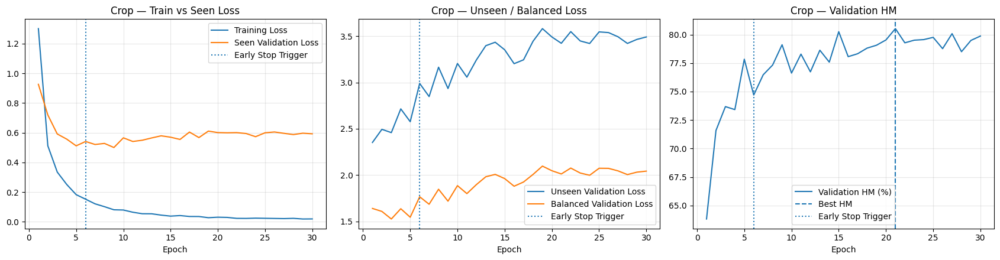

Early checkpoint: /content/drive/MyDrive/AML_B1_ResNet50/crop/epoch_03.pt
Checkpoint exists: True

RUN B — STAGE 1 DISEASE


,Task,Lowest Seen Loss Epoch,Lowest Unseen Loss Epoch,Lowest Balanced Loss Epoch,Highest Validation HM Epoch,Highest Validation HM (%),Early Stop Trigger,Early Stop Checkpoint
0,Disease,6,1,1,13,37.51,4,1


,epoch,train_loss,seen_loss,unseen_loss,balanced_val_loss,individual_h
0,1,2.4233,1.9755,5.8865,3.9310,0.2309
1,2,1.2320,1.5100,6.5955,4.0527,0.2366
2,3,0.8810,1.3479,6.5404,3.9441,0.2688
3,4,0.6900,1.2423,7.0308,4.1365,0.3064
4,5,0.5734,1.2247,7.3190,4.2718,0.3228
5,6,0.4717,1.2128,7.3636,4.2882,0.3270
6,7,0.4136,1.2333,7.9716,4.6025,0.3231
7,8,0.3560,1.2355,8.0970,4.6662,0.3179
8,9,0.3242,1.2540,8.3947,4.8243,0.3424
9,10,0.2916,1.2604,7.7448,4.5026,0.3387


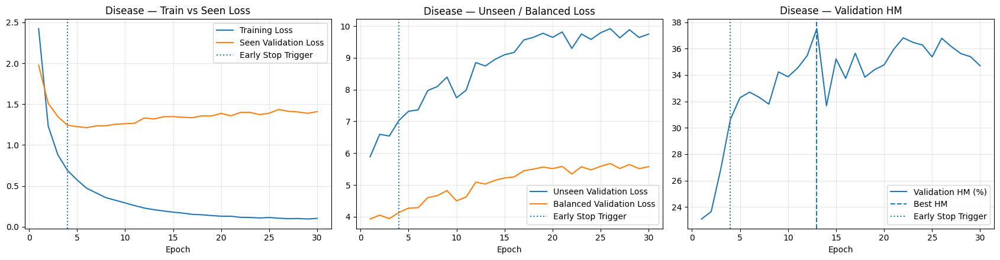

Early checkpoint: /content/drive/MyDrive/AML_B1_ResNet50/disease/epoch_01.pt
Checkpoint exists: True

RUN B — OVERALL SUMMARY


,Task,Lowest Seen Loss Epoch,Lowest Unseen Loss Epoch,Lowest Balanced Loss Epoch,Highest Validation HM Epoch,Highest Validation HM (%),Early Stop Trigger,Early Stop Checkpoint
0,Crop,9,1,3,21,80.53,6,3
1,Disease,6,1,1,13,37.51,4,1


In [24]:

# ============================================================
# RUN B — STAGE 1 OVERFITTING & CHECKPOINT ANALYSIS
# No training, no weight modification
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/AML_B1_ResNet50")

PATIENCE = 3
MIN_DELTA = 0.01

all_summaries = []

for task in ["crop", "disease"]:

    folder = ROOT / task
    history_path = folder / "history.csv"

    assert history_path.exists(), f"Missing: {history_path}"

    df = pd.read_csv(history_path)
    df = df.sort_values("epoch").reset_index(drop=True)

    required = [
        "epoch", "train_loss", "train_acc",
        "seen_loss", "unseen_loss",
        "seen_acc", "unseen_acc", "individual_h"
    ]

    assert all(c in df.columns for c in required), (
        f"{task} columns: {df.columns.tolist()}"
    )

    # Equal weighting for seen and unseen validation loss
    df["balanced_val_loss"] = (
        df["seen_loss"] + df["unseen_loss"]
    ) / 2

    best_seen = df.loc[df["seen_loss"].idxmin()]
    best_unseen = df.loc[df["unseen_loss"].idxmin()]
    best_balanced = df.loc[df["balanced_val_loss"].idxmin()]
    best_hm = df.loc[df["individual_h"].idxmax()]

    # Retrospective patience-based stopping diagnostic
    best_so_far = float("inf")
    best_epoch_so_far = None
    stale = 0
    stop_epoch = None
    checkpoint_epoch = None

    for _, row in df.iterrows():

        loss = float(row["balanced_val_loss"])

        if loss < best_so_far - MIN_DELTA:
            best_so_far = loss
            best_epoch_so_far = int(row["epoch"])
            stale = 0
        else:
            stale += 1

        if stale >= PATIENCE:
            stop_epoch = int(row["epoch"])
            checkpoint_epoch = best_epoch_so_far
            break

    print("\n" + "=" * 65)
    print(f"RUN B — STAGE 1 {task.upper()}")
    print("=" * 65)

    summary = {
        "Task": task.title(),
        "Lowest Seen Loss Epoch": int(best_seen["epoch"]),
        "Lowest Unseen Loss Epoch": int(best_unseen["epoch"]),
        "Lowest Balanced Loss Epoch": int(best_balanced["epoch"]),
        "Highest Validation HM Epoch": int(best_hm["epoch"]),
        "Highest Validation HM (%)": best_hm["individual_h"] * 100,
        "Early Stop Trigger": stop_epoch,
        "Early Stop Checkpoint": checkpoint_epoch
    }

    all_summaries.append(summary)

    display(pd.DataFrame([summary]).round(2))

    # Print first 15 epochs
    display(
        df[[
            "epoch",
            "train_loss",
            "seen_loss",
            "unseen_loss",
            "balanced_val_loss",
            "individual_h"
        ]].head(15).round(4)
    )

    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

    axes[0].plot(
        df["epoch"], df["train_loss"],
        label="Training Loss"
    )
    axes[0].plot(
        df["epoch"], df["seen_loss"],
        label="Seen Validation Loss"
    )

    axes[1].plot(
        df["epoch"], df["unseen_loss"],
        label="Unseen Validation Loss"
    )
    axes[1].plot(
        df["epoch"], df["balanced_val_loss"],
        label="Balanced Validation Loss"
    )

    axes[2].plot(
        df["epoch"], df["individual_h"] * 100,
        label="Validation HM (%)"
    )

    axes[2].axvline(
        int(best_hm["epoch"]),
        linestyle="--",
        label="Best HM"
    )

    if stop_epoch is not None:
        for ax in axes:
            ax.axvline(
                stop_epoch,
                linestyle=":",
                label="Early Stop Trigger"
            )

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()

    axes[0].set_title(f"{task.title()} — Train vs Seen Loss")
    axes[1].set_title(f"{task.title()} — Unseen / Balanced Loss")
    axes[2].set_title(f"{task.title()} — Validation HM")

    plt.tight_layout()
    plt.show()

    # Check saved early checkpoint file
    if checkpoint_epoch is not None:
        ckpt = folder / f"epoch_{checkpoint_epoch:02d}.pt"
        print("Early checkpoint:", ckpt)
        print("Checkpoint exists:", ckpt.exists())

print("\n" + "=" * 65)
print("RUN B — OVERALL SUMMARY")
print("=" * 65)
display(pd.DataFrame(all_summaries).round(2))


In [25]:
# Select early transfer epochs after reviewing validation curves
CHOSEN_TRANSFER_EPOCH = {
    'crop': 3,
    'disease': 6
}

for task, epoch in CHOSEN_TRANSFER_EPOCH.items():
    if epoch is None:
        continue

    epoch = int(epoch)
    assert 1 <= epoch <= MAX_EPOCHS

    folder = RESULTS_ROOT / task
    source = folder / f'epoch_{epoch:02d}.pt'
    destination = folder / f'manual_transfer_epoch_{epoch:02d}.pt'

    assert source.exists(), f'Checkpoint not found: {source}'
    verify_checkpoint(source, task, epoch)

    checkpoint = torch.load(
        source,
        map_location='cpu',
        weights_only=False
    )

    checkpoint['selection_metric'] = 'manual_early_transfer_after_curve_review'
    checkpoint['archive_source'] = str(source)

    save_atomic(checkpoint, destination)
    verify_checkpoint(destination, task, epoch)

    print(f'{task.upper()} | Selected Epoch {epoch}')
    print(f'Saved: {destination}')


CROP | Selected Epoch 3
Saved: /content/drive/MyDrive/AML_B1_ResNet50/crop/manual_transfer_epoch_03.pt
DISEASE | Selected Epoch 6
Saved: /content/drive/MyDrive/AML_B1_ResNet50/disease/manual_transfer_epoch_06.pt


In [26]:
from google.colab import files

for task, epoch in CHOSEN_TRANSFER_EPOCH.items():
    if epoch is None:
        continue

    checkpoint = (
        RESULTS_ROOT / task /
        f'manual_transfer_epoch_{int(epoch):02d}.pt'
    )

    assert checkpoint.exists(), f'Missing checkpoint: {checkpoint}'
    files.download(str(checkpoint))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 20 — Optional Stage 2: Full 8,000-image continuation (DISABLED by default)
**Do not interpret this as a new validation-selected model.** After using all 8,000 training images, the 695 and 400 previously held-out development images are no longer independent. This optional section starts from your chosen **Stage 1 HM checkpoints** (for Baseline continuation) and trains a fixed 10 additional epochs at Backbone LR `1e-6` / Head LR `1e-4`, Weight Decay `1e-3`. It saves separately; Official Test is deliberately not included. Stage 2 does **not** use validation loss for checkpoint selection.

In [27]:
RUN_STAGE2 = True

STAGE2_EPOCHS = 10
STAGE2_BACKBONE_LR = 1e-6
STAGE2_HEAD_LR = 1e-4

STAGE2_ROOT = RESULTS_ROOT / 'stage2_full8000'


def read_original_training(path):
    columns = [
        'filename', 'crop_id', 'disease_id', 'composition_id',
        'crop_name', 'disease_name', 'composition_name'
    ]

    with open(path, encoding='utf-8-sig') as file:
        has_header = file.readline().strip().split(',')[0].lower() == 'filename'

    return pd.read_csv(
        path,
        header=0 if has_header else None,
        names=columns,
        encoding='utf-8-sig'
    )


print('Stage 2 Enabled:', RUN_STAGE2)
print('Stage 2 Epochs:', STAGE2_EPOCHS)
print('Backbone LR:', STAGE2_BACKBONE_LR)
print('Head LR:', STAGE2_HEAD_LR)


Stage 2 Enabled: True
Stage 2 Epochs: 10
Backbone LR: 1e-06
Head LR: 0.0001



STAGE 2 — CROP FULL-DATA FINE-TUNING
Images: 8000
Epochs: 10


STAGE 2 CROP | Epoch 1/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 1/10 | Train Accuracy: 96.85% | Train Loss: 0.2329


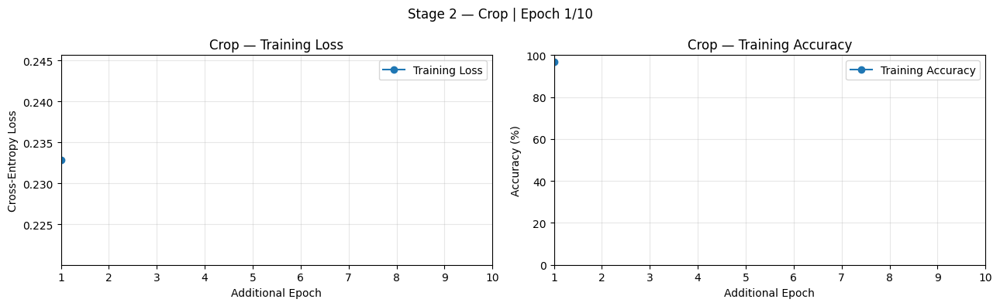

STAGE 2 CROP | Epoch 2/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 2/10 | Train Accuracy: 96.71% | Train Loss: 0.1691


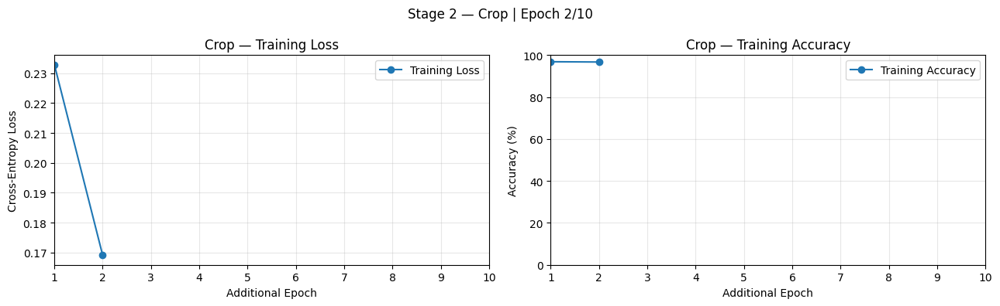

STAGE 2 CROP | Epoch 3/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 3/10 | Train Accuracy: 97.05% | Train Loss: 0.1337


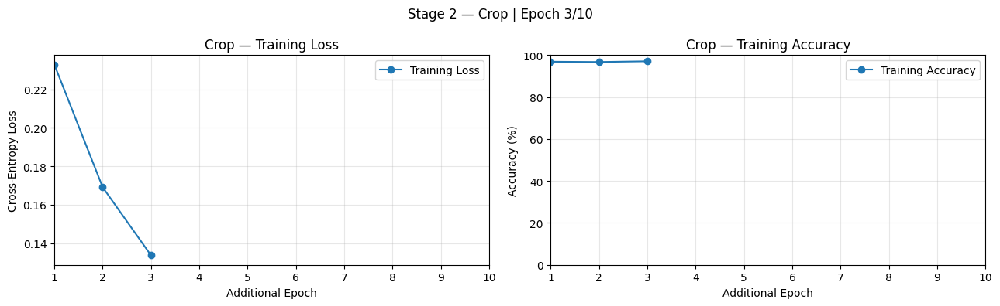

STAGE 2 CROP | Epoch 4/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 4/10 | Train Accuracy: 97.56% | Train Loss: 0.1049


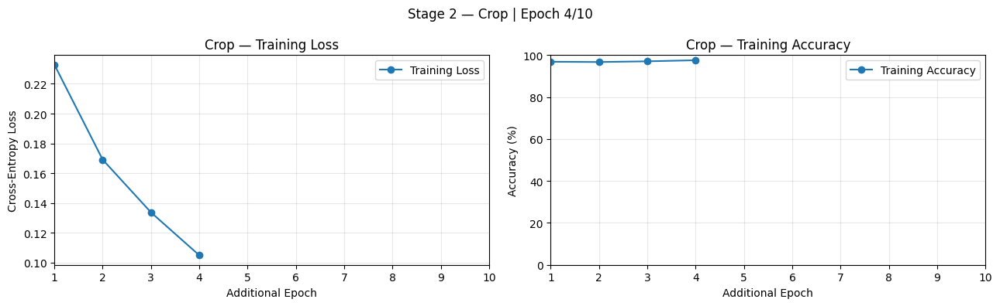

STAGE 2 CROP | Epoch 5/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 5/10 | Train Accuracy: 97.35% | Train Loss: 0.1048


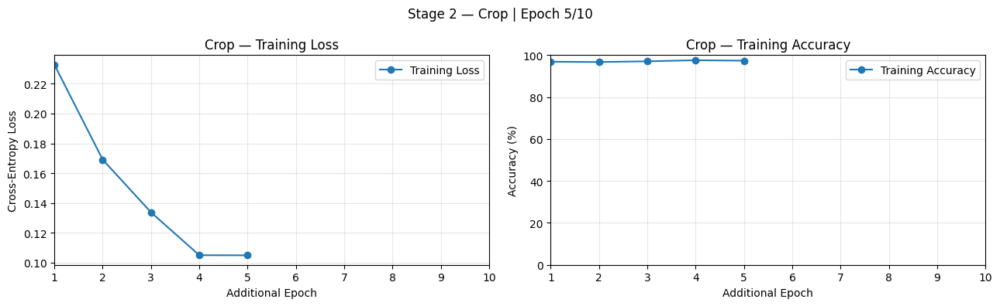

STAGE 2 CROP | Epoch 6/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 6/10 | Train Accuracy: 97.70% | Train Loss: 0.0891


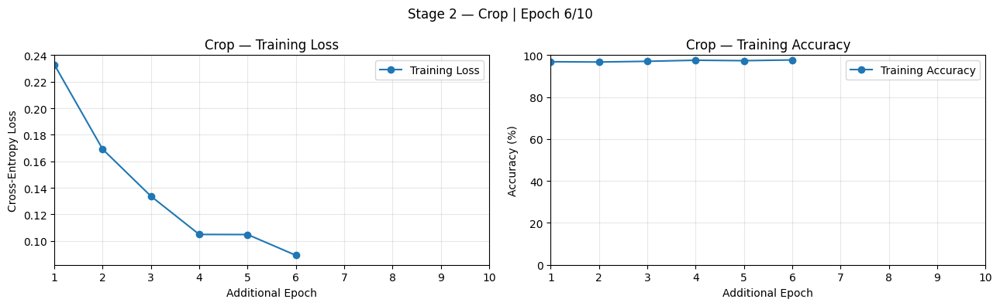

STAGE 2 CROP | Epoch 7/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 7/10 | Train Accuracy: 97.84% | Train Loss: 0.0855


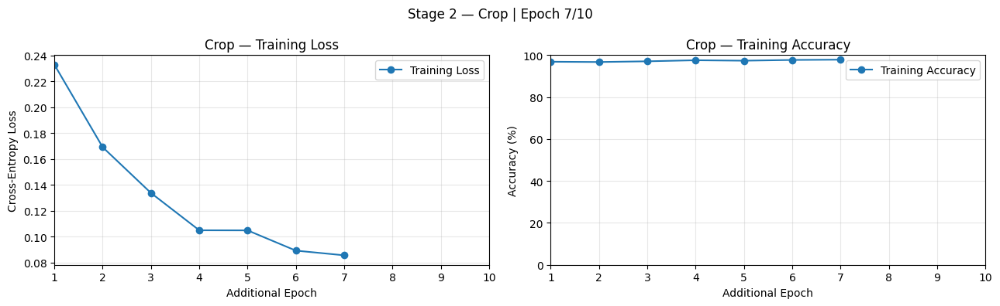

STAGE 2 CROP | Epoch 8/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 8/10 | Train Accuracy: 97.55% | Train Loss: 0.0889


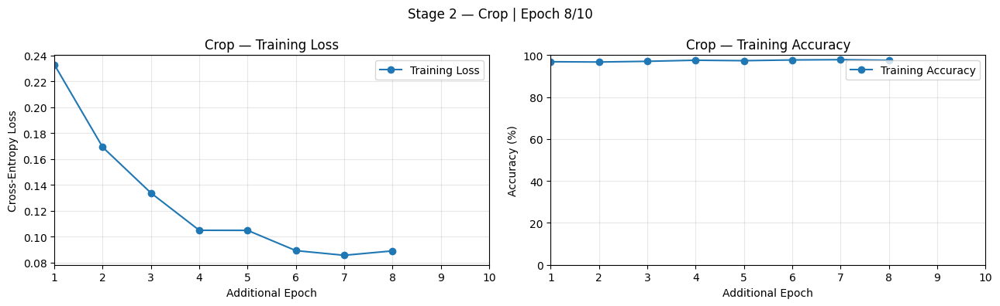

STAGE 2 CROP | Epoch 9/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 9/10 | Train Accuracy: 97.94% | Train Loss: 0.0837


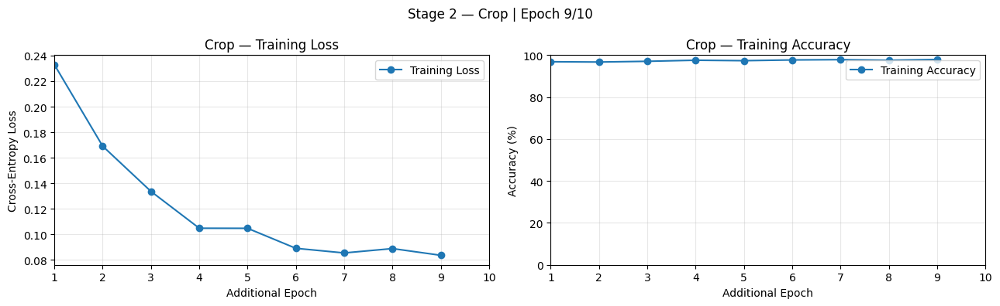

STAGE 2 CROP | Epoch 10/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 CROP | Epoch 10/10 | Train Accuracy: 97.90% | Train Loss: 0.0815


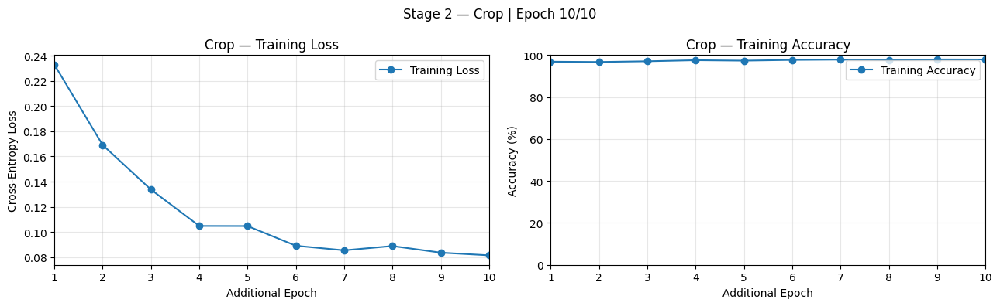


CROP STAGE 2 COMPLETED
Final Checkpoint: /content/drive/MyDrive/AML_B1_ResNet50/stage2_full8000/crop/final_epoch10.pt
Training History: /content/drive/MyDrive/AML_B1_ResNet50/stage2_full8000/crop/history.csv
Training Curves: /content/drive/MyDrive/AML_B1_ResNet50/stage2_full8000/crop/stage2_training_curves.png

STAGE 2 — DISEASE FULL-DATA FINE-TUNING
Images: 8000
Epochs: 10


STAGE 2 DISEASE | Epoch 1/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 1/10 | Train Accuracy: 89.12% | Train Loss: 0.6136


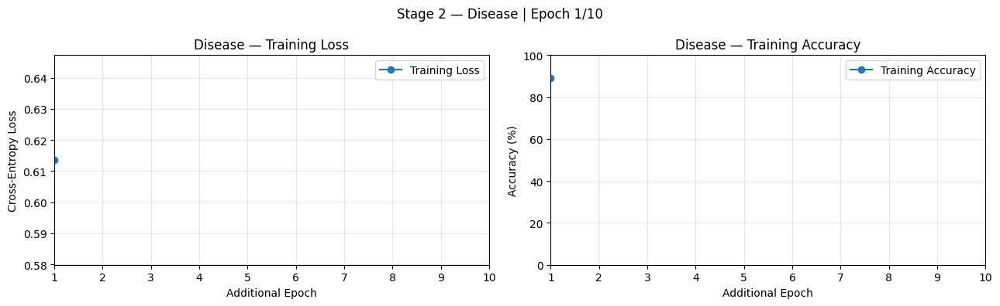

STAGE 2 DISEASE | Epoch 2/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 2/10 | Train Accuracy: 89.18% | Train Loss: 0.4932


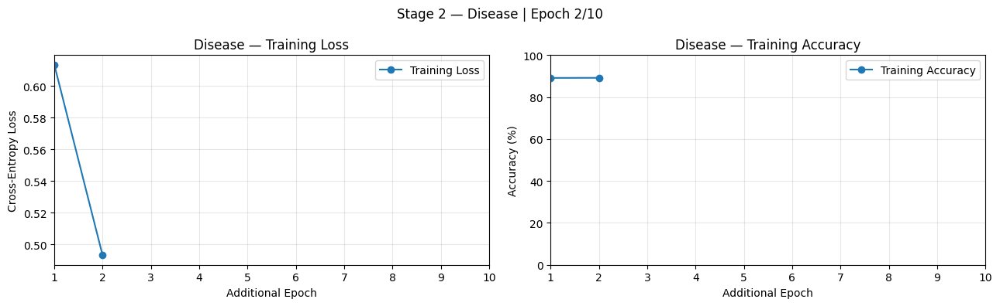

STAGE 2 DISEASE | Epoch 3/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 3/10 | Train Accuracy: 89.60% | Train Loss: 0.4214


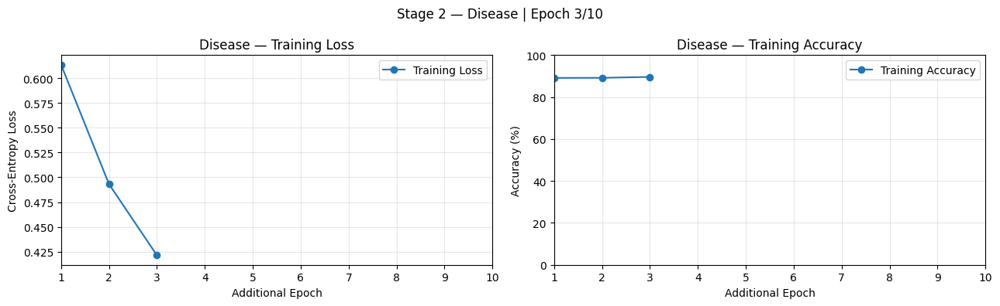

STAGE 2 DISEASE | Epoch 4/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 4/10 | Train Accuracy: 89.90% | Train Loss: 0.3869


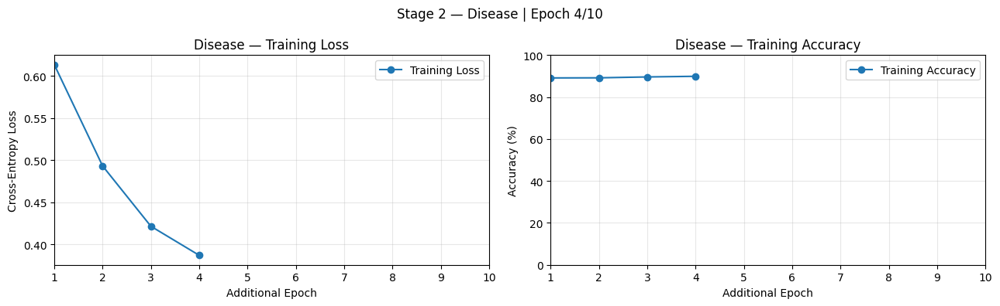

STAGE 2 DISEASE | Epoch 5/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 5/10 | Train Accuracy: 89.76% | Train Loss: 0.3781


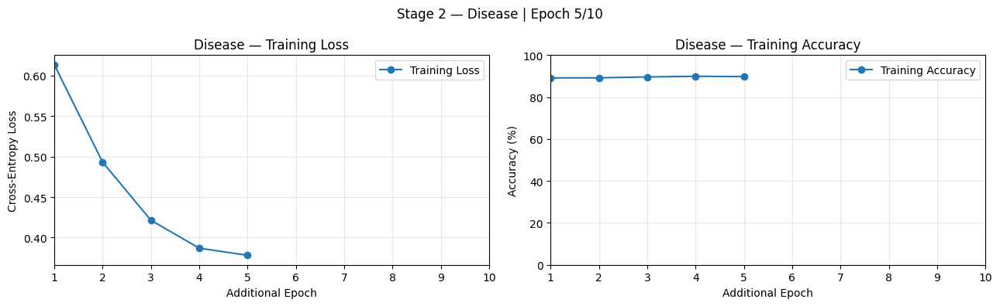

STAGE 2 DISEASE | Epoch 6/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 6/10 | Train Accuracy: 90.51% | Train Loss: 0.3558


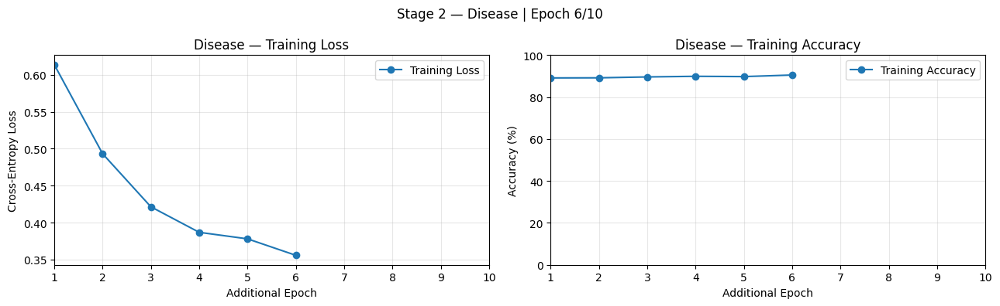

STAGE 2 DISEASE | Epoch 7/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 7/10 | Train Accuracy: 90.34% | Train Loss: 0.3467


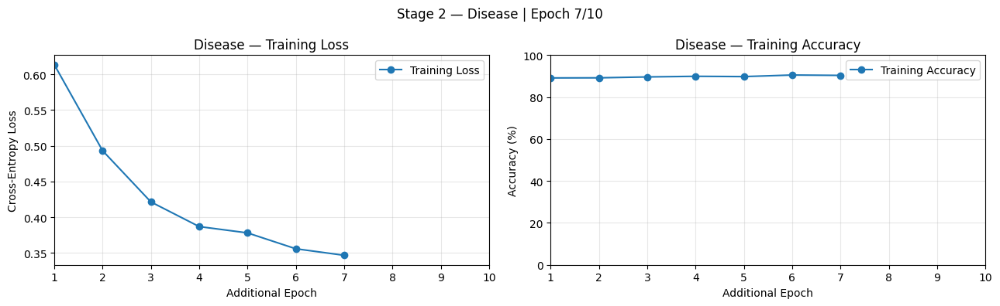

STAGE 2 DISEASE | Epoch 8/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 8/10 | Train Accuracy: 90.79% | Train Loss: 0.3350


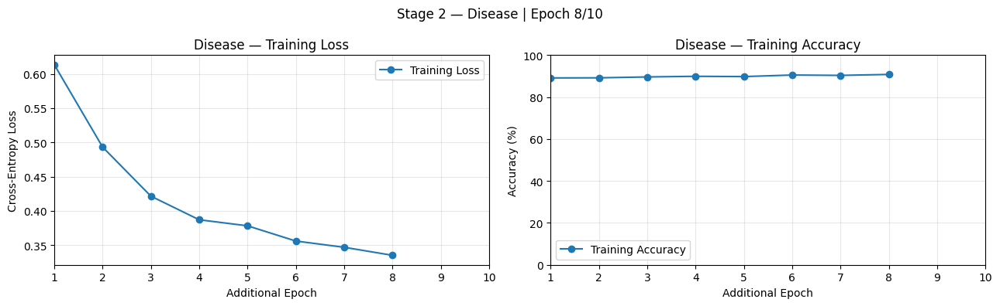

STAGE 2 DISEASE | Epoch 9/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 9/10 | Train Accuracy: 91.17% | Train Loss: 0.3290


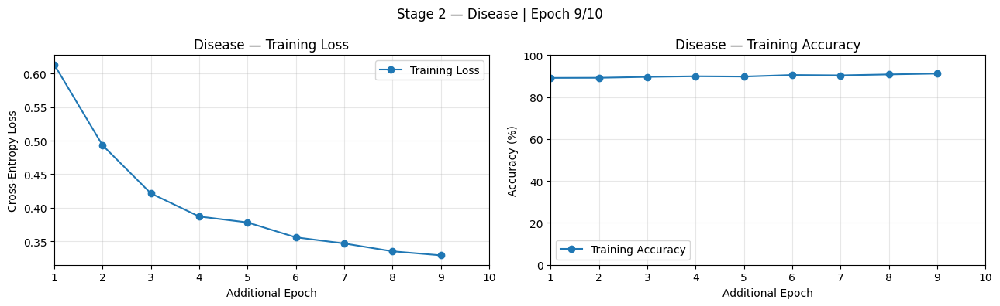

STAGE 2 DISEASE | Epoch 10/10:   0%|          | 0/500 [00:00<?, ?it/s]

STAGE 2 DISEASE | Epoch 10/10 | Train Accuracy: 90.64% | Train Loss: 0.3337


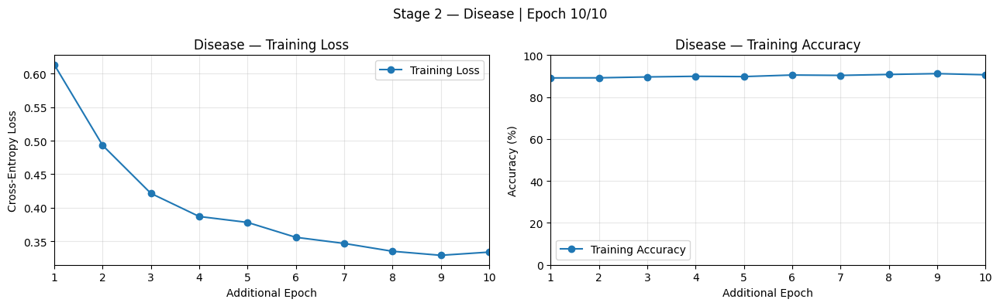


DISEASE STAGE 2 COMPLETED
Final Checkpoint: /content/drive/MyDrive/AML_B1_ResNet50/stage2_full8000/disease/final_epoch10.pt
Training History: /content/drive/MyDrive/AML_B1_ResNet50/stage2_full8000/disease/history.csv
Training Curves: /content/drive/MyDrive/AML_B1_ResNet50/stage2_full8000/disease/stage2_training_curves.png

Stage 2 completed.
Official Test: NOT PERFORMED


In [ ]:
if RUN_STAGE2:

    # Load original 8,000 training images
    original = find_child(DRIVE_PROJECT, 'DPD_Small_train.csv')
    full_df = read_original_training(original)

    expected_files = (
        set(train_df.filename)
        | set(val_seen_df.filename)
        | set(val_unseen_df.filename)
    )

    assert len(full_df) == 8000
    assert set(full_df.filename) == expected_files
    assert not (set(full_df.filename) - set(image_lookup))

    for task in ('crop', 'disease'):

        folder = STAGE2_ROOT / task
        folder.mkdir(parents=True, exist_ok=True)

        final_path = folder / f'final_epoch{STAGE2_EPOCHS}.pt'

        # Prevent accidental overwriting
        assert not final_path.exists(), (
            f'Stage 2 already exists: {final_path}'
        )
        assert not (folder / 'history.csv').exists(), (
            f'Partial Stage 2 run exists: {folder}'
        )

        print(f'\n{"=" * 55}')
        print(f'STAGE 2 — {task.upper()} FULL-DATA FINE-TUNING')
        print(f'Images: {len(full_df)}')
        print(f'Epochs: {STAGE2_EPOCHS}')
        print(f'{"=" * 55}')

        # Load Stage 1 best checkpoint
        start_ckpt = torch.load(
            RESULTS_ROOT / task / 'best.pt',
            map_location='cpu',
            weights_only=False
        )

        net = build_model(task, pretrained=False)
        net.load_state_dict(start_ckpt['state_dict'])

        # Stage 2 configuration
        cfg = dict(CONFIGS[task])
        cfg.update(
            backbone_lr=STAGE2_BACKBONE_LR,
            head_lr=STAGE2_HEAD_LR,
            epochs=STAGE2_EPOCHS,
            stage='full8000',
            source_epoch=start_ckpt['epoch']
        )

        (folder / 'config.json').write_text(
            json.dumps(cfg, indent=2)
        )

        optimizer = make_optimizer(net, cfg)

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=STAGE2_EPOCHS
        )

        scaler = torch.amp.GradScaler('cuda', enabled=AMP)

        train_loader = make_loader(
            full_df,
            training=True,
            batch_size=BATCH_SIZE
        )

        history = []

        # Stage 2 training
        for epoch in range(1, STAGE2_EPOCHS + 1):

            metrics = train_epoch(
                net,
                train_loader,
                task,
                optimizer,
                scaler,
                f'STAGE 2 {task.upper()} | Epoch {epoch}/{STAGE2_EPOCHS}'
            )

            scheduler.step()

            history.append({
                'epoch': epoch,
                'train_loss': metrics['loss'],
                'train_acc': metrics['acc']
            })

            # Save training history after each epoch
            df = pd.DataFrame(history)

            df.to_csv(
                folder / 'history.csv',
                index=False
            )

            # Save checkpoint after each epoch
            checkpoint_path = folder / f'epoch_{epoch:02d}.pt'

            save_atomic(
                snapshot(
                    net,
                    task,
                    epoch,
                    'stage2_fixed_epoch_not_validation_selected',
                    metrics['acc']
                ),
                checkpoint_path
            )

            print(
                f'STAGE 2 {task.upper()} | '
                f'Epoch {epoch}/{STAGE2_EPOCHS} | '
                f'Train Accuracy: {metrics["acc"]:.2%} | '
                f'Train Loss: {metrics["loss"]:.4f}',
                flush=True
            )

            # Display updated training graphs after every epoch
            fig, axes = plt.subplots(1, 2, figsize=(13, 4))

            axes[0].plot(
                df['epoch'],
                df['train_loss'],
                marker='o',
                label='Training Loss'
            )

            axes[0].set_title(f'{task.title()} — Training Loss')
            axes[0].set_xlabel('Additional Epoch')
            axes[0].set_ylabel('Cross-Entropy Loss')
            axes[0].set_xlim(1, max(2, STAGE2_EPOCHS))
            axes[0].grid(alpha=0.3)
            axes[0].legend()

            axes[1].plot(
                df['epoch'],
                df['train_acc'] * 100,
                marker='o',
                label='Training Accuracy'
            )

            axes[1].set_title(f'{task.title()} — Training Accuracy')
            axes[1].set_xlabel('Additional Epoch')
            axes[1].set_ylabel('Accuracy (%)')
            axes[1].set_xlim(1, max(2, STAGE2_EPOCHS))
            axes[1].set_ylim(0, 100)
            axes[1].grid(alpha=0.3)
            axes[1].legend()

            fig.suptitle(
                f'Stage 2 — {task.title()} | '
                f'Epoch {epoch}/{STAGE2_EPOCHS}'
            )

            fig.tight_layout()

            # Save each epoch's graph separately
            fig.savefig(
                folder / f'training_curves_epoch_{epoch:02d}.png',
                dpi=150,
                bbox_inches='tight'
            )

            # Update latest training curves
            fig.savefig(
                folder / 'stage2_training_curves.png',
                dpi=150,
                bbox_inches='tight'
            )

            display(fig)
            plt.close(fig)

        # Save final Stage 2 checkpoint
        shutil.copy2(
            folder / f'epoch_{STAGE2_EPOCHS:02d}.pt',
            final_path
        )

        print(f'\n{task.upper()} STAGE 2 COMPLETED')
        print(f'Final Checkpoint: {final_path}')
        print(f'Training History: {folder / "history.csv"}')
        print(f'Training Curves: {folder / "stage2_training_curves.png"}')

        # Release memory before training next task
        del net, optimizer, scheduler, scaler, train_loader
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print('\nStage 2 completed.')
    print('Official Test: NOT PERFORMED')

else:
    print('Stage 2 not run. Set RUN_STAGE2 = True to enable.')


## 21 — Final audit / run checklist

- **Sections 1–12**: prepare data, inspect transformations, configure and define functions. No training yet.
- **Sections 13–14**: new Stage 1 Crop and Disease training. Persistent per-epoch logs, 5-epoch progress graphs, loss-selected snapshots, HM-selected snapshots and resumable state.
- **Sections 15–19**: checkpoint policy comparison, DEVELOPMENT composition results, confusion matrices, error galleries, and transfer-ready manifest.
- **Section 20**: optional fixed-budget Stage 2 on 8,000 images; disabled. Keep separate from the development-selected transfer checkpoint.

**Output root:** `/content/drive/MyDrive/AML_B1_ResNet50_Higher_Decay_Clean_Retrain/`

This notebook does **not** invent Official Test metrics and does **not** inspect the Official Test labels. If a runtime disconnects, re-run setup and the appropriate training cell to resume. Make sure Google Drive storage is adequate before training. The Run/Resume checkpoint contains optimizer state and is substantially larger than weights-only checkpoints.

**Methodology caveat:** `best_val_loss.pt` is a plausible early transfer candidate—not a mathematically proven boundary before overfitting. Select after reviewing seen/unseen loss trajectories and coordinate with the downstream team. To study a stricter stopping strategy, evaluate the candidate snapshots on a separate development holdout (not the official test).
- **Full precision:** all 60 per-epoch archives remain native FP32 without loss of precision; full-model `best.pt`, `early_transfer.pt`, and optimizer resume checkpoints are saved separately.


In [28]:

# STAGE 3 — OFFICIAL TEST DATASET PREPARATION

OFFICIAL_ROOT = RESULTS_ROOT / 'stage3_official_test'
OFFICIAL_ROOT.mkdir(parents=True, exist_ok=True)

# Set exact paths here only if automatic detection fails
OFFICIAL_SEEN_CSV = None
OFFICIAL_UNSEEN_CSV = None


def find_official_csv(split, manual_path=None):
    if manual_path is not None:
        path = Path(manual_path)
        assert path.is_file(), f'CSV not found: {path}'
        return path

    candidates = []

    for path in DRIVE_PROJECT.rglob('*.csv'):
        name = path.stem.lower().replace('-', '_')
        parts = name.split('_')

        if 'test' not in parts:
            continue

        if split == 'seen':
            matched = 'seen' in parts and 'unseen' not in parts
        else:
            matched = 'unseen' in parts

        if matched:
            candidates.append(path)

    if len(candidates) != 1:
        print(f'\nCandidates for Official {split.title()} Test:')
        for path in candidates:
            print(' -', path)

        raise FileNotFoundError(
            f'Expected one Official {split} Test CSV. '
            'Set its exact path manually above.'
        )

    return candidates[0]


official_seen_path = find_official_csv(
    'seen', OFFICIAL_SEEN_CSV
)

official_unseen_path = find_official_csv(
    'unseen', OFFICIAL_UNSEEN_CSV
)

official_seen_df = read_original_training(official_seen_path)
official_unseen_df = read_original_training(official_unseen_path)

official_tests = {
    'seen': official_seen_df,
    'unseen': official_unseen_df
}

# Check dataset sizes
assert len(official_seen_df) == 2000
assert len(official_unseen_df) == 1448

# Verify no overlap with original training images
training_files = set(train_df['filename']) | (
    set(val_seen_df['filename'])
) | set(val_unseen_df['filename'])

seen_files = set(official_seen_df['filename'])
unseen_files = set(official_unseen_df['filename'])

assert len(seen_files) == len(official_seen_df)
assert len(unseen_files) == len(official_unseen_df)

assert training_files.isdisjoint(seen_files)
assert training_files.isdisjoint(unseen_files)
assert seen_files.isdisjoint(unseen_files)

# Verify all test images and class IDs are available
for split, table in official_tests.items():
    assert all(
        str(name) in image_lookup
        for name in table['filename']
    ), f'Missing images in Official {split} Test'

    assert set(table['crop_id'].astype(int)).issubset(set(crop_ids))
    assert set(table['disease_id'].astype(int)).issubset(set(disease_ids))

    # Ensure composition IDs do not affect model evaluation
    print(
        f'Official {split.title()} Test: '
        f'{len(table)} images | '
        f'{table[["crop_id", "disease_id"]].drop_duplicates().shape[0]} '
        f'compositions'
    )

print('\nOfficial Test datasets ready.')
print('Training and test image sets are disjoint.')


Official Seen Test: 2000 images | 323 compositions
Official Unseen Test: 1448 images | 10 compositions

Official Test datasets ready.
Training and test image sets are disjoint.



OFFICIAL SEEN TEST — 2000 IMAGES


Official seen | crop:   0%|          | 0/63 [00:00<?, ?it/s]

Official seen | disease:   0%|          | 0/63 [00:00<?, ?it/s]


OFFICIAL SEEN TEST RESULTS
Crop Top-1:        88.15%
Disease Top-1:     64.30%
Composition Top-1: 61.35%
Composition Top-5: 82.90%

OFFICIAL UNSEEN TEST — 1448 IMAGES


Official unseen | crop:   0%|          | 0/46 [00:00<?, ?it/s]

Official unseen | disease:   0%|          | 0/46 [00:00<?, ?it/s]


OFFICIAL UNSEEN TEST RESULTS
Crop Top-1:        67.96%
Disease Top-1:     8.29%
Composition Top-1: 4.35%
Composition Top-5: 15.33%

OFFICIAL TEST — ACCURACY SUMMARY


,Test Split,Images,Crop Top-1 (%),Disease Top-1 (%),Composition Top-1 (%),Composition Top-5 (%),Crop Loss,Disease Loss
0,Seen,2000,88.15,64.30,61.35,82.90,0.57,1.76
1,Unseen,1448,67.96,8.29,4.35,15.33,1.84,7.55



OFFICIAL TEST — SEEN/UNSEEN HARMONIC MEAN


,Crop HM (%),Disease HM (%),Composition HM (%)
0,76.75,14.68,8.13


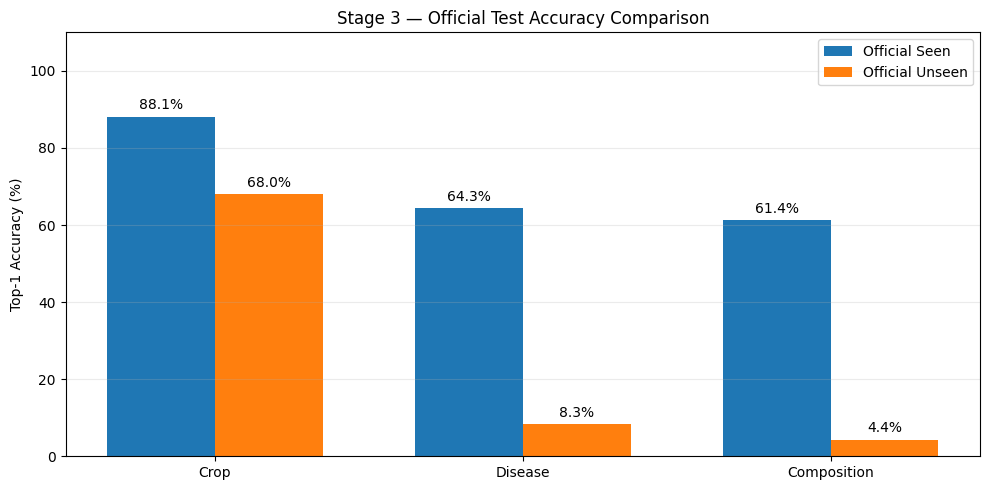


Official Test evaluation completed.
Results saved: /content/drive/MyDrive/AML_B1_ResNet50/stage3_official_test


In [29]:
# STAGE 3 — OFFICIAL TEST EVALUATION

@torch.no_grad()
def evaluate_official_model(task, table, split):

    checkpoint_path = (
        STAGE2_ROOT / task / f'final_epoch{STAGE2_EPOCHS}.pt'
    )

    assert checkpoint_path.exists(), (
        f'Missing Stage 2 checkpoint: {checkpoint_path}'
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location='cpu',
        weights_only=False
    )

    model = build_model(task, pretrained=False)
    model.load_state_dict(checkpoint['state_dict'])
    model = model.to(DEVICE)
    model.eval()

    loader = make_loader(
        table,
        training=False,
        batch_size=32
    )

    all_log_probs = []
    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for images, crop_targets, disease_targets in tqdm(
        loader,
        desc=f'Official {split} | {task}',
        leave=True
    ):

        images = images.to(DEVICE)

        targets = (
            crop_targets if task == 'crop'
            else disease_targets
        ).to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=AMP
        ):
            logits = model(images)

        logits = logits.float()

        total_loss += F.cross_entropy(
            logits, targets, reduction='sum'
        ).item()

        total_correct += (
            logits.argmax(dim=1) == targets
        ).sum().item()

        total_images += len(targets)

        log_probs = F.log_softmax(logits, dim=1)

        all_log_probs.append(
            log_probs.cpu().numpy()
        )

    log_probs = np.concatenate(all_log_probs).astype(np.float32)

    result = {
        'loss': total_loss / total_images,
        'accuracy': total_correct / total_images,
        'log_probs': log_probs
    }

    del model, loader
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


official_predictions = {}
summary_rows = []

for split, table in official_tests.items():

    print(f'\n{"=" * 60}')
    print(f'OFFICIAL {split.upper()} TEST — {len(table)} IMAGES')
    print(f'{"=" * 60}')

    crop_result = evaluate_official_model(
        'crop', table, split
    )

    disease_result = evaluate_official_model(
        'disease', table, split
    )

    crop_log_probs = crop_result['log_probs']
    disease_log_probs = disease_result['log_probs']

    n_crop = len(crop_ids)
    n_disease = len(disease_ids)

    # Independent CNN predictions
    pred_crop_idx = crop_log_probs.argmax(axis=1)
    pred_disease_idx = disease_log_probs.argmax(axis=1)

    data = table.copy().reset_index(drop=True)

    data['pred_crop'] = np.asarray(crop_ids)[pred_crop_idx]
    data['pred_disease'] = np.asarray(disease_ids)[pred_disease_idx]

    data['crop_correct'] = (
        data['pred_crop'] == data['crop_id']
    )

    data['disease_correct'] = (
        data['pred_disease'] == data['disease_id']
    )

    data['composition_correct'] = (
        data['crop_correct'] & data['disease_correct']
    )

    # Calculate composition Top-5 in small batches
    top5_correct = np.zeros(len(data), dtype=bool)

    true_pair_idx = np.array([
        crop_index[int(c)] * n_disease + disease_index[int(d)]
        for c, d in zip(data['crop_id'], data['disease_id'])
    ])

    for start in range(0, len(data), 64):
        end = min(start + 64, len(data))

        scores = (
            crop_log_probs[start:end, :, None]
            + disease_log_probs[start:end, None, :]
        ).reshape(-1, n_crop * n_disease)

        top5_idx = np.argpartition(
            -scores, kth=4, axis=1
        )[:, :5]

        top5_correct[start:end] = (
            top5_idx == true_pair_idx[start:end, None]
        ).any(axis=1)

    data['composition_top5_correct'] = top5_correct

    # Save detailed image-level predictions
    official_predictions[split] = data

    data.to_csv(
        OFFICIAL_ROOT / f'official_{split}_predictions.csv',
        index=False
    )

    crop_acc = data['crop_correct'].mean()
    disease_acc = data['disease_correct'].mean()
    comp_acc = data['composition_correct'].mean()
    comp_top5 = data['composition_top5_correct'].mean()

    summary_rows.append({
        'Test Split': split.title(),
        'Images': len(data),
        'Crop Top-1 (%)': crop_acc * 100,
        'Disease Top-1 (%)': disease_acc * 100,
        'Composition Top-1 (%)': comp_acc * 100,
        'Composition Top-5 (%)': comp_top5 * 100,
        'Crop Loss': crop_result['loss'],
        'Disease Loss': disease_result['loss']
    })

    print(f'\nOFFICIAL {split.upper()} TEST RESULTS')
    print(f'Crop Top-1:        {crop_acc:.2%}')
    print(f'Disease Top-1:     {disease_acc:.2%}')
    print(f'Composition Top-1: {comp_acc:.2%}')
    print(f'Composition Top-5: {comp_top5:.2%}')


# Summary table
official_summary = pd.DataFrame(summary_rows)

seen = official_summary.iloc[0]
unseen = official_summary.iloc[1]

official_hm = pd.DataFrame([{
    'Crop HM (%)': harmonic(
        seen['Crop Top-1 (%)'] / 100,
        unseen['Crop Top-1 (%)'] / 100
    ) * 100,

    'Disease HM (%)': harmonic(
        seen['Disease Top-1 (%)'] / 100,
        unseen['Disease Top-1 (%)'] / 100
    ) * 100,

    'Composition HM (%)': harmonic(
        seen['Composition Top-1 (%)'] / 100,
        unseen['Composition Top-1 (%)'] / 100
    ) * 100
}])

official_summary.to_csv(
    OFFICIAL_ROOT / 'official_test_summary.csv',
    index=False
)

official_hm.to_csv(
    OFFICIAL_ROOT / 'official_test_harmonic_mean.csv',
    index=False
)

print('\nOFFICIAL TEST — ACCURACY SUMMARY')
display(official_summary.round(2))

print('\nOFFICIAL TEST — SEEN/UNSEEN HARMONIC MEAN')
display(official_hm.round(2))


# Accuracy comparison graph
labels = ['Crop', 'Disease', 'Composition']
x = np.arange(len(labels))
width = 0.35

seen_values = [
    seen['Crop Top-1 (%)'],
    seen['Disease Top-1 (%)'],
    seen['Composition Top-1 (%)']
]

unseen_values = [
    unseen['Crop Top-1 (%)'],
    unseen['Disease Top-1 (%)'],
    unseen['Composition Top-1 (%)']
]

fig, ax = plt.subplots(figsize=(10, 5))

bars_seen = ax.bar(
    x - width / 2, seen_values,
    width, label='Official Seen'
)

bars_unseen = ax.bar(
    x + width / 2, unseen_values,
    width, label='Official Unseen'
)

ax.bar_label(bars_seen, fmt='%.1f%%', padding=3)
ax.bar_label(bars_unseen, fmt='%.1f%%', padding=3)

ax.set_xticks(x, labels)
ax.set_ylabel('Top-1 Accuracy (%)')
ax.set_ylim(0, 110)
ax.set_title('Stage 3 — Official Test Accuracy Comparison')
ax.legend()
ax.grid(axis='y', alpha=0.25)

fig.tight_layout()
fig.savefig(
    OFFICIAL_ROOT / 'official_test_accuracy_comparison.png',
    dpi=160
)

display(fig)
plt.close(fig)

print('\nOfficial Test evaluation completed.')
print('Results saved:', OFFICIAL_ROOT)


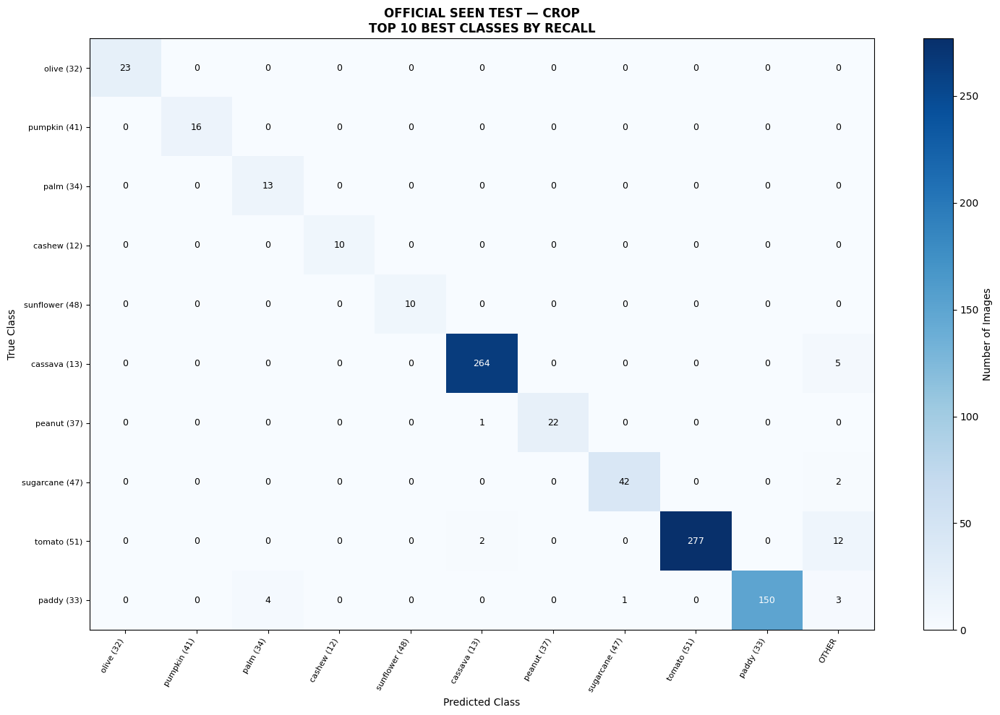


SEEN — CROP — BEST


,class_name,support,TP,FN,recall
true_key,,,,,
32,olive (32),23,23,0,1.000
41,pumpkin (41),16,16,0,1.000
34,palm (34),13,13,0,1.000
12,cashew (12),10,10,0,1.000
48,sunflower (48),10,10,0,1.000
13,cassava (13),269,264,5,0.981
37,peanut (37),23,22,1,0.957
47,sugarcane (47),44,42,2,0.955
51,tomato (51),291,277,14,0.952


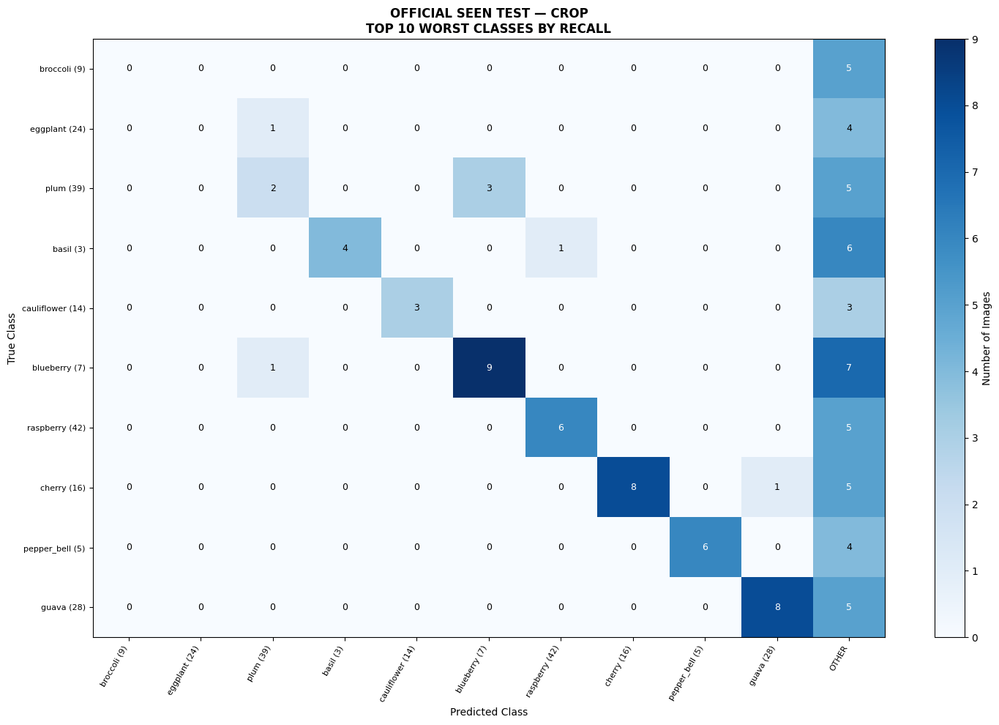


SEEN — CROP — WORST


,class_name,support,TP,FN,recall
true_key,,,,,
9,broccoli (9),5,0,5,0.000
24,eggplant (24),5,0,5,0.000
39,plum (39),10,2,8,0.200
3,basil (3),11,4,7,0.364
14,cauliflower (14),6,3,3,0.500
7,blueberry (7),17,9,8,0.529
42,raspberry (42),11,6,5,0.545
16,cherry (16),14,8,6,0.571
5,pepper_bell (5),10,6,4,0.600


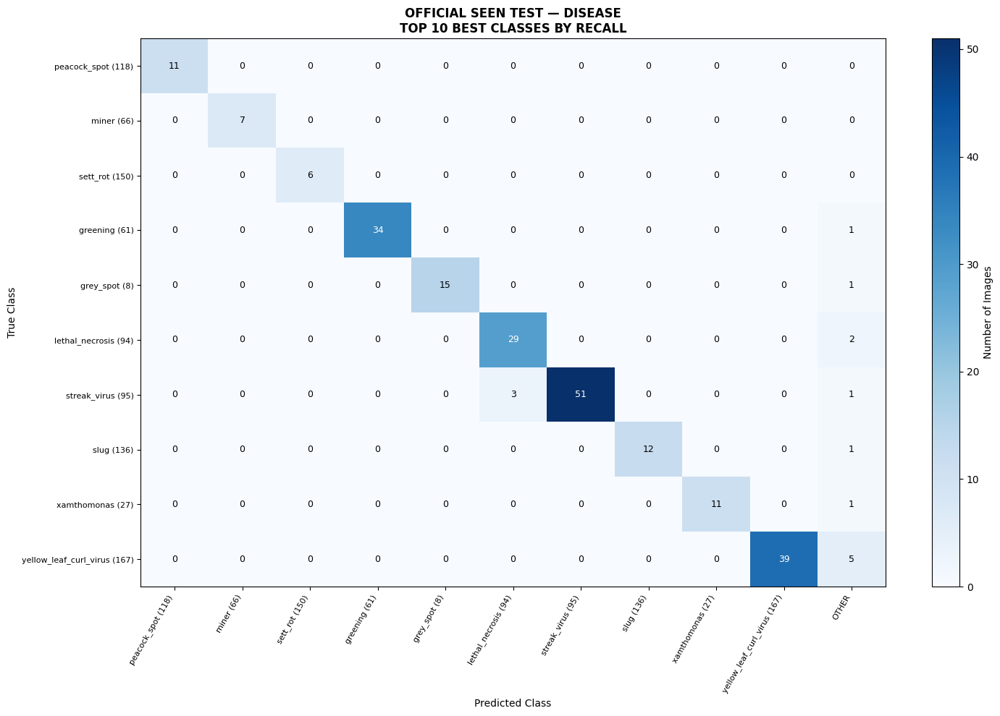


SEEN — DISEASE — BEST


,class_name,support,TP,FN,recall
true_key,,,,,
118,peacock_spot (118),11,11,0,1.000
66,miner (66),7,7,0,1.000
150,sett_rot (150),6,6,0,1.000
61,greening (61),35,34,1,0.971
8,grey_spot (8),16,15,1,0.938
94,lethal_necrosis (94),31,29,2,0.935
95,streak_virus (95),55,51,4,0.927
136,slug (136),13,12,1,0.923
27,xamthomonas (27),12,11,1,0.917


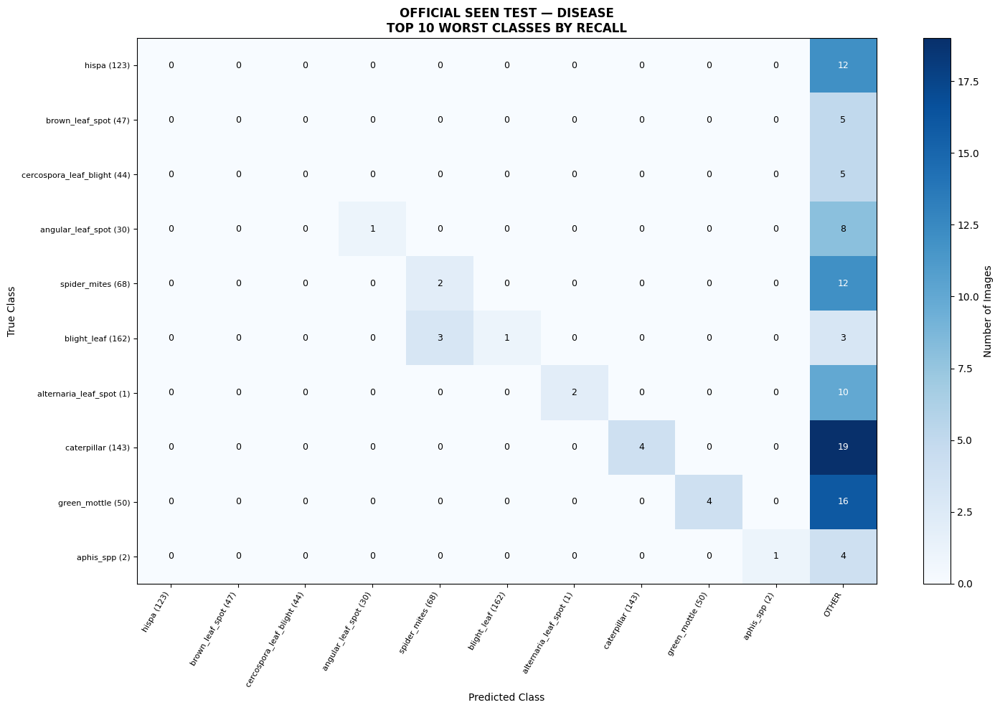


SEEN — DISEASE — WORST


,class_name,support,TP,FN,recall
true_key,,,,,
123,hispa (123),12,0,12,0.000
47,brown_leaf_spot (47),5,0,5,0.000
44,cercospora_leaf_blight (44),5,0,5,0.000
30,angular_leaf_spot (30),9,1,8,0.111
68,spider_mites (68),14,2,12,0.143
162,blight_leaf (162),7,1,6,0.143
1,alternaria_leaf_spot (1),12,2,10,0.167
143,caterpillar (143),23,4,19,0.174
50,green_mottle (50),20,4,16,0.200


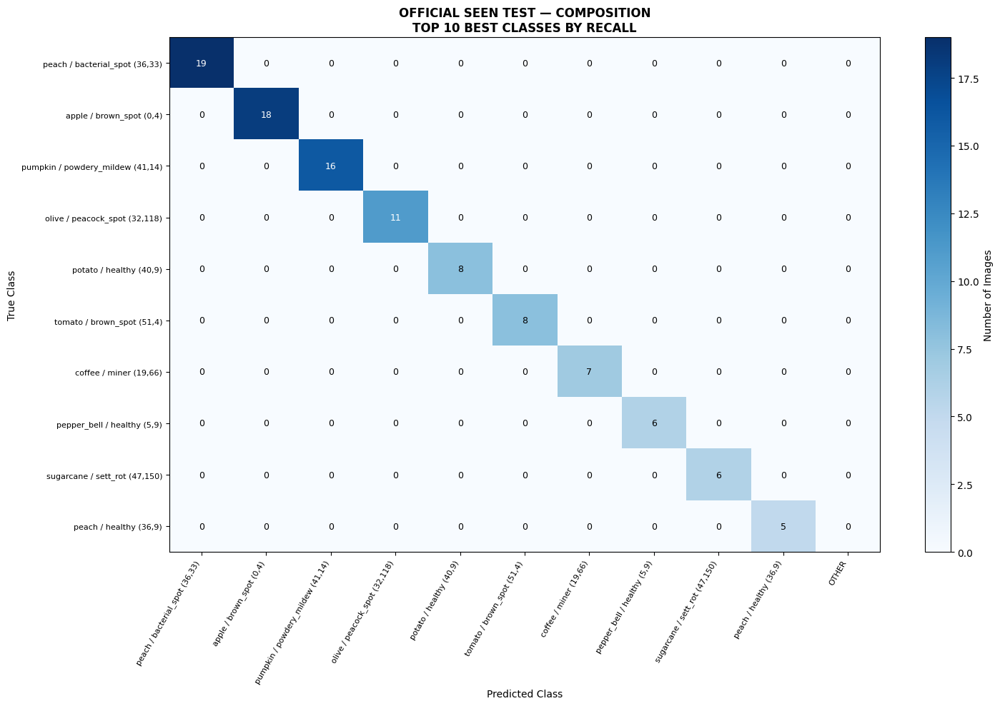


SEEN — COMPOSITION — BEST


,class_name,support,TP,FN,recall
true_key,,,,,
36|33,"peach / bacterial_spot (36,33)",19,19,0,1.0
0|4,"apple / brown_spot (0,4)",18,18,0,1.0
41|14,"pumpkin / powdery_mildew (41,14)",16,16,0,1.0
32|118,"olive / peacock_spot (32,118)",11,11,0,1.0
40|9,"potato / healthy (40,9)",8,8,0,1.0
51|4,"tomato / brown_spot (51,4)",8,8,0,1.0
19|66,"coffee / miner (19,66)",7,7,0,1.0
5|9,"pepper_bell / healthy (5,9)",6,6,0,1.0
47|150,"sugarcane / sett_rot (47,150)",6,6,0,1.0


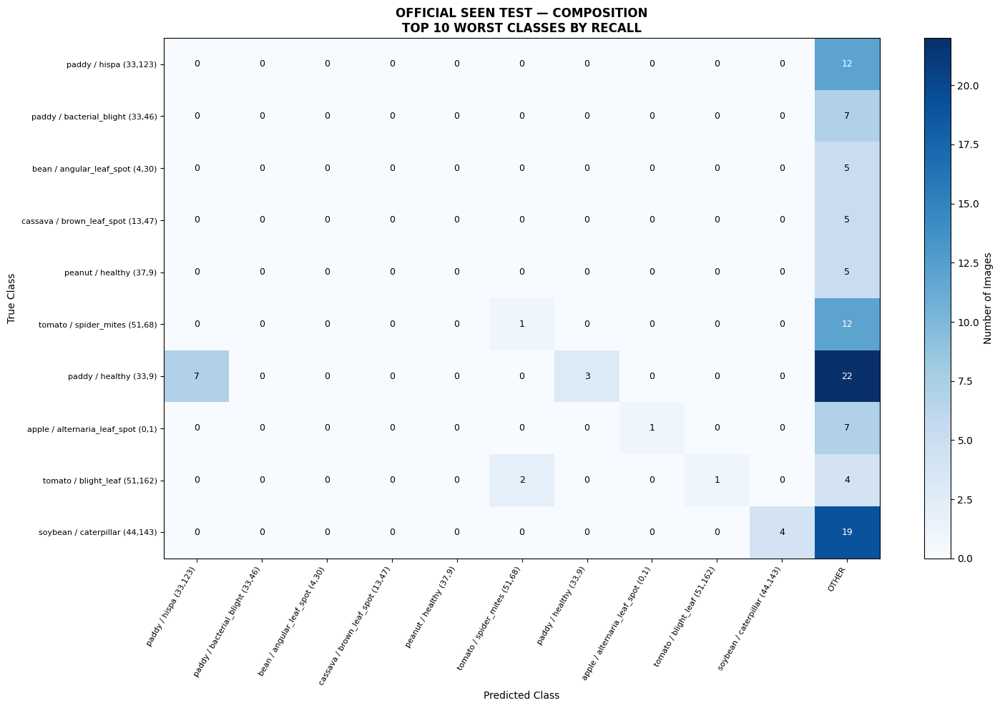


SEEN — COMPOSITION — WORST


,class_name,support,TP,FN,recall
true_key,,,,,
33|123,"paddy / hispa (33,123)",12,0,12,0.000
33|46,"paddy / bacterial_blight (33,46)",7,0,7,0.000
4|30,"bean / angular_leaf_spot (4,30)",5,0,5,0.000
13|47,"cassava / brown_leaf_spot (13,47)",5,0,5,0.000
37|9,"peanut / healthy (37,9)",5,0,5,0.000
51|68,"tomato / spider_mites (51,68)",13,1,12,0.077
33|9,"paddy / healthy (33,9)",32,3,29,0.094
0|1,"apple / alternaria_leaf_spot (0,1)",8,1,7,0.125
51|162,"tomato / blight_leaf (51,162)",7,1,6,0.143


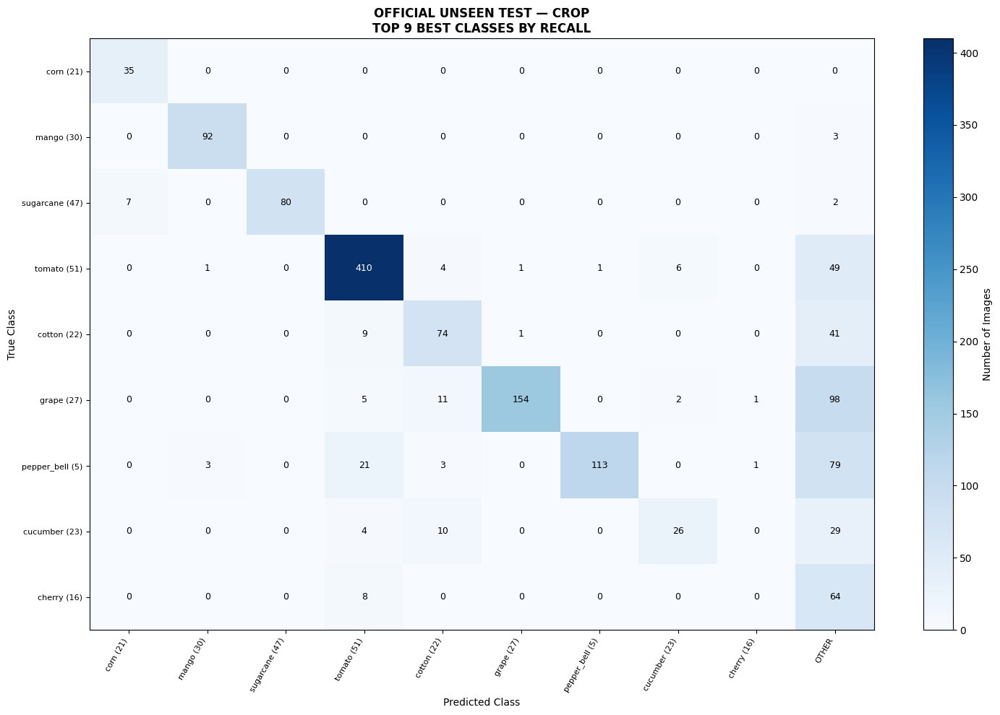


UNSEEN — CROP — BEST


,class_name,support,TP,FN,recall
true_key,,,,,
21,corn (21),35,35,0,1.000
30,mango (30),95,92,3,0.968
47,sugarcane (47),89,80,9,0.899
51,tomato (51),472,410,62,0.869
22,cotton (22),125,74,51,0.592
27,grape (27),271,154,117,0.568
5,pepper_bell (5),220,113,107,0.514
23,cucumber (23),69,26,43,0.377
16,cherry (16),72,0,72,0.000


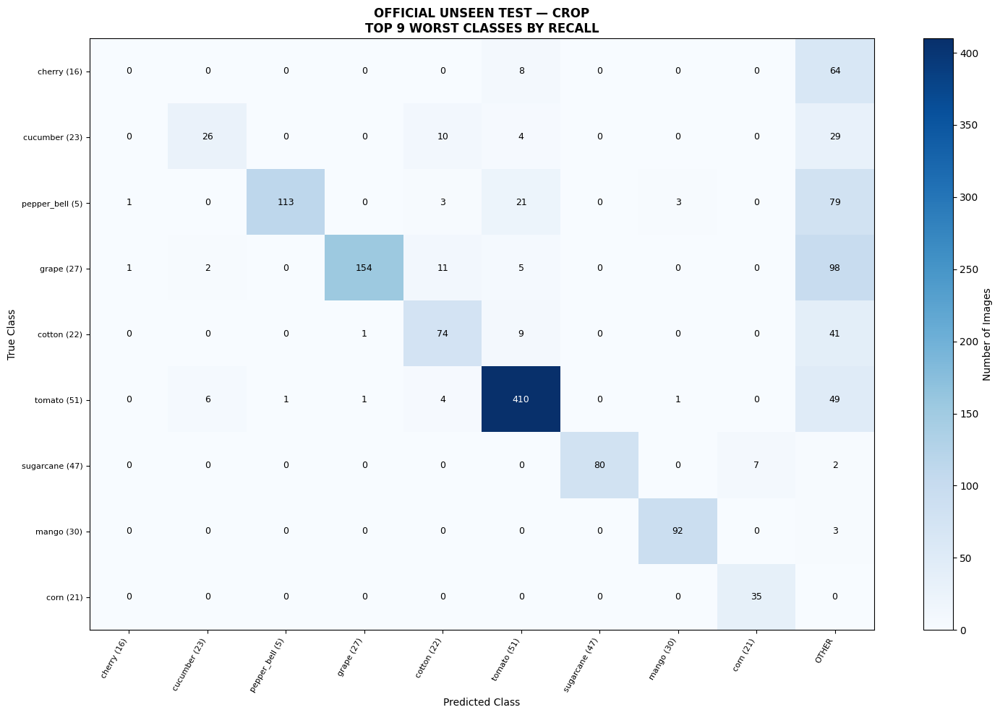


UNSEEN — CROP — WORST


,class_name,support,TP,FN,recall
true_key,,,,,
16,cherry (16),72,0,72,0.000
23,cucumber (23),69,26,43,0.377
5,pepper_bell (5),220,113,107,0.514
27,grape (27),271,154,117,0.568
22,cotton (22),125,74,51,0.592
51,tomato (51),472,410,62,0.869
47,sugarcane (47),89,80,9,0.899
30,mango (30),95,92,3,0.968
21,corn (21),35,35,0,1.000


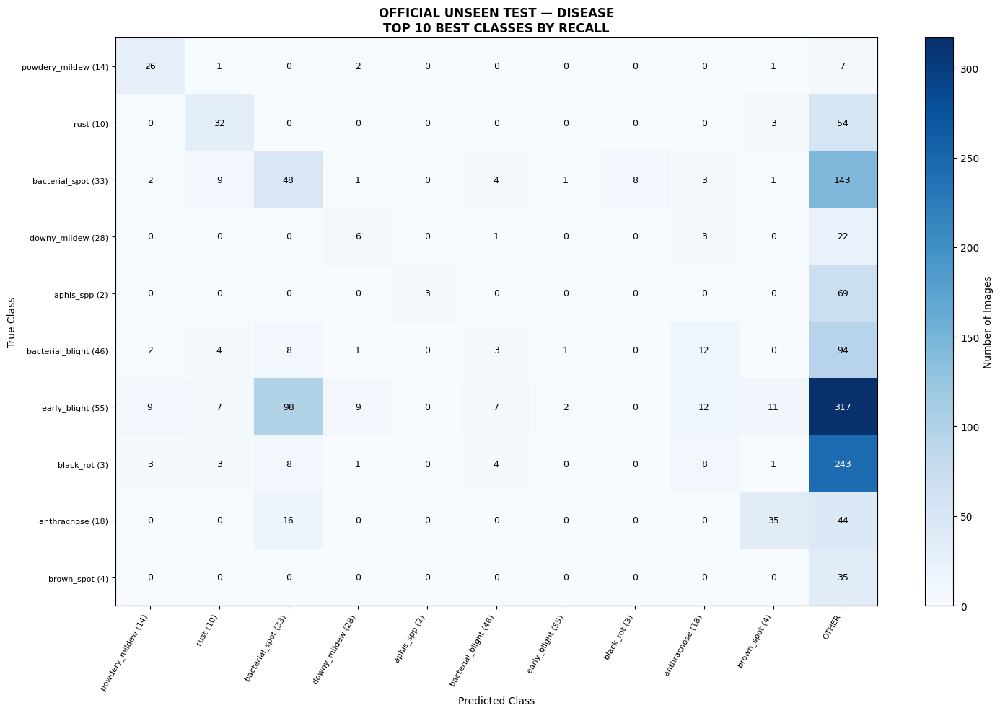


UNSEEN — DISEASE — BEST


,class_name,support,TP,FN,recall
true_key,,,,,
14,powdery_mildew (14),37,26,11,0.703
10,rust (10),89,32,57,0.360
33,bacterial_spot (33),220,48,172,0.218
28,downy_mildew (28),32,6,26,0.188
2,aphis_spp (2),72,3,69,0.042
46,bacterial_blight (46),125,3,122,0.024
55,early_blight (55),472,2,470,0.004
3,black_rot (3),271,0,271,0.000
18,anthracnose (18),95,0,95,0.000


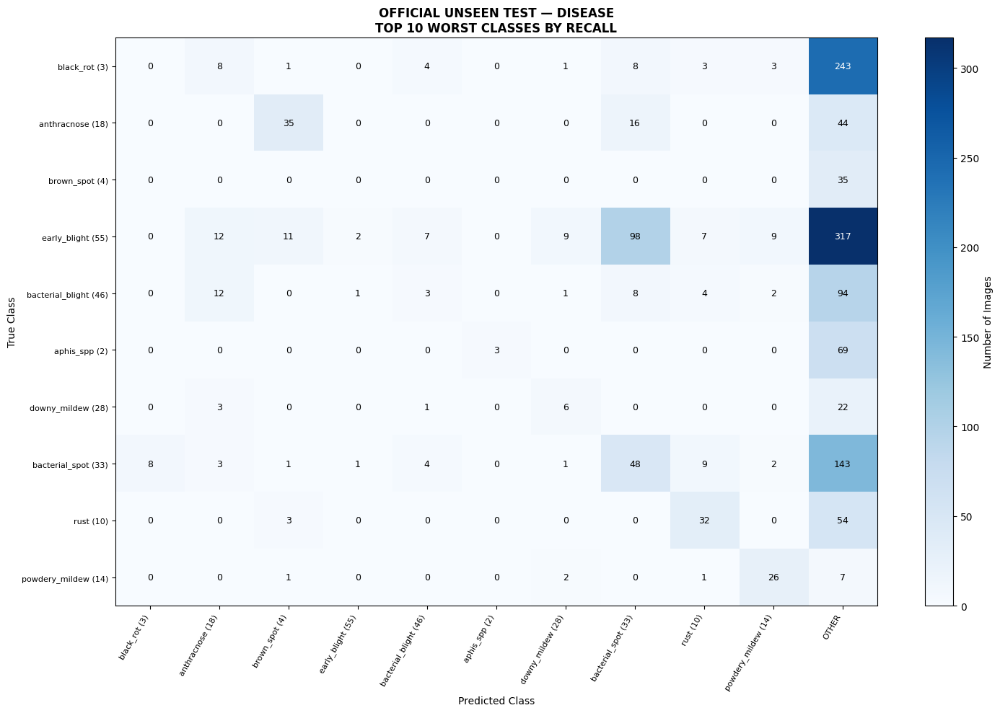


UNSEEN — DISEASE — WORST


,class_name,support,TP,FN,recall
true_key,,,,,
3,black_rot (3),271,0,271,0.000
18,anthracnose (18),95,0,95,0.000
4,brown_spot (4),35,0,35,0.000
55,early_blight (55),472,2,470,0.004
46,bacterial_blight (46),125,3,122,0.024
2,aphis_spp (2),72,3,69,0.042
28,downy_mildew (28),32,6,26,0.188
33,bacterial_spot (33),220,48,172,0.218
10,rust (10),89,32,57,0.360


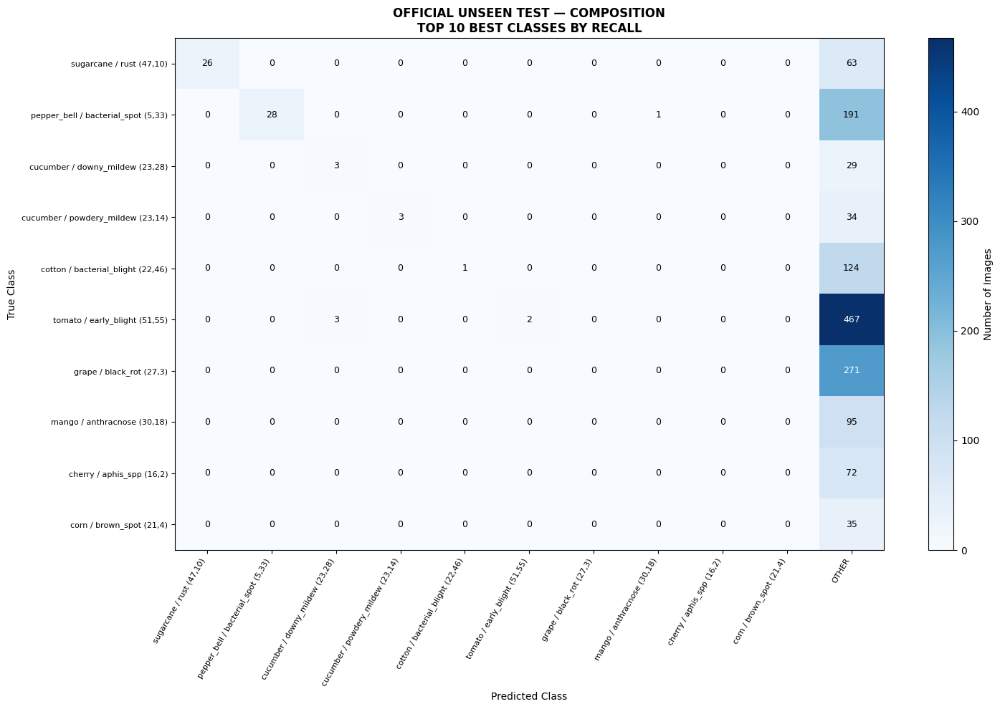


UNSEEN — COMPOSITION — BEST


,class_name,support,TP,FN,recall
true_key,,,,,
47|10,"sugarcane / rust (47,10)",89,26,63,0.292
5|33,"pepper_bell / bacterial_spot (5,33)",220,28,192,0.127
23|28,"cucumber / downy_mildew (23,28)",32,3,29,0.094
23|14,"cucumber / powdery_mildew (23,14)",37,3,34,0.081
22|46,"cotton / bacterial_blight (22,46)",125,1,124,0.008
51|55,"tomato / early_blight (51,55)",472,2,470,0.004
27|3,"grape / black_rot (27,3)",271,0,271,0.000
30|18,"mango / anthracnose (30,18)",95,0,95,0.000
16|2,"cherry / aphis_spp (16,2)",72,0,72,0.000


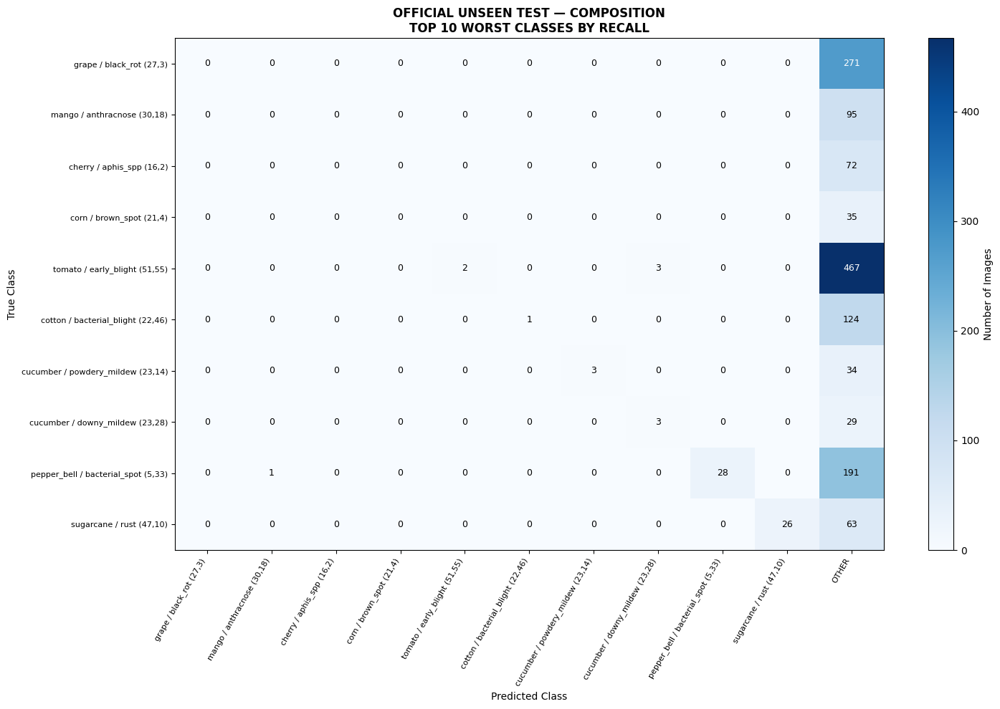


UNSEEN — COMPOSITION — WORST


,class_name,support,TP,FN,recall
true_key,,,,,
27|3,"grape / black_rot (27,3)",271,0,271,0.000
30|18,"mango / anthracnose (30,18)",95,0,95,0.000
16|2,"cherry / aphis_spp (16,2)",72,0,72,0.000
21|4,"corn / brown_spot (21,4)",35,0,35,0.000
51|55,"tomato / early_blight (51,55)",472,2,470,0.004
22|46,"cotton / bacterial_blight (22,46)",125,1,124,0.008
23|14,"cucumber / powdery_mildew (23,14)",37,3,34,0.081
23|28,"cucumber / downy_mildew (23,28)",32,3,29,0.094
5|33,"pepper_bell / bacterial_spot (5,33)",220,28,192,0.127



Official Test Confusion Matrices saved to:
/content/drive/MyDrive/AML_B1_ResNet50/stage3_official_test/confusion_matrices/best_worst


In [31]:

# ============================================================
# STAGE 3 — OFFICIAL TEST CONFUSION MATRICES
# BEST 10 / WORST 10 CLASSES WITH READABLE NAMES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from IPython.display import display

TOP_N = 10
MIN_SUPPORT = 5

cm_dir = OFFICIAL_ROOT / "confusion_matrices" / "best_worst"
cm_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Build class-name mappings
# ------------------------------------------------------------

name_sources = [
    df for df in [
        train_df,
        val_seen_df,
        val_unseen_df
    ]
    if isinstance(df, pd.DataFrame)
]

names_df = pd.concat(name_sources, ignore_index=True)

def build_name_map(id_col, name_col):
    if name_col not in names_df.columns:
        print(f"Warning: {name_col} not found. Using IDs.")
        return {}

    mapping = names_df[[id_col, name_col]].dropna()
    mapping = mapping.drop_duplicates(id_col)

    return dict(zip(
        mapping[id_col].astype(int),
        mapping[name_col].astype(str)
    ))

crop_names = build_name_map("crop_id", "crop_name")
disease_names = build_name_map("disease_id", "disease_name")


def readable_label(key, task):

    if task == "crop":
        c = int(key)
        return f"{crop_names.get(c, f'Crop {c}')} ({c})"

    if task == "disease":
        d = int(key)
        return f"{disease_names.get(d, f'Disease {d}')} ({d})"

    c, d = map(int, key.split("|"))

    crop = crop_names.get(c, f"Crop {c}")
    disease = disease_names.get(d, f"Disease {d}")

    return f"{crop} / {disease} ({c},{d})"


def prepare_confusion_data(df, task):

    data = df.copy()

    if task == "crop":
        data["true_key"] = data["crop_id"].astype(int).astype(str)
        data["pred_key"] = data["pred_crop"].astype(int).astype(str)

    elif task == "disease":
        data["true_key"] = data["disease_id"].astype(int).astype(str)
        data["pred_key"] = data["pred_disease"].astype(int).astype(str)

    elif task == "composition":
        data["true_key"] = (
            data["crop_id"].astype(int).astype(str)
            + "|"
            + data["disease_id"].astype(int).astype(str)
        )
        data["pred_key"] = (
            data["pred_crop"].astype(int).astype(str)
            + "|"
            + data["pred_disease"].astype(int).astype(str)
        )

    return data


def plot_official_confusion(df, split, task, ranking):

    data = prepare_confusion_data(df, task)

    # -----------------------------------------------
    # Full confusion counts (all observed classes)
    # -----------------------------------------------

    full_counts = (
        data.groupby(["true_key", "pred_key"])
        .size()
        .reset_index(name="count")
    )

    full_counts.to_csv(
        cm_dir / f"{split}_{task}_full_counts.csv",
        index=False
    )

    # -----------------------------------------------
    # Per-class recall
    # -----------------------------------------------

    support = data["true_key"].value_counts()

    correct = data.loc[
        data["true_key"] == data["pred_key"],
        "true_key"
    ].value_counts()

    report = pd.DataFrame({"support": support})

    report["TP"] = correct.reindex(
        report.index, fill_value=0
    )

    report["FN"] = report["support"] - report["TP"]
    report["recall"] = report["TP"] / report["support"]

    report["class_name"] = [
        readable_label(key, task)
        for key in report.index
    ]

    report.to_csv(
        cm_dir / f"{split}_{task}_per_class_recall.csv",
        index_label="class_key"
    )

    # Exclude classes with very few images
    eligible = report.loc[
        report["support"] >= MIN_SUPPORT
    ].copy()

    if eligible.empty:
        print(f"No eligible classes: {split} {task}")
        return

    # -----------------------------------------------
    # Select best / worst classes
    # -----------------------------------------------

    if ranking == "best":
        selected_report = eligible.sort_values(
            ["recall", "support", "class_name"],
            ascending=[False, False, True]
        ).head(TOP_N)

    else:
        selected_report = eligible.sort_values(
            ["recall", "support", "class_name"],
            ascending=[True, False, True]
        ).head(TOP_N)

    selected_keys = selected_report.index.tolist()

    subset = data.loc[
        data["true_key"].isin(selected_keys)
    ].copy()

    # -----------------------------------------------
    # Selected-class confusion + OTHER column
    # -----------------------------------------------

    matrix = pd.crosstab(
        subset["true_key"],
        subset["pred_key"]
    )

    compact = matrix.reindex(
        index=selected_keys,
        columns=selected_keys,
        fill_value=0
    )

    other_counts = (
        subset.groupby("true_key").size()
        .reindex(selected_keys, fill_value=0)
        - compact.sum(axis=1)
    )

    compact["OTHER"] = other_counts

    assert compact.to_numpy().sum() == len(subset)

    y_labels = [
        readable_label(k, task)
        for k in selected_keys
    ]

    x_labels = y_labels + ["OTHER"]

    compact.index = y_labels
    compact.columns = x_labels

    compact.to_csv(
        cm_dir / f"{split}_{task}_{ranking}_top10_counts.csv"
    )

    selected_report.to_csv(
        cm_dir / f"{split}_{task}_{ranking}_top10_recall.csv",
        index_label="class_key"
    )

    # -----------------------------------------------
    # Plot
    # -----------------------------------------------

    values = compact.to_numpy()

    fig, ax = plt.subplots(figsize=(15, 10))

    im = ax.imshow(
        values,
        cmap="Blues",
        aspect="auto",
        interpolation="nearest"
    )

    fig.colorbar(
        im, ax=ax,
        label="Number of Images"
    )

    ax.set_xticks(range(len(x_labels)))
    ax.set_yticks(range(len(y_labels)))

    ax.set_xticklabels(
        x_labels, rotation=60,
        ha="right", fontsize=8
    )

    ax.set_yticklabels(
        y_labels, fontsize=8
    )

    maximum = values.max()

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):

            count = int(values[i, j])

            ax.text(
                j, i, str(count),
                ha="center",
                va="center",
                fontsize=9,
                color=(
                    "white"
                    if maximum > 0 and count > maximum / 2
                    else "black"
                )
            )

    ax.set_title(
        f"OFFICIAL {split.upper()} TEST — {task.upper()}\n"
        f"TOP {len(selected_keys)} {ranking.upper()} "
        f"CLASSES BY RECALL",
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

    fig.tight_layout()

    fig.savefig(
        cm_dir / f"{split}_{task}_{ranking}_top10.png",
        dpi=200,
        bbox_inches="tight"
    )

    display(fig)
    plt.close(fig)

    print(f"\n{split.upper()} — {task.upper()} — {ranking.upper()}")

    display(
        selected_report[
            ["class_name", "support", "TP", "FN", "recall"]
        ].round(3)
    )


# ============================================================
# GENERATE ALL OFFICIAL CONFUSION MATRICES
# ============================================================

for split, data in official_predictions.items():

    for task in ["crop", "disease", "composition"]:

        for ranking in ["best", "worst"]:

            plot_official_confusion(
                data, split, task, ranking
            )

print("\nOfficial Test Confusion Matrices saved to:")
print(cm_dir)


In [32]:
# ============================================================
# BUILD CLASS ID -> CLASS NAME LOOKUP
# ============================================================

name_df = pd.concat(
    [train_df, val_seen_df, val_unseen_df],
    ignore_index=True
)

crop_name_map = (
    name_df[["crop_id", "crop_name"]]
    .drop_duplicates("crop_id")
    .set_index("crop_id")["crop_name"]
    .to_dict()
)

disease_name_map = (
    name_df[["disease_id", "disease_name"]]
    .drop_duplicates("disease_id")
    .set_index("disease_id")["disease_name"]
    .to_dict()
)

def crop_label(crop_id):
    crop_id = int(crop_id)
    return crop_name_map.get(crop_id, f"Crop ID {crop_id}")

def disease_label(disease_id):
    disease_id = int(disease_id)
    return disease_name_map.get(
        disease_id, f"Disease ID {disease_id}"
    )

print("Crop names loaded:", len(crop_name_map))
print("Disease names loaded:", len(disease_name_map))

Crop names loaded: 55
Disease names loaded: 175



OFFICIAL SEEN TEST — ERROR ANALYSIS
Total Images: 2000
Composition Errors: 773

Error Type Distribution:


,Error Type,Images
0,Both Correct,1227
1,Disease Wrong Only,536
2,Both Wrong,178
3,Crop Wrong Only,59


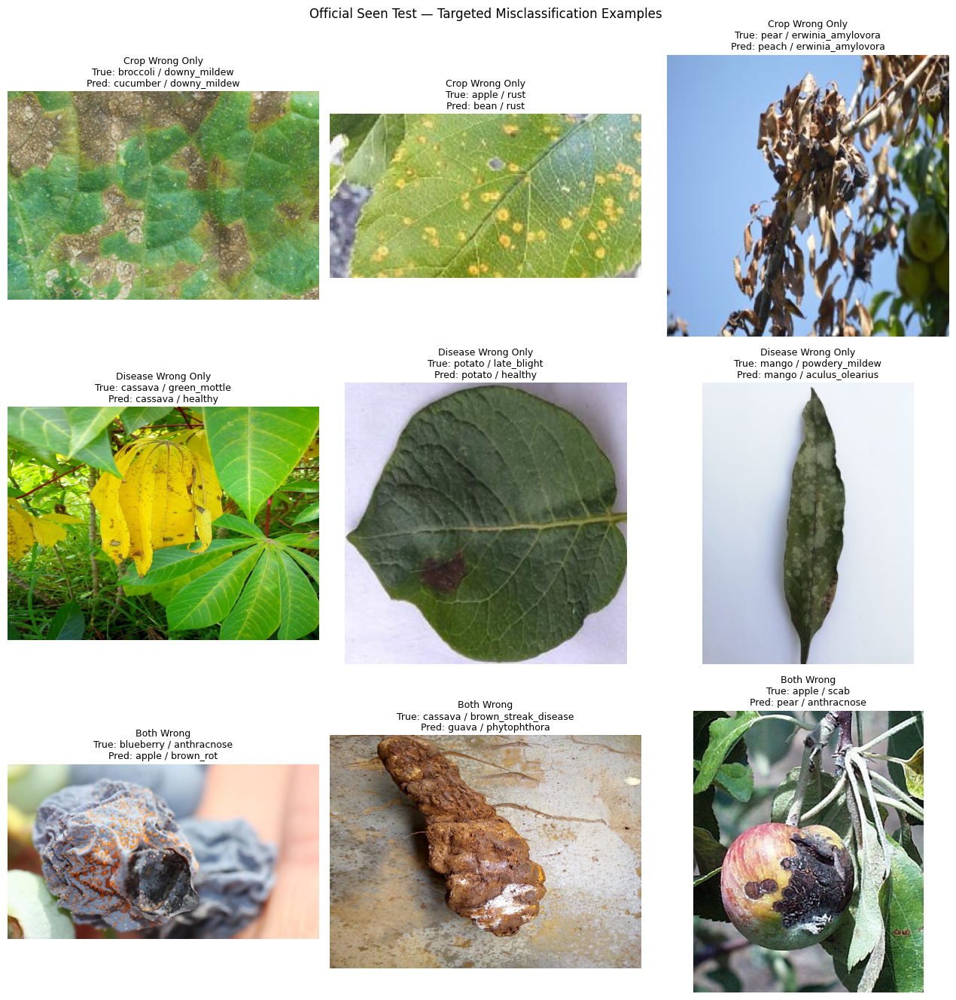


OFFICIAL UNSEEN TEST — ERROR ANALYSIS
Total Images: 1448
Composition Errors: 1385

Error Type Distribution:


,Error Type,Images
0,Disease Wrong Only,921
1,Both Wrong,407
2,Both Correct,63
3,Crop Wrong Only,57


Predicted Training-Seen Pair Rate: 61.12%
Among Incorrect Predictions: 63.90%


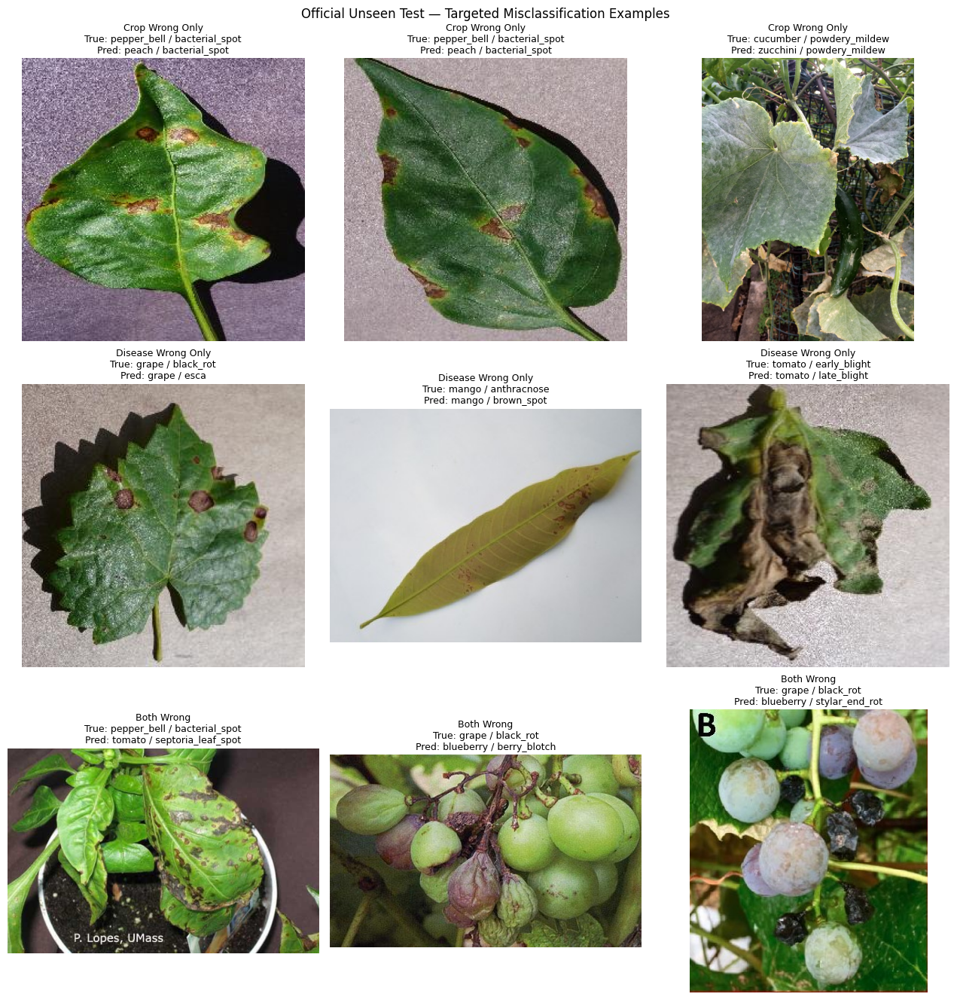


OFFICIAL TEST — ERROR SUMMARY


,Test Split,Images,Crop Wrong Only,Disease Wrong Only,Both Wrong,Composition Errors,Predicted Seen Pair (%)
0,Seen,2000,59,536,178,773,87.10
1,Unseen,1448,57,921,407,1385,61.12



Saved Official Test error analysis: /content/drive/MyDrive/AML_B1_ResNet50/stage3_official_test/misclassifications


In [33]:

# STAGE 3 — OFFICIAL TEST MISCLASSIFICATION ANALYSIS

from PIL import Image as PILImage

error_dir = OFFICIAL_ROOT / 'misclassifications'
error_dir.mkdir(parents=True, exist_ok=True)

train_pairs = set(zip(
    train_df['crop_id'].astype(int),
    train_df['disease_id'].astype(int)
))

error_summary = []

for split, df in official_predictions.items():

    data = df.copy()

    predicted_pairs = list(zip(
        data['pred_crop'].astype(int),
        data['pred_disease'].astype(int)
    ))

    data['predicted_seen_pair'] = [
        pair in train_pairs for pair in predicted_pairs
    ]

    data['error_type'] = np.select(
        [
            data['crop_correct'] & data['disease_correct'],
            ~data['crop_correct'] & data['disease_correct'],
            data['crop_correct'] & ~data['disease_correct']
        ],
        [
            'Both Correct',
            'Crop Wrong Only',
            'Disease Wrong Only'
        ],
        default='Both Wrong'
    )

    mistakes = data.loc[
        ~data['composition_correct']
    ].copy()

    mistakes.to_csv(
        error_dir / f'official_{split}_misclassifications.csv',
        index=False
    )

    print(f'\nOFFICIAL {split.upper()} TEST — ERROR ANALYSIS')
    print(f'Total Images: {len(data)}')
    print(f'Composition Errors: {len(mistakes)}')

    print('\nError Type Distribution:')
    counts = data['error_type'].value_counts()

    display(
        counts.rename_axis('Error Type')
        .reset_index(name='Images')
    )

    if split == 'unseen':
        print(
            'Predicted Training-Seen Pair Rate:',
            f'{data["predicted_seen_pair"].mean():.2%}'
        )

        print(
            'Among Incorrect Predictions:',
            f'{mistakes["predicted_seen_pair"].mean():.2%}'
            if len(mistakes) else 'N/A'
        )

    # Select up to 3 images from each error category
    samples = []

    for error_type in [
        'Crop Wrong Only',
        'Disease Wrong Only',
        'Both Wrong'
    ]:
        subset = mistakes[
            mistakes['error_type'] == error_type
        ]

        if not subset.empty:
            samples.append(
                subset.sample(
                    n=min(3, len(subset)),
                    random_state=SEED
                )
            )

    if samples:
        gallery = pd.concat(samples).reset_index(drop=True)

        columns = 3
        rows = int(np.ceil(len(gallery) / columns))

        fig, axes = plt.subplots(
            rows, columns,
            figsize=(13, 4.5 * rows)
        )

        axes = np.atleast_1d(axes).ravel()

        for ax, (_, row) in zip(axes, gallery.iterrows()):

            with PILImage.open(
                image_lookup[str(row['filename'])]
            ) as image:
                ax.imshow(image.convert('RGB'))

            ax.set_title(
                f'{row["error_type"]}\n'
                f'True: {crop_label(row["crop_id"])} / '
                f'{disease_label(row["disease_id"])}\n'
                f'Pred: {crop_label(row["pred_crop"])} / '
                f'{disease_label(row["pred_disease"])}',
                fontsize=9,
                wrap=True
            )

            ax.axis('off')

        for ax in axes[len(gallery):]:
            ax.axis('off')

        fig.suptitle(
            f'Official {split.title()} Test — '
            'Targeted Misclassification Examples'
        )

        fig.tight_layout()

        fig.savefig(
            error_dir / f'official_{split}_error_gallery.png',
            dpi=160,
            bbox_inches='tight'
        )

        display(fig)
        plt.close(fig)

    error_summary.append({
        'Test Split': split.title(),
        'Images': len(data),
        'Crop Wrong Only': int(
            (data['error_type'] == 'Crop Wrong Only').sum()
        ),
        'Disease Wrong Only': int(
            (data['error_type'] == 'Disease Wrong Only').sum()
        ),
        'Both Wrong': int(
            (data['error_type'] == 'Both Wrong').sum()
        ),
        'Composition Errors': len(mistakes),
        'Predicted Seen Pair (%)': (
            data['predicted_seen_pair'].mean() * 100
        )
    })

official_error_summary = pd.DataFrame(error_summary)

official_error_summary.to_csv(
    error_dir / 'official_error_summary.csv',
    index=False
)

print('\nOFFICIAL TEST — ERROR SUMMARY')
display(official_error_summary.round(2))

print('\nSaved Official Test error analysis:', error_dir)
